# [16.5] Shapley Interactions (exercises)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part5_shapley_interactions/16.5_Shapley_Interactions_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part5_shapley_interactions/16.5_Shapley_Interactions_solutions.ipynb)**

> **Prediction practice: [start the guided workbook](../../../mastery_hub/units/extension_predictions/exercises.ipynb#section-16-5) before viewing this lesson's results.**
> Record a forecast, confidence and reasoning, then compare controls and predict a changed case. These reference-rich lessons support guided practice; prior exposure is not scored as unseen mastery.

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-13-2.png" width="350">

# Introduction

What does an interaction score mean, and how much evidence does it cost to estimate it? Work through three complete studies: pair SII in a known game, allocation of omitted high-order credit, and shared-query estimators. Each retains its own definition, protocol, controls and exploration.

## Historical reference and execution boundary

The 79 actual solution output records and 22 figures are retained historical reference material. This is not a fresh scientific execution. Historical 16.3, 16.16 and16.17 remain exact source identities; canonical 16.5 combines their complete curricula. Original source trees, protocols, source IDs, seeds, model/checkpoint identities, output paths and review records remain preserved.

One toy signature was originally saved only as an asset. Its new expected display is explicitly separate from the 79 historical output records. Exercises have unexecuted stubs and expected HTML figures only; historical actual counts/outputs belong to solutions. Commit numerical forecasts, confidence, mechanism and prior exposure before reading reference results. No learner responses or acceptance are fabricated.

Known Concrete predictors and the same 758 training, 153 explanation and 119 audit rows recur across native definition and estimator studies. They are not independent model discoveries or new evaluation cohorts. Pair indices, masks, donors, contexts, seeds and sampling replicates have different denominators. Preserve recipe-group weighting and every audit boundary. Background changes alter the game; conditional sampling SE is not uncertainty about training or a population.

External model/data/tensor cache availability is unprobed. Full reproduction requires the original pinned source data and complete retained source-visible computations; a JSON report or source hash is not a replacement for numerical arrays. Executing the notebooks still runs their original loading, training, package-reference and study code. Import-safe generated Python guards do not disable notebook work. This migration did not run any loader, model, estimator, study, retraining play, GPU or download.

## Content & Learning Objectives

Implement exact pair interactions and diagnose main-effect failure; compare efficient Shapley–Taylor and exact constrained Faith-Shap while keeping SII distinct; estimate every pair under fully charged shared-query plans and compare all controls. Preserve mathematical targets and adverse findings rather than choosing a winning method.

# 1️⃣ Pair interactions in a complete game

## [16.3] Shapley Interactions with shapiq - Solutions

> **Claim.** By the end of this notebook, you will have shown that exact second-order Shapley interaction indices recover a planted pair that individual Shapley rankings miss, expose how a three-way dividend enters pairwise scores, return zero for a matched additive game, converge under permutation sampling, and match pinned `shapiq` on the same complete coalition table.

```yaml
GT_TIER = "GT-0"
EXERCISE_ID = "16_3_shapley_interactions_with_shapiq"
expected_runtime: 75-105 minutes on CPU
requires_gpu: false for the lesson; true only for the separate release preflight
```

## Core Question

Can pairwise SII recover a planted synergy that individual Shapley rankings miss, while matched additive and permuted-value controls fail?

## Cold open

Consider a controlled fraud score with four binary features. `high_amount` contributes `5.0` alone and `many_attempts` contributes `4.0`. `new_device` and `foreign_login` contribute only `0.2` each, but together receive an extra `3.0`; when `high_amount` is also present, the triple receives another `2.0`.

| question | answer known before coding |
|---|---:|
| Largest individual Shapley value | `high_amount = 5.667` |
| Strongest pairwise SII | `new_device x foreign_login` |
| Exact target-pair SII | `4.0 = 3.0 pair + 1.0 from the triple` |
| Largest interaction in the matched additive control | `0.0` |

The falsifiable question is: **can pairwise SII recover the planted pair despite larger additive decoys, while revealing rather than hiding the contribution of a known three-way term?**

## Original study objectives

- Enumerate a complete finite coalition game from transparent polynomial terms.
- Implement the discrete second difference that removes additive contributions.
- Derive and implement exact pairwise Shapley interaction indices.
- Compare interaction structure with individual Shapley main effects.
- Estimate pair interactions from random merged-player permutations.
- Build a within-size coalition-value permutation control.
- Match the complete-table result against pinned `shapiq` SII.
- Quantify target rank, off-target interactions, and matrix error.

In [ ]:
import itertools as toy_itertools

import math as toy_math

import random as toy_random

import sys as toy_sys

from collections.abc import Mapping as toy_Mapping

from dataclasses import dataclass

from pathlib import Path as toy_Path

import matplotlib.pyplot as toy_plt

import numpy as toy_np

import pandas as toy_pd

import torch as toy_t

toy_chapter = 'chapter16_shapley_attribution_baselines'

section = 'part3_shapley_interactions_shapiq'

toy_root_dir = next((p for p in [toy_Path.cwd(), *toy_Path.cwd().parents] if (p / toy_chapter).exists()))

exercises_dir = toy_root_dir / toy_chapter / 'exercises'

section_dir = exercises_dir / section

assets_dir = toy_root_dir / toy_chapter / 'instructions' / 'assets'

if str(toy_root_dir) not in toy_sys.path:
    toy_sys.path.append(str(toy_root_dir))

if str(exercises_dir) not in toy_sys.path:
    toy_sys.path.append(str(exercises_dir))

import chapter16_shapley_attribution_baselines.exercises.part3_shapley_interactions_shapiq.tests as toy_tests

Coalition = frozenset[int]

@dataclass(frozen=True)
class InteractionRecoveryReport:
    predicted_pair: tuple[int, int]
    target_rank: int
    target_value: float
    max_off_target_interaction: float
    mean_abs_error: float

PLAYER_NAMES = ['new_device', 'foreign_login', 'high_amount', 'many_attempts']

NUM_PLAYERS = len(PLAYER_NAMES)

TARGET_PAIR = (0, 1)

ADDITIVE_WEIGHTS = toy_t.tensor([0.2, 0.2, 5.0, 4.0], dtype=toy_t.float64)

PAIR_WEIGHT = 3.0

TRIPLE = (0, 1, 2)

TRIPLE_WEIGHT = 2.0

## The exact game

For binary coalition indicators $x_i \in \{0,1\}$, the primary game is

$$v(x)=0.2x_0+0.2x_1+5x_2+4x_3+3x_0x_1+2x_0x_1x_2.$$

Every one of the $2^4=16$ coalition values is enumerable. We know before computing anything that the literal pair contributes `3.0`, while the three-way dividend contributes another `1.0` to each of `(0,1)`, `(0,2)`, and `(1,2)` under second-order SII. Therefore the exact target matrix has `I(0,1)=4.0`, `I(0,2)=I(1,2)=1.0`, and zero elsewhere. The matched additive control removes both interaction terms while preserving the large individual effects.

This is the ground truth used throughout the lesson and in the later `shapiq` comparison.

### Exercise 1 - implement `all_coalitions and polynomial_game`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> Suggested time: 12 minutes
> ```

Enumerate every subset of the player set, normalize coalition keys, and evaluate additive plus higher-order terms on each coalition.

**Common bug:** Omitting the empty coalition, or adding an interaction term only when the coalition equals the term rather than contains it.

<details>
<summary>Expected output</summary>

```text
coalitions: 16; v({0,1}) = 3.4; v({0,1,2}) = 10.4; v(full) = 14.4
All tests in `test_polynomial_game_enumerates_exact_ground_truth` passed!
```

</details>

<details>
<summary>Help - derive the contract before coding</summary>

Iterate coalition sizes from zero through `num_players`. A polynomial term contributes whenever its player set is a subset of the current coalition.

</details>

<details>
<summary>Interpretation</summary>

The empty coalition fixes the baseline. The full table includes a literal pair term and a known three-way term, so later pairwise scores have an exact contextual interpretation rather than a post-hoc story.

</details>

## Forecast before running — toy-4

Before enumerating, predict the number of coalition rows and which dividends survive in each row.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def all_coalitions(num_players: int) -> tuple[Coalition, ...]:
    raise NotImplementedError()


def normalize_coalition_values(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], *, num_players: int) -> dict[Coalition, float]:
    raise NotImplementedError()


def polynomial_game(additive_weights: toy_t.Tensor, interaction_terms: toy_Mapping[Coalition | tuple[int, ...], float]) -> dict[Coalition, float]:
    raise NotImplementedError()


toy_tests.test_polynomial_game_enumerates_exact_ground_truth(polynomial_game)

<details><summary>Solution</summary>

```python
def all_coalitions(num_players: int) -> tuple[Coalition, ...]:
    if num_players <= 0:
        raise ValueError('num_players must be positive.')
    return tuple((frozenset(group) for size in range(num_players + 1) for group in toy_itertools.combinations(range(num_players), size)))


def normalize_coalition_values(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], *, num_players: int) -> dict[Coalition, float]:
    values = {frozenset(key): float(value) for key, value in coalition_values.items()}
    missing = set(all_coalitions(num_players)) - set(values)
    if missing:
        raise ValueError(f'coalition table is missing {len(missing)} coalitions.')
    return values


def polynomial_game(additive_weights: toy_t.Tensor, interaction_terms: toy_Mapping[Coalition | tuple[int, ...], float]) -> dict[Coalition, float]:
    weights = additive_weights.flatten().double()
    num_players = int(weights.numel())
    if num_players <= 0:
        raise ValueError('additive_weights must contain at least one player.')
    terms = {frozenset(term): float(value) for term, value in interaction_terms.items()}
    for term in terms:
        if len(term) < 2:
            raise ValueError('interaction terms must contain at least two players.')
        if min(term) < 0 or max(term) >= num_players:
            raise ValueError('interaction term contains an invalid player index.')
    values: dict[Coalition, float] = {}
    for coalition in all_coalitions(num_players):
        additive = weights[list(coalition)].sum().item() if coalition else 0.0
        interaction = sum((value for term, value in terms.items() if term <= coalition))
        values[coalition] = additive + interaction
    return values

toy_tests.test_polynomial_game_enumerates_exact_ground_truth(polynomial_game)
```
</details>

## Reflect after the result — toy-4

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

### Exercise 2 - implement `discrete_second_difference`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> Suggested time: 10 minutes
> ```

For pair $(i,j)$ in context $S$, compute $v(S\cup\{i,j\})-v(S\cup\{i\})-v(S\cup\{j\})+v(S)$.

**Common bug:** Using only `v(S+i+j) - v(S)`, which includes both individual effects and badly overstates interaction.

<details>
<summary>Expected output</summary>

```text
target-pair delta: 3.0 without high_amount, 5.0 with high_amount
matched additive-control delta: 0.0 in every context
All tests in `test_discrete_second_difference_isolates_synergy_from_additive_effects` passed!
```

</details>

<details>
<summary>Help - derive the contract before coding</summary>

Write the four coalition lookups explicitly. Require the context to exclude both players, otherwise the subtraction no longer isolates joint contribution.

</details>

<details>
<summary>Interpretation</summary>

Additive terms cancel exactly. The jump from `3.0` to `5.0` when player 2 enters the context is direct evidence of the planted three-way term. SII will average these context-specific joint contributions.

</details>

## Forecast before running — toy-6

Predict the pair derivative with no context and with the missing member of the triple present.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def discrete_second_difference(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], coalition: Coalition | tuple[int, ...], pair: tuple[int, int], *, num_players: int) -> float:
    raise NotImplementedError()


toy_tests.test_discrete_second_difference_isolates_synergy_from_additive_effects(polynomial_game, discrete_second_difference)

<details><summary>Solution</summary>

```python
def discrete_second_difference(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], coalition: Coalition | tuple[int, ...], pair: tuple[int, int], *, num_players: int) -> float:
    values = normalize_coalition_values(coalition_values, num_players=num_players)
    context = frozenset(coalition)
    first, second = pair
    if first == second:
        raise ValueError('pair must contain two different players.')
    if not (0 <= first < num_players and 0 <= second < num_players):
        raise ValueError('pair contains an invalid player index.')
    if first in context or second in context:
        raise ValueError('coalition context must exclude both players in pair.')
    return values[context | {first, second}] - values[context | {first}] - values[context | {second}] + values[context]

toy_tests.test_discrete_second_difference_isolates_synergy_from_additive_effects(polynomial_game, discrete_second_difference)
```
</details>

## Reflect after the result — toy-6

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

For $n$ players, pairwise SII averages this second difference with

$$I_{ij}=\sum_{S\subseteq N\setminus\{i,j\}}\frac{|S|!(n-|S|-2)!}{(n-1)!}\Delta_{ij}v(S).$$

The weights are exactly the probabilities that $S$ appears before a merged $(i,j)$ player in a uniformly random permutation.

### Exercise 3 - implement `pairwise_shapley_interactions`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> Suggested time: 20 minutes
> ```

Loop over unordered pairs and valid context sizes, apply the factorial weight, and return a symmetric matrix with a zero diagonal.

**Common bug:** Using the ordinary Shapley denominator `n!`; the merged pair creates a game with `n-1` units, so the denominator is `(n-1)!`.

<details>
<summary>Expected output</summary>

```text
I(new_device, foreign_login) = 4.0; I(new_device, high_amount) = I(foreign_login, high_amount) = 1.0
All tests in `test_pairwise_sii_recovers_pair_hidden_by_large_additive_effects` passed!
```

</details>

<details>
<summary>Help - derive the contract before coding</summary>

For each pair there are `n-2` remaining players. Context sizes therefore run from zero through `n-2`, implemented as `range(n-1)`.

</details>

<details>
<summary>Interpretation</summary>

The target is strongest at `4.0`: its literal pair dividend contributes `3.0`, and half of the `2.0` triple dividend contributes `1.0`. The two other pairs inside the triple receive `1.0`; pairs involving only the additive player remain zero.

</details>

## Forecast before running — toy-9

Forecast pair ranking relative to large individual main effects; which additive control should give zero?

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def pairwise_shapley_interactions(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], *, num_players: int) -> toy_t.Tensor:
    raise NotImplementedError()


toy_tests.test_pairwise_sii_recovers_pair_hidden_by_large_additive_effects(polynomial_game, pairwise_shapley_interactions)

<details><summary>Solution</summary>

```python
def pairwise_shapley_interactions(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], *, num_players: int) -> toy_t.Tensor:
    values = normalize_coalition_values(coalition_values, num_players=num_players)
    interactions = toy_t.zeros((num_players, num_players), dtype=toy_t.float64)
    denominator = toy_math.factorial(num_players - 1)
    for first, second in toy_itertools.combinations(range(num_players), 2):
        others = [player for player in range(num_players) if player not in (first, second)]
        score = 0.0
        for size in range(num_players - 1):
            weight = toy_math.factorial(size) * toy_math.factorial(num_players - size - 2) / denominator
            for group in toy_itertools.combinations(others, size):
                score += weight * discrete_second_difference(values, frozenset(group), (first, second), num_players=num_players)
        interactions[first, second] = score
        interactions[second, first] = score
    return interactions

toy_tests.test_pairwise_sii_recovers_pair_hidden_by_large_additive_effects(polynomial_game, pairwise_shapley_interactions)
```
</details>

## Reflect after the result — toy-9

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

### Exercise 4 - implement `exact_shapley_values`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> Suggested time: 15 minutes
> ```

Implement exact first-order Shapley values on the same complete table, then compare their ranking with the pairwise interaction matrix.

**Common bug:** Calling the two largest individual Shapley values the strongest interaction. That inference is false in this exact game.

<details>
<summary>Expected output</summary>

```text
individual values: [2.3667, 2.3667, 5.6667, 4.0]; top two players: [2, 3]
All tests in `test_exact_shapley_values_make_main_effect_ranking_misleading` passed!
```

</details>

<details>
<summary>Help - derive the contract before coding</summary>

For one player, average its marginal contribution across predecessor coalitions using the ordinary `n!` Shapley weights.

</details>

<details>
<summary>Interpretation</summary>

Individual credit is not pair identification. The pair and triple dividends are divided among their members, yet players 0 and 1 still rank below the two additive decoys. Individual credit and interaction structure answer different questions.

</details>

## Forecast before running — toy-11

Predict which individual Shapley ranks disagree with the planted-pair membership.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def exact_shapley_values(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], *, num_players: int) -> toy_t.Tensor:
    raise NotImplementedError()


toy_tests.test_exact_shapley_values_make_main_effect_ranking_misleading(polynomial_game, exact_shapley_values)

<details><summary>Solution</summary>

```python
def exact_shapley_values(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], *, num_players: int) -> toy_t.Tensor:
    values = normalize_coalition_values(coalition_values, num_players=num_players)
    result = toy_t.zeros(num_players, dtype=toy_t.float64)
    denominator = toy_math.factorial(num_players)
    for player in range(num_players):
        others = [other for other in range(num_players) if other != player]
        for size in range(num_players):
            weight = toy_math.factorial(size) * toy_math.factorial(num_players - size - 1) / denominator
            for group in toy_itertools.combinations(others, size):
                coalition = frozenset(group)
                result[player] += weight * (values[coalition | {player}] - values[coalition])
    return result

toy_tests.test_exact_shapley_values_make_main_effect_ranking_misleading(polynomial_game, exact_shapley_values)
```
</details>

## Reflect after the result — toy-11

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

### Exercise 5 - implement `sampled_pair_interaction and permutation control`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> Suggested time: 20 minutes
> ```

Estimate SII by sampling random permutations of the `n-2` other players plus one merged pair marker. Also shuffle values only within coalition sizes to preserve easy marginals while destroying player identity.

**Common bug:** Sampling subsets uniformly. SII contexts are not uniform over subsets; merged-player permutations induce the factorial weights.

<details>
<summary>Expected output</summary>

```text
contextual exact target SII: 4.0; budget-4096 seed-0 estimate within 0.02
permuted target SII: 0.1
Both sampling and permutation-control tests passed!
```

</details>

<details>
<summary>Help - derive the contract before coding</summary>

The predecessor set is everything before the merged marker. Average one exact second difference per sampled permutation. Use a local seeded RNG.

</details>

<details>
<summary>Interpretation</summary>

Sampling error should shrink with budget. A within-size permutation keeps the distribution of scores by coalition size but breaks which players caused them.

</details>

## Forecast before running — toy-13

Forecast how sampling error and the within-size shuffled-label control change with budget; count permutations, not independent games.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def sampled_pair_interaction(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], *, num_players: int, pair: tuple[int, int], budget: int, seed: int) -> float:
    raise NotImplementedError()


def permute_coalition_values_within_sizes(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], *, num_players: int, seed: int) -> dict[Coalition, float]:
    raise NotImplementedError()


toy_tests.test_permutation_sampling_is_reproducible_and_converges(polynomial_game, pairwise_shapley_interactions, sampled_pair_interaction)

toy_tests.test_within_size_value_permutation_breaks_target_semantics(polynomial_game, pairwise_shapley_interactions, permute_coalition_values_within_sizes)

<details><summary>Solution</summary>

```python
def sampled_pair_interaction(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], *, num_players: int, pair: tuple[int, int], budget: int, seed: int) -> float:
    if budget <= 0:
        raise ValueError('budget must be positive.')
    values = normalize_coalition_values(coalition_values, num_players=num_players)
    first, second = pair
    if first == second or not (0 <= first < num_players and 0 <= second < num_players):
        raise ValueError('pair must contain two different valid players.')
    others = [player for player in range(num_players) if player not in pair]
    marker = object()
    rng = toy_random.Random(seed)
    deltas: list[float] = []
    for _ in range(budget):
        units: list[int | object] = [*others, marker]
        rng.shuffle(units)
        predecessor = frozenset((int(player) for player in units[:units.index(marker)] if player is not marker))
        deltas.append(discrete_second_difference(values, predecessor, pair, num_players=num_players))
    return sum(deltas) / budget


def permute_coalition_values_within_sizes(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], *, num_players: int, seed: int) -> dict[Coalition, float]:
    values = normalize_coalition_values(coalition_values, num_players=num_players)
    rng = toy_random.Random(seed)
    permuted: dict[Coalition, float] = {}
    for size in range(num_players + 1):
        coalitions = sorted((coalition for coalition in values if len(coalition) == size), key=lambda coalition: tuple(sorted(coalition)))
        observed = [values[coalition] for coalition in coalitions]
        rng.shuffle(observed)
        permuted.update(zip(coalitions, observed, strict=True))
    return permuted

toy_tests.test_permutation_sampling_is_reproducible_and_converges(polynomial_game, pairwise_shapley_interactions, sampled_pair_interaction)

toy_tests.test_within_size_value_permutation_breaks_target_semantics(polynomial_game, pairwise_shapley_interactions, permute_coalition_values_within_sizes)
```
</details>

## Reflect after the result — toy-13

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

### Exercise 6 - implement `shapiq_pairwise_interactions`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> Suggested time: 15 minutes
> ```

Only now, after deriving the pair-plus-three-way oracle yourself, wrap the same complete value table as a Boolean-mask game, ask pinned `shapiq` for second-order SII with the full `2**n` budget, and extract all pair entries into a matrix.

**Common bug:** Comparing a sampled library estimate to exact code without matching the index, maximum order, and coalition budget.

<details>
<summary>Expected output</summary>

```text
maximum absolute difference from student exact SII < 1e-6
All tests in `test_shapiq_pairwise_matrix_matches_student_exact_sii` passed!
```

</details>

<details>
<summary>Help - derive the contract before coding</summary>

`AgnosticExplainer` passes one or more Boolean coalition rows. Convert each row back to a `frozenset`, then use `interaction_lookup` for each unordered pair.

</details>

<details>
<summary>Interpretation</summary>

Library parity checks the implementation and index convention on this finite table. It does not establish correctness on a different index, budget, or game.

</details>

## Forecast before running — toy-15

Predict parity with the pinned package under the same pair-SII convention.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def shapiq_pairwise_interactions(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], *, num_players: int, index: str='SII') -> toy_t.Tensor:
    raise NotImplementedError()


toy_tests.test_shapiq_pairwise_matrix_matches_student_exact_sii(polynomial_game, pairwise_shapley_interactions, shapiq_pairwise_interactions)

<details><summary>Solution</summary>

```python
def shapiq_pairwise_interactions(coalition_values: toy_Mapping[Coalition | tuple[int, ...], float], *, num_players: int, index: str='SII') -> toy_t.Tensor:
    import shapiq
    values = normalize_coalition_values(coalition_values, num_players=num_players)

    def game(coalitions):
        array = toy_np.asarray(coalitions, dtype=bool)
        if array.ndim == 1:
            array = array[None, :]
        outputs = []
        for row in array:
            coalition = frozenset((player for player, present in enumerate(row.tolist()) if present))
            outputs.append(values[coalition])
        return toy_np.asarray(outputs, dtype=float)
    explainer = shapiq.AgnosticExplainer(game, n_players=num_players, index=index, max_order=2, random_state=0)
    result = explainer.explain(budget=2 ** num_players, random_state=0)
    matrix = toy_t.zeros((num_players, num_players), dtype=toy_t.float64)
    for first, second in toy_itertools.combinations(range(num_players), 2):
        key = (first, second)
        reverse = (second, first)
        value_index = result.interaction_lookup[key] if key in result.interaction_lookup else result.interaction_lookup[reverse]
        matrix[first, second] = float(result.values[value_index])
        matrix[second, first] = matrix[first, second]
    return matrix

toy_tests.test_shapiq_pairwise_matrix_matches_student_exact_sii(polynomial_game, pairwise_shapley_interactions, shapiq_pairwise_interactions)
```
</details>

## Reflect after the result — toy-15

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

### Exercise 7 - implement `interaction_recovery_report`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> Suggested time: 10 minutes
> ```

Summarize the strongest pair, planted-pair rank, planted value, largest off-target magnitude, and mean absolute error over unique pairs.

**Common bug:** Averaging the full matrix, which counts every pair twice and includes the structurally zero diagonal.

<details>
<summary>Expected output</summary>

```text
predicted pair: (0, 1); target rank: 1; max off-target: 0.25; MAE: 0.041667
All tests in `test_interaction_recovery_report_tracks_rank_spurious_terms_and_error` passed!
```

</details>

<details>
<summary>Help - derive the contract before coding</summary>

Use only the upper triangle so symmetric entries are not double-counted. Rank by absolute interaction magnitude so negative synergy can also be strongest.

</details>

<details>
<summary>Interpretation</summary>

A target value alone is insufficient. Rank and off-target magnitude reveal whether the method isolated the interaction or lit up many pairs.

</details>

## Forecast before running — toy-17

Predict what recovery rank and off-target error can and cannot say when higher-order dividends are present.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def interaction_recovery_report(observed: toy_t.Tensor, expected: toy_t.Tensor, *, target_pair: tuple[int, int]) -> InteractionRecoveryReport:
    raise NotImplementedError()


toy_tests.test_interaction_recovery_report_tracks_rank_spurious_terms_and_error(interaction_recovery_report)

<details><summary>Solution</summary>

```python
def interaction_recovery_report(observed: toy_t.Tensor, expected: toy_t.Tensor, *, target_pair: tuple[int, int]) -> InteractionRecoveryReport:
    if observed.ndim != 2 or observed.shape[0] != observed.shape[1]:
        raise ValueError('observed must be a square interaction matrix.')
    if expected.shape != observed.shape:
        raise ValueError('expected must have the same shape as observed.')
    first, second = target_pair
    if first == second or not (0 <= first < observed.shape[0] and 0 <= second < observed.shape[0]):
        raise ValueError('target_pair must contain two different valid players.')
    pairs = list(toy_itertools.combinations(range(observed.shape[0]), 2))
    ranked = sorted(pairs, key=lambda pair: abs(float(observed[pair].item())), reverse=True)
    off_target = [abs(float(observed[pair].item())) for pair in pairs if frozenset(pair) != frozenset(target_pair)]
    upper = toy_t.triu_indices(observed.shape[0], observed.shape[1], offset=1)
    mean_abs_error = float((observed[upper[0], upper[1]] - expected[upper[0], upper[1]]).abs().mean().item())
    canonical_target = tuple(sorted(target_pair))
    return InteractionRecoveryReport(predicted_pair=ranked[0], target_rank=ranked.index(canonical_target) + 1, target_value=float(observed[target_pair].item()), max_off_target_interaction=max(off_target, default=0.0), mean_abs_error=mean_abs_error)

toy_tests.test_interaction_recovery_report_tracks_rank_spurious_terms_and_error(interaction_recovery_report)
```
</details>

## Reflect after the result — toy-17

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

## Signature result

The top row compares the exact pair-plus-three-way interaction matrix with its matched additive control. The lower-left panel shows why individual Shapley values are a misleading pair detector. The lower-right panel reports mean absolute target-pair error across 40 seeds, with 10th-90th percentile bands, exact enumeration, and a within-size value permutation control.

![Exact Shapley interaction signature result](../../instructions/assets/shapley_interactions_exact_signature.png)

## Forecast before running — toy-19

Before the full figure, forecast method/control contrasts in all four panels and the40-seed error band.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


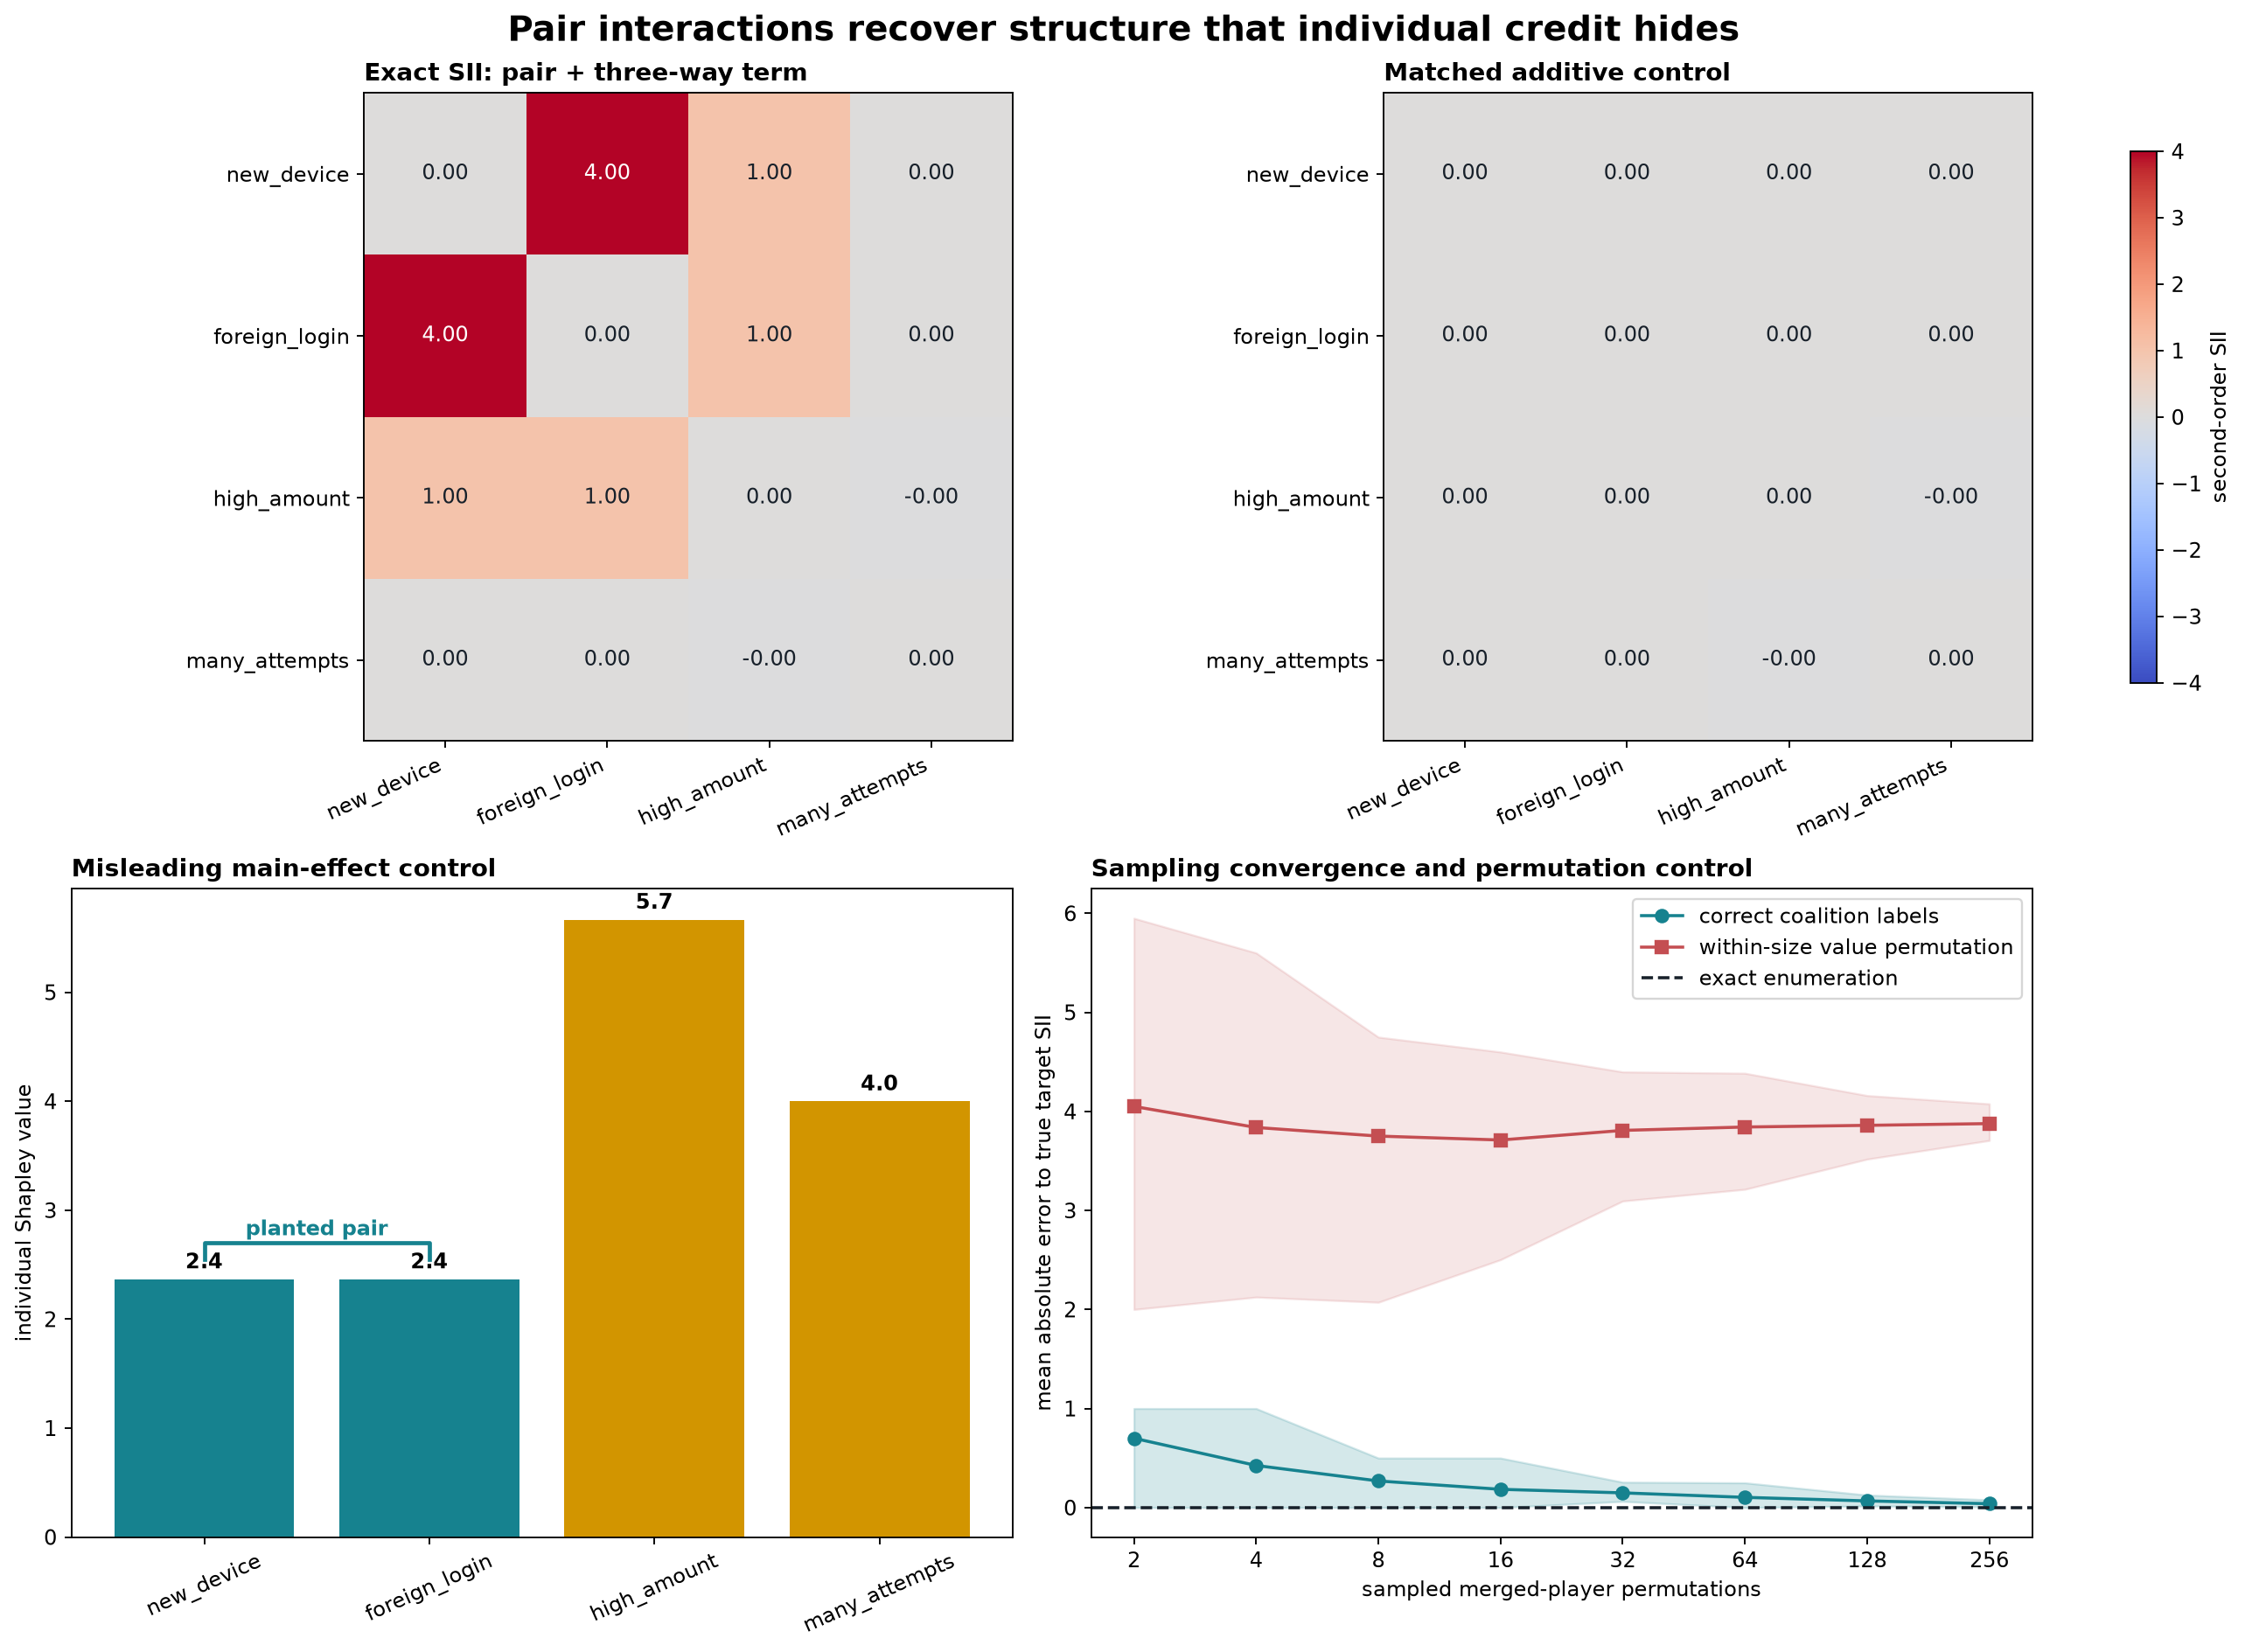

In [ ]:
planted_values = polynomial_game(ADDITIVE_WEIGHTS, {TARGET_PAIR: PAIR_WEIGHT, TRIPLE: TRIPLE_WEIGHT})

additive_values = polynomial_game(ADDITIVE_WEIGHTS, {})

planted_sii = pairwise_shapley_interactions(planted_values, num_players=NUM_PLAYERS)

additive_sii = pairwise_shapley_interactions(additive_values, num_players=NUM_PLAYERS)

main_effects = exact_shapley_values(planted_values, num_players=NUM_PLAYERS)

shapiq_sii = shapiq_pairwise_interactions(planted_values, num_players=NUM_PLAYERS)

shapiq_max_error = float((shapiq_sii - planted_sii).abs().max().item())

recovery = interaction_recovery_report(planted_sii, planted_sii, target_pair=TARGET_PAIR)

permuted_values = permute_coalition_values_within_sizes(planted_values, num_players=NUM_PLAYERS, seed=0)

permuted_sii = pairwise_shapley_interactions(permuted_values, num_players=NUM_PLAYERS)

budgets = toy_np.array([2, 4, 8, 16, 32, 64, 128, 256])

seeds = range(40)

true_exact_target = float(pairwise_shapley_interactions(planted_values, num_players=NUM_PLAYERS)[TARGET_PAIR])

def sampling_error_band(values):
    errors = toy_np.array([[abs(sampled_pair_interaction(values, num_players=NUM_PLAYERS, pair=TARGET_PAIR, budget=int(budget), seed=seed) - true_exact_target) for seed in seeds] for budget in budgets])
    return (errors.mean(axis=1), toy_np.quantile(errors, 0.1, axis=1), toy_np.quantile(errors, 0.9, axis=1))

sample_mean, sample_low, sample_high = sampling_error_band(planted_values)

control_mean, control_low, control_high = sampling_error_band(permuted_values)

summary = toy_pd.DataFrame([{'condition': 'exact pair + three-way game', 'target SII': float(planted_sii[TARGET_PAIR]), 'largest other |SII|': recovery.max_off_target_interaction, 'target rank': recovery.target_rank}, {'condition': 'matched additive control', 'target SII': float(additive_sii[TARGET_PAIR]), 'largest other |SII|': float(additive_sii.abs().max()), 'target rank': 'tie'}, {'condition': 'within-size value permutation', 'target SII': float(permuted_sii[TARGET_PAIR]), 'largest other |SII|': float(permuted_sii[toy_t.triu_indices(NUM_PLAYERS, NUM_PLAYERS, offset=1).unbind()].abs().max()), 'target rank': 'control'}])

display(summary)

display(toy_pd.DataFrame({'player': PLAYER_NAMES, 'individual Shapley value': main_effects.tolist(), 'member of planted pair': [True, True, False, False]}))

fig, axes = toy_plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)

matrix_limit = 4.0

for ax, matrix, title in [(axes[0, 0], planted_sii, 'Exact SII: pair + three-way term'), (axes[0, 1], additive_sii, 'Matched additive control')]:
    image = ax.imshow(matrix.numpy(), cmap='coolwarm', vmin=-matrix_limit, vmax=matrix_limit)
    ax.set_xticks(range(NUM_PLAYERS), PLAYER_NAMES, rotation=24, ha='right')
    ax.set_yticks(range(NUM_PLAYERS), PLAYER_NAMES)
    ax.set_title(title, loc='left', fontweight='bold')
    for toy_row in range(NUM_PLAYERS):
        for column in range(NUM_PLAYERS):
            toy_value = matrix[toy_row, column].item()
            ax.text(column, toy_row, f'{toy_value:.2f}', ha='center', va='center', color='white' if abs(toy_value) > 1.5 else '#17202a')

fig.colorbar(image, ax=axes[0, :], shrink=0.82, label='second-order SII')

colors = ['#16828f', '#16828f', '#d29500', '#d29500']

axes[1, 0].bar(PLAYER_NAMES, main_effects.numpy(), color=colors)

axes[1, 0].set_ylabel('individual Shapley value')

axes[1, 0].set_title('Misleading main-effect control', loc='left', fontweight='bold')

axes[1, 0].tick_params(axis='x', rotation=24)

for index, toy_value in enumerate(main_effects.tolist()):
    axes[1, 0].text(index, toy_value + 0.1, f'{toy_value:.1f}', ha='center', fontweight='bold')

axes[1, 0].plot([0, 0, 1, 1], [2.55, 2.7, 2.7, 2.55], color='#16828f', linewidth=2)

axes[1, 0].text(0.5, 2.77, 'planted pair', ha='center', color='#16828f', fontweight='bold')

axes[1, 1].plot(budgets, sample_mean, marker='o', color='#16828f', label='correct coalition labels')

axes[1, 1].fill_between(budgets, sample_low, sample_high, color='#16828f', alpha=0.18)

axes[1, 1].plot(budgets, control_mean, marker='s', color='#c44e52', label='within-size value permutation')

axes[1, 1].fill_between(budgets, control_low, control_high, color='#c44e52', alpha=0.14)

axes[1, 1].axhline(0.0, color='#17202a', linestyle='--', label='exact enumeration')

axes[1, 1].set_xscale('log', base=2)

axes[1, 1].set_xticks(budgets, [str(value) for value in budgets])

axes[1, 1].set_xlabel('sampled merged-player permutations')

axes[1, 1].set_ylabel('mean absolute error to true target SII')

axes[1, 1].set_title('Sampling convergence and permutation control', loc='left', fontweight='bold')

axes[1, 1].legend(loc='upper right')

fig.suptitle('Pair interactions recover structure that individual credit hides', fontsize=17, fontweight='bold')

signature_path = assets_dir / 'shapley_interactions_exact_signature.png'

fig.savefig(signature_path, dpi=170, bbox_inches='tight')

toy_plt.close(fig)

assert recovery.predicted_pair == TARGET_PAIR and recovery.target_rank == 1

assert abs(recovery.target_value - 4.0) < 1e-09

assert abs(recovery.max_off_target_interaction - 1.0) < 1e-09

assert abs(float(planted_sii[0, 2]) - 1.0) < 1e-09

assert abs(float(planted_sii[1, 2]) - 1.0) < 1e-09

assert float(additive_sii.abs().max()) < 1e-09

assert set(main_effects.topk(2).indices.tolist()) == {2, 3}

assert shapiq_max_error < 1e-06

assert sample_mean[-1] < 0.06

assert control_mean[-1] > 3.5

print(f'shapiq max |error|: {shapiq_max_error:.3e}')

print(f'sampling MAE at budget 256: {sample_mean[-1]:.6f}')

print(f'permuted-control MAE at budget 256: {control_mean[-1]:.6f}')

## Reflect after the result — toy-19

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

The signature above is an expected display from the original saved-only asset. The original toy notebook did not emit a PNG display here; its actual fourteen historical output records are retained separately in solutions.

<details>
<summary>Interpretation - what the four panels establish</summary>

Exact SII puts `4.0` on `new_device x foreign_login`: `3.0` comes from the literal pair dividend and `1.0` from averaging the three-way dividend across contexts. The same higher-order term gives `1.0` to the two other pairs inside the triple. The matched additive game is zero everywhere, so large standalone contributions do not create interaction artifacts. Individual Shapley values still rank `high_amount` and `many_attempts` first.

Sampling MAE falls from about `0.70` at budget 2 to about `0.039` at budget 256. The within-size permutation remains near `3.88` error because it preserves coalition-size statistics while severing player identity. Pinned `shapiq` agrees with the student exact matrix to below `1e-6` on this same pair-plus-three-way game.

</details>

## Try It Yourself

Change the pair, pair weight, additive weights, triple interaction, sampling budget, and seed. Predict the main-effect ranking and strongest interaction before running the cell. A nonzero triple term should make several pairwise indices move.

## Forecast before running — toy-22

Commit changed polynomial coefficients and sampling budget, then predict exact versus sampled target behavior.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
PLAY_ADDITIVE_WEIGHTS = toy_t.tensor([0.2, 0.2, 5.0, 4.0], dtype=toy_t.float64)

PLAY_PAIR = (0, 1)

PLAY_PAIR_WEIGHT = 3.0

PLAY_TRIPLE = (0, 1, 2)

PLAY_TRIPLE_WEIGHT = 2.0

PLAY_BUDGET = 32

PLAY_SEED = 7

play_terms = {PLAY_PAIR: PLAY_PAIR_WEIGHT}

if PLAY_TRIPLE_WEIGHT != 0.0:
    play_terms[PLAY_TRIPLE] = PLAY_TRIPLE_WEIGHT

play_values = polynomial_game(PLAY_ADDITIVE_WEIGHTS, play_terms)

play_sii = pairwise_shapley_interactions(play_values, num_players=NUM_PLAYERS)

play_main = exact_shapley_values(play_values, num_players=NUM_PLAYERS)

play_sample = sampled_pair_interaction(play_values, num_players=NUM_PLAYERS, pair=PLAY_PAIR, budget=PLAY_BUDGET, seed=PLAY_SEED)

display(toy_pd.DataFrame([{'pair': f'{PLAYER_NAMES[first]} x {PLAYER_NAMES[second]}', 'exact SII': float(play_sii[first, second])} for first, second in toy_itertools.combinations(range(NUM_PLAYERS), 2)]))

print('individual Shapley values:', dict(zip(PLAYER_NAMES, play_main.tolist(), strict=True)))

print(f'sampled target-pair SII (PLAY_BUDGET={PLAY_BUDGET!r}): {play_sample:.4f}')

## Reflect after the result — toy-22

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

## Anomaly hunt - when a pairwise index contains higher-order structure

The primary game includes `2 * x0 * x1 * x2`. No explicit `(0,2)` or `(1,2)` pair term exists, yet their pairwise SII values become `1.0`. Inspect local second differences to see why: the apparent pair interaction switches on only when the third feature is present.

## Forecast before running — toy-24

Predict why pairs without a planted pair dividend can have nonzero contextual SII.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
planted_sii = pairwise_shapley_interactions(planted_values, num_players=NUM_PLAYERS)

anomaly_rows = []

for toy_pair in [(0, 1), (0, 2), (1, 2)]:
    remaining = [player for player in range(NUM_PLAYERS) if player not in toy_pair]
    empty_delta = discrete_second_difference(planted_values, frozenset(), toy_pair, num_players=NUM_PLAYERS)
    revealing_context = frozenset((next((p for p in (0, 1, 2) if p not in toy_pair), remaining[0]),))
    context_delta = discrete_second_difference(planted_values, revealing_context, toy_pair, num_players=NUM_PLAYERS)
    anomaly_rows.append({'pair': f'{PLAYER_NAMES[toy_pair[0]]} x {PLAYER_NAMES[toy_pair[1]]}', 'empty-context delta': empty_delta, 'revealing-context delta': context_delta, 'pairwise SII': float(planted_sii[toy_pair])})

display(toy_pd.DataFrame(anomaly_rows))

## Reflect after the result — toy-24

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Help - how should this anomaly change the claim?</summary>

Second-order SII summarizes how two players interact after averaging over contexts. It does not promise that the data-generating rule contains a literal pair-only term. Follow a surprising pair with context-specific second differences or a higher-order index before naming a pairwise mechanism.

</details>

## Connection to the pinned neural game

The release preflight trains a four-input MLP on all 16 binary rows of a different exact rule. Its planted interactions are `+2.2` for `(0,2)` and `-1.5` for `(1,3)`. The learner code below computes the target matrix directly; the serialized CUDA job separately checks that ablations of the trained model recover it.

## Forecast before running — toy-27

Predict signs of both planted neural-target pairs without treating this truth table as a new trained model.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
neural_target_values = polynomial_game(toy_t.tensor([1.2, -0.7, 1.6, 0.9], dtype=toy_t.float64), {(0, 2): 2.2, (1, 3): -1.5})

neural_target_sii = pairwise_shapley_interactions(neural_target_values, num_players=4)

display(toy_pd.DataFrame([{'pair': pair, 'exact target SII': float(neural_target_sii[pair])} for pair in toy_itertools.combinations(range(4), 2)]))

## Reflect after the result — toy-27

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

The existing pinned CUDA evidence reports fit MSE `1.102e-12`, interaction-matrix maximum error `4.520e-7`, largest spurious interaction `6.606e-7`, `shapiq` parity error `1.180e-8`, and shuffled-label interaction error `4.383`. These values support only this complete four-feature model organism. They are not the notebook's signature result.

## Release verification appendix

The learner result above is complete without a release report. Course release tooling separately imports the section's serialized CUDA entrypoints to check that a trained four-input MLP reproduces another exact interaction game. These definitions preserve that interface; they are supporting verification, not an exercise, implementation shortcut, or signature result.

In [ ]:
verification_report_path = section_dir / 'verification_report.json'

def run_gpu_test(max_vram_gb: float=24.0) -> dict:
    from part3_shapley_interactions_shapiq.solutions import run_gpu_test as run
    return run(max_vram_gb=max_vram_gb)

def run_full_experiment(max_vram_gb: float=24.0) -> dict:
    return run_gpu_test(max_vram_gb=max_vram_gb)

## Limitations

- Exact enumeration costs `2**n` game evaluations and stops being practical quickly.
- Pairwise SII can contain contributions from higher-order interactions, as the anomaly hunt demonstrates.
- Permutation sampling is unbiased for the chosen SII estimator, but small budgets have visible seed variance.
- `shapiq` parity proves agreement on one complete table with index `SII` and maximum order 2; it does not validate every index or approximation policy.
- Coalition values depend on the baseline, masking semantics, and feature definition. This lab fixes all three explicitly.
- The pinned MLP is a finite model organism, not evidence about token, SAE, image-region, or large-model interactions.

## Paper connection and reading

- [Grabisch & Roubens (1999), the axiomatic Shapley interaction index](https://link.springer.com/article/10.1007/s001820050125)
- [shapiq: Shapley Interactions for Machine Learning](https://arxiv.org/abs/2410.01649)
- [shapiq documentation](https://shapiq.readthedocs.io/en/latest/)
- [shapiq source and benchmark suite](https://github.com/mmschlk/shapiq)

Next, test whether a discovered pair remains strong across baselines and feature groupings, then inspect its context-specific second differences before interpreting it as a mechanism.

## Study conclusion — toy

State the target interaction definition, experiment, denominator and negative controls before comparing this track with the other two. Preserve any disagreement as evidence about distinct questions.

# 2️⃣ Where higher-order credit goes

## [16.16] Where Does Higher-Order Credit Go? — Solutions

> **Shapley-Taylor and Faith-Shap from complete games**
>
> This lesson runs on CPU. You will implement the interaction methods yourself, check them on exact
> games, and then apply them to a frozen finite-background prediction game.

## Introduction

Suppose a model only turns on when **four ingredients are present together**, but your explanation is
allowed to show only single features and pairs. There is no literal one-feature or two-feature term in
that model. An order-two explanation still has to decide where the four-way credit goes.

That decision is not bookkeeping trivia. Different interaction indices answer different questions.
This lesson puts three of them on the same complete coalition game:

- **Shapley-Taylor** preserves lower-order Möbius dividends and routes omitted dividends into the
  highest retained order.
- **Faith-Shap** chooses all retained coefficients jointly to minimize a declared Shapley-kernel
  reconstruction error, subject to exact empty/full constraints.
- **SII** averages a selected discrete derivative over contexts. Its singleton Shapley values and
  pair SII values are separate index families, not one efficient order-two decomposition.

You will see all three give exact, internally valid, and different pair answers.

## Core Question

> When an explanation can contain only singletons and pairs, where should the credit for a true
> three-way or four-way mechanism go?

Two efficient order-two ledgers are possible for the pure four-player unanimity game. Before reading
on, predict which one will better reconstruct the interior coalitions:

| anonymous rule | each singleton | each pair | endpoint ledger |
|---|---:|---:|---:|
| A | `0` | `1/6` | `6 × 1/6 = 1` |
| B | `-1/5` | `3/10` | `4 × (-1/5) + 6 × (3/10) = 1` |

Both satisfy the full-coalition ledger, so efficiency alone cannot decide. Write down your prediction,
including the reconstructed value of a coalition containing just one feature, before opening the answer.

<details>
<summary>Reveal the two rules</summary>

| definition | each singleton | each pair | endpoint ledger |
|---|---:|---:|---:|
| Shapley-Taylor, order 2 | `0` | `1/6` | `6 × 1/6 = 1` |
| Faith-Shap, order 2 | `-1/5` | `3/10` | `4 × (-1/5) + 6 × (3/10) = 1` |
| SII convention | Shapley `1/4` | pair SII `1/3` | separate families; do not sum as one decomposition |

The disagreement is the result we will explain.

</details>

## Forecast before running — allocation-3

Forecast whether an efficient singleton-plus-pair representation can assign negative singleton credit to a positive four-way mechanism.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
from fractions import Fraction

cold_open = {'Shapley-Taylor': (Fraction(0), Fraction(1, 6)), 'Faith-Shap': (Fraction(-1, 5), Fraction(3, 10)), 'Shapley / pair SII': (Fraction(1, 4), Fraction(1, 3))}

for name, (singleton, allocation_pair) in cold_open.items():
    print(f'{name:20s} singleton={str(singleton):>4s}  pair={str(allocation_pair):>4s}')

print('ST efficient:', 4 * cold_open['Shapley-Taylor'][0] + 6 * cold_open['Shapley-Taylor'][1])

print('Faith efficient:', 4 * cold_open['Faith-Shap'][0] + 6 * cold_open['Faith-Shap'][1])

## Reflect after the result — allocation-3

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Question - how can a positive four-way mechanism produce negative singleton coefficients?</summary>

Faith-Shap is fitting a degree-two polynomial to the whole coalition table. Negative singletons
counteract positive pair terms on small coalitions, while the exact full-coalition constraint keeps
the total at one. A coefficient in this surrogate is not an isolated causal effect.

</details>

## Original study objectives

By the end of the lesson, you should be able to:

1. invert a complete coalition table into bitmask-indexed Möbius dividends;
2. derive Shapley-Taylor's top-order dividend routing rule;
3. construct Faith-Shap's subset design and per-coalition Shapley kernel;
4. solve Faith-Shap with exact endpoint constraints and check the paper's closed form;
5. distinguish kernel-weighted faithfulness from unweighted coalition residuals;
6. turn a scalar model and intact donor bank into a complete empirical game;
7. trace a pair interaction to four explicit model evaluations in a chosen context; and
8. interpret fitted-model disagreement without calling any interaction definition causal truth.

The eight implementation exercises should take about 105–135 minutes. The native capstone is a
guided reading and recomputation exercise after the scientific protocol is frozen.

| route | sections | suggested time |
|---|---|---:|
| Core exact methods | Exercises 1–4 and 6 | 60–75 min |
| Stretch derivation | Exercise 5, the paper closed form | 15–20 min |
| Model-game bridge | Exercises 7–8 | 30–40 min |
| Guided native reading and plays | Section 6 | 35–50 min after the frozen run is available |

If you are short on time, read the Exercise 5 derivation and solution, then return after completing
the model-game bridge. The KKT implementation remains the primary executable Faith-Shap route; the
closed form is its deliberately independent cross-check.

## Setup

The public methods operate on CPU `float64` tensors. The final axis is a complete coalition table in
ascending integer-mask order: bit `i` says feature `i` is present. Entry zero in every coefficient
vector is the intercept. It is displayed separately from the nonempty efficiency ledger.

In [ ]:
from __future__ import annotations

import contextlib

import hashlib

import math as allocation_math

import os as allocation_os

import random as allocation_random

from collections.abc import Iterator, Mapping as allocation_Mapping

from pathlib import Path as allocation_Path

from types import SimpleNamespace as allocation_SimpleNamespace

from typing import Any as allocation_Any

import matplotlib.pyplot as allocation_plt

import numpy as allocation_np

import pandas as allocation_pd

import torch

import torch as allocation_t

from torch import Tensor as allocation_Tensor, nn

from IPython.display import display as allocation_display

from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap import interaction_methods_tests as allocation_tests

from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.interaction_methods import _interaction_counts, _interaction_float_input, _interaction_game_batches, _interaction_model, _interaction_model_output, _interaction_n_players, _interaction_order, _interaction_preserve_model_state, _interaction_tensor

from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.interaction_diagnostics import GAME_NAMES, PAIR_INDICES, _callable, _diagnostic, _ordinary_shapley_from_mobius, _pairwise_sii_from_mobius, _zeta, interaction_diagnostics

from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.interaction_plots import plot_allrow_pair_heatmaps, plot_background_changes_the_game, plot_contextual_pair_interventions, plot_dividend_play, plot_donor_context_play, plot_exact_allocation_ledger, plot_fixed_row_interaction_graph, plot_heldout_pair_order_capture, plot_native_game_and_controls, plot_order_two_reconstruction, plot_reconstruction_reason

from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.interaction_data import background_order, load_manifest, load_split, tensor_mapping_sha256

from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.interaction_reference import _preserve_execution_state, _reference_check_impl, _validate_exact_suite, validate_reference_payload

from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.run_native import persist_completed, persist_prepared, validate_freeze, write_notebook_summary

from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.interaction_study import _METHOD_FIRST_LEAVES, _SHARED_GAME_LEAVES, _background_records, _clone_state, _combine_game_blocks, _derived_seed, _direct_full_context_four, _empirical_reference_plan, _evaluate_backgrounds, _evaluate_primary, _exact_suite, _fit_one_mlp, _fit_ridge, _float_tensor, _group_weighted_mean_abs, _int_tensor, _localization_statistics, _logical_hybrid_row, _pair_ranks, _performance, _require_disjoint_ids, _require_methods, _rows, _storage_plan, _training_normalization, _validate_fitted, _within_size_permutations, coalition_masks, exact_dividend_play, nearest_training_diagnostics, pair_indices

DEVICE = torch.device('cpu')

DTYPE = torch.float64

torch.set_default_dtype(DTYPE)

torch.set_num_threads(4)

FIGURE_DIR = allocation_Path(allocation_os.environ.get('ARENA_INTERACTION_OUTPUT_DIRECTORY', './figures'))

native_directory = FIGURE_DIR / 'native'

def allocation_show_figure(figure, stem: str):
    """Display one result and retain the exact PNG used by the draft execution."""
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    path = FIGURE_DIR / f'{stem}.png'
    figure.savefig(path, dpi=160, bbox_inches='tight')
    allocation_display(figure)
    allocation_plt.close(figure)
    return path

The private `_interaction_*` names above are validation and state-restoration plumbing. The ten
scientific functions below are implemented in full in the notebook and receive the tests directly.

## 1️⃣ From coalition values to dividends

## A complete game and its Möbius expansion

Let $N=\{0,\ldots,n-1\}$ and let $v(S)$ be a value for every subset $S\subseteq N$. The discrete
derivative of a set $U$ at the empty context is

$$
\Delta_U v(\varnothing)
=\sum_{W\subseteq U}(-1)^{|U|-|W|}v(W).
$$

This is the Möbius dividend $a(U)$. The inverse is the subset sum

$$
v(S)=\sum_{U\subseteq S}a(U).
$$

For two players, integer masks make the bookkeeping concrete. Consider this complete game:

| mask | coalition | $v(S)$ | Möbius calculation | $a(S)$ |
|---:|---|---:|---|---:|
| `00` | $\varnothing$ | `1` | $v(\varnothing)$ | `1` |
| `01` | $\{A\}$ | `3` | $3-1$ | `2` |
| `10` | $\{B\}$ | `0` | $0-1$ | `-1` |
| `11` | $\{A,B\}$ | `5` | $5-3-0+1$ | `3` |

The last row is the part of the joint coalition that its two strict singleton subsets did not
already explain. Summing the four dividends beneath mask `11` gives `1 + 2 - 1 + 3 = 5`, recovering
the game value.

For a pure three-way game, every coalition value below the full triple is zero, so exactly one
Möbius coefficient is nonzero. The fast transform below applies one feature bit at a time and works
for arbitrary leading batch dimensions.

### Exercise 1 - implement `mobius_transform`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Work on a clone. For feature bit `i`, subtract the coefficient at the matching mask with bit `i`
removed from every mask that contains `i`.

## Forecast before running — allocation-11

Predict the nonzero Möbius dividends and reconstruct one coalition from its subsets.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def mobius_transform(game_values: allocation_Tensor, *, n_players: int) -> allocation_Tensor:
    """Return a full bitmask-indexed Möbius coefficient tensor."""
    raise NotImplementedError()


allocation_tests.test_mobius_transform(fn=mobius_transform)

<details><summary>Solution</summary>

```python
def mobius_transform(game_values: allocation_Tensor, *, n_players: int) -> allocation_Tensor:
    """Return a full bitmask-indexed Möbius coefficient tensor."""
    n_players = _interaction_n_players(n_players)
    _interaction_tensor('game_values', game_values, n_players)
    mobius = game_values.clone()
    masks = torch.arange(2 ** n_players, dtype=torch.int64)
    for player in range(n_players):
        present = masks.bitwise_and(1 << player).ne(0)
        lower = masks[present].bitwise_xor(1 << player)
        mobius[..., present] -= mobius[..., lower]
    return mobius

allocation_tests.test_mobius_transform(fn=mobius_transform)
```
</details>

## Reflect after the result — allocation-11

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

```text
All tests in test_mobius_transform passed!
```

The constant, additive, pure-pair, and pure-triple rows recover only their declared dividends. The
input stays unchanged and seeded RNG states do not move.

</details>

<details>
<summary>Help - update masks containing one bit</summary>

Create `masks = torch.arange(2**n_players)`. For each player, select masks where
`masks & (1 << player)` is nonzero. Their lower partner is obtained by XOR-ing that bit.

</details>

<details>
<summary>Interpretation</summary>

Why do we start from Möbius dividends rather than directly averaging coalition values?

The dividend isolates the part of $v(U)$ that was not already explained by strict subsets. It makes
"a true four-way term" literal, so we can see exactly where an order-two rule sends it.

</details>

The first diagnostic constructs named constant, additive, pair, triple, four-way, negative and mixed
games. A sparse dividend display is more informative here than a pass/fail scalar.

In [ ]:
def _fixture_mobius() -> allocation_Tensor:
    mobius = torch.zeros((len(GAME_NAMES), 16), dtype=torch.float64)
    mobius[0, 0] = 2.0
    mobius[1, 0] = -0.5
    mobius[1, [1, 2, 4, 8]] = torch.tensor([1.0, -2.0, 1.5, 0.25], dtype=torch.float64)
    mobius[2, 3] = 1.0
    mobius[3, 10] = -0.75
    mobius[4, 7] = 1.0
    mobius[5, 15] = 1.0
    mobius[6, 0] = 1 / 3
    mobius[6, [1, 2, 4, 8]] = torch.tensor([0.5, -0.25, 0.75, -1.0], dtype=torch.float64)
    for mask, value in {3: 2 / 3, 9: -0.5, 6: 0.2, 12: 0.375}.items():
        mobius[6, mask] = value
    mobius[7, 0] = -0.2
    mobius[7, 1] = 1 / 3
    mobius[7, 6] = -0.4
    mobius[7, 13] = 0.75
    mobius[7, 15] = -0.5
    return mobius

def exact_game_fixture() -> dict[str, allocation_Any]:
    """Return the declared analytic games and exact SII comparators."""
    mobius = _fixture_mobius()
    games = _zeta(mobius, 4)
    return {'evidence_kind': 'analytic_exact', 'label': 'exact teaching games', 'n_players': 4, 'order': 2, 'feature_names': ('A', 'B', 'C', 'D'), 'game_names': GAME_NAMES, 'game_values': games, 'expected_mobius': mobius, 'ordinary_shapley': _ordinary_shapley_from_mobius(mobius, 4), 'sii_pairs': _pairwise_sii_from_mobius(mobius, 4), 'pair_indices': PAIR_INDICES, 'single_masks': torch.tensor([1, 2, 4, 8], dtype=torch.int64), 'pair_masks': torch.tensor([1 << first | 1 << second for first, second in PAIR_INDICES], dtype=torch.int64), 'exact_fraction_labels': {'pure_triple': {'stii_singleton': '0', 'stii_contained_pair': '1/3', 'fsii_singleton': '-1/6', 'fsii_contained_pair': '1/2', 'shapley_singleton': '1/3', 'sii_contained_pair': '1/2'}, 'pure_four': {'stii_singleton': '0', 'stii_pair': '1/6', 'fsii_singleton': '-1/5', 'fsii_pair': '3/10', 'shapley_singleton': '1/4', 'sii_pair': '1/3'}}}

In [ ]:
def diagnose_mobius_games(mobius_transform_fn: Callable[..., allocation_Tensor], diagnostic: dict[str, allocation_Any] | None=None) -> dict[str, allocation_Any]:
    """Run the learner Möbius transform on all eight exact fixtures."""
    _callable('mobius_transform_fn', mobius_transform_fn)
    result = _diagnostic(diagnostic)
    observed = mobius_transform_fn(result['game_values'], n_players=4)
    torch.testing.assert_close(observed, result['expected_mobius'], rtol=0, atol=1e-12)
    result['mobius'] = observed
    result['mobius_max_abs_error'] = float((observed - result['expected_mobius']).abs().max().item())
    result['stages'] = tuple(result.get('stages', ())) + ('mobius',)
    return result

In [ ]:
exact_diagnostics = diagnose_mobius_games(mobius_transform, diagnostic=exact_game_fixture())

print('max |Möbius error|:', exact_diagnostics['mobius_max_abs_error'])

for game_name, allocation_row in zip(exact_diagnostics['game_names'], exact_diagnostics['mobius'], strict=True):
    sparse = {f'{mask:04b}': round(float(value), 6) for mask, value in enumerate(allocation_row) if abs(float(value)) > 1e-12}
    print(f'{game_name:16s}', sparse)

## 2️⃣ Shapley-Taylor: route omitted dividends

## Preserve low orders, distribute at the boundary

At order $k$, Shapley-Taylor keeps the lower Möbius dividends:

$$
I^{\mathrm{ST},k}_S=a(S),\qquad 0<|S|<k.
$$

Every dividend of order at least $k$ is shared uniformly over its $k$-subsets:

$$
I^{\mathrm{ST},k}_S
=\sum_{U\supseteq S}\frac{a(U)}{\binom{|U|}{k}},
\qquad |S|=k.
$$

All terms above $k$ are exactly zero. At $k=1$ the output is ordinary Shapley; at $k=n$ it is the
full Möbius expansion.

### Exercise 2 - implement `shapley_taylor_interactions`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 15 minutes on this exercise.
> ```

Keep the intercept at mask zero. Copy lower nonempty terms, then visit each mask of exactly the
requested order and collect its share from every superset.

## Forecast before running — allocation-22

Predict where a high-order dividend goes at order two versus full order.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def shapley_taylor_interactions(mobius: allocation_Tensor, *, n_players: int, order: int) -> allocation_Tensor:
    """Allocate Möbius dividends into an efficient order-truncated expansion."""
    raise NotImplementedError()


allocation_tests.test_shapley_taylor_interactions(fn=shapley_taylor_interactions)

<details><summary>Solution</summary>

```python
def shapley_taylor_interactions(mobius: allocation_Tensor, *, n_players: int, order: int) -> allocation_Tensor:
    """Allocate Möbius dividends into an efficient order-truncated expansion."""
    n_players = _interaction_n_players(n_players)
    order = _interaction_order('order', order, n_players)
    _interaction_tensor('mobius', mobius, n_players)
    counts = _interaction_counts(n_players)
    result = torch.zeros_like(mobius)
    result[..., 0] = mobius[..., 0]
    lower = (counts > 0) & (counts < order)
    result[..., lower] = mobius[..., lower]
    for interaction in range(1, 2 ** n_players):
        if interaction.bit_count() != order:
            continue
        for superset in range(interaction, 2 ** n_players):
            if superset & interaction == interaction:
                result[..., interaction] += mobius[..., superset] / allocation_math.comb(superset.bit_count(), order)
    return result

allocation_tests.test_shapley_taylor_interactions(fn=shapley_taylor_interactions)
```
</details>

## Reflect after the result — allocation-22

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

```text
All tests in test_shapley_taylor_interactions passed!
```

A pure triple gives singleton `0` and each contained pair `1/3`; a pure four-way term gives
singleton `0` and all six pairs `1/6`. Order one matches ordinary Shapley and full order matches
Möbius inversion.

</details>

<details>
<summary>Help - sum over supersets of each retained pair</summary>

For one retained mask `interaction`, a mask `superset` contains it when
`superset & interaction == interaction`. Divide the superset dividend by
`math.comb(superset.bit_count(), order)`.

</details>

<details>
<summary>Interpretation</summary>

Why is the pair value `1/6` rather than `1/4` for the pure four-way game?

The dividend is shared among the six retained **pairs**, not the four players. The denominator is
$\binom{4}{2}$. The resulting nonempty terms sum to the full-minus-empty value.

</details>

In [ ]:
def diagnose_shapley_taylor(diagnostic: dict[str, allocation_Any], shapley_taylor_fn: Callable[..., allocation_Tensor]) -> dict[str, allocation_Any]:
    """Add student Shapley-Taylor allocations and exact fraction checks."""
    _callable('shapley_taylor_fn', shapley_taylor_fn)
    result = _diagnostic(diagnostic)
    if 'mobius' not in result:
        raise ValueError('Run diagnose_mobius_games before Shapley-Taylor diagnostics.')
    coefficients = shapley_taylor_fn(result['mobius'], n_players=4, order=2)
    if coefficients.shape != result['game_values'].shape:
        raise AssertionError('Shapley-Taylor must return one coefficient per mask.')
    pure_triple = GAME_NAMES.index('pure_triple')
    pure_four = GAME_NAMES.index('pure_four')
    singles, pairs = (result['single_masks'], result['pair_masks'])
    torch.testing.assert_close(coefficients[pure_four, singles], torch.zeros(4, dtype=torch.float64), rtol=0, atol=1e-12)
    torch.testing.assert_close(coefficients[pure_four, pairs], torch.full((6,), 1 / 6, dtype=torch.float64), rtol=0, atol=1e-12)
    torch.testing.assert_close(coefficients[pure_triple, singles], torch.zeros(4, dtype=torch.float64), rtol=0, atol=1e-12)
    contained = torch.tensor([0, 1, 3], dtype=torch.int64)
    torch.testing.assert_close(coefficients[pure_triple, pairs[contained]], torch.full((3,), 1 / 3, dtype=torch.float64), rtol=0, atol=1e-12)
    efficiency = coefficients.sum(dim=-1) - result['game_values'][:, -1]
    torch.testing.assert_close(efficiency, torch.zeros_like(efficiency), rtol=0, atol=1e-12)
    result['stii'] = coefficients
    result['stii_efficiency_residual'] = efficiency
    result['stages'] = tuple(result.get('stages', ())) + ('shapley_taylor',)
    return result

In [ ]:
exact_diagnostics = diagnose_shapley_taylor(exact_diagnostics, shapley_taylor_interactions)

print('max |efficiency residual|:', float(exact_diagnostics['stii_efficiency_residual'].abs().max()))

## 3️⃣ Faith-Shap: fit a constrained polynomial

## What does “faithful” optimize?

For maximum order $\ell$, Faith-Shap reconstructs coalition $S$ with

$$
\hat v_E(S)=\sum_{T\subseteq S,\ |T|\leq\ell}E_T.
$$

It minimizes the interior weighted error

$$
\sum_{1\leq |S|\leq n-1}\mu(S)\bigl(v(S)-\hat v_E(S)\bigr)^2,
\qquad
\mu(S)\propto\frac{n-1}{\binom{n}{|S|}|S|(n-|S|)},
$$

subject to the exact constraints $E_\varnothing=v(\varnothing)$ and
$\sum_{\lvert T\rvert\leq\ell}E_T=v(N)$. The formula above is a **per-coalition** weight. Using a whole
cardinality's probability for every row would count $\binom n{\lvert S\rvert}$ twice.

### Exercise 3 - implement `faith_design_matrix` and `faith_kernel_weights`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 15 minutes on this exercise.
> ```

The design contains one column for every term mask of size at most `max_order`, including mask zero.
Set `X[S,T]=1` exactly when `T` is a subset of `S`. Return zero endpoint weights and normalize all
finite interior weights to sum to one.

## Forecast before running — allocation-31

Predict which design columns and finite kernel weights apply, and separate endpoint constraints from finite penalties.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def faith_design_matrix(*, n_players: int, max_order: int) -> tuple[allocation_Tensor, allocation_Tensor]:
    """Return float64 X[coalition_mask, term] and int64 term_masks."""
    raise NotImplementedError()


def faith_kernel_weights(*, n_players: int) -> allocation_Tensor:
    """Return normalized interior per-coalition weights; endpoints are zero."""
    raise NotImplementedError()


allocation_tests.test_faith_design_matrix(fn=faith_design_matrix)

allocation_tests.test_faith_kernel_weights(fn=faith_kernel_weights)

<details><summary>Solution</summary>

```python
def faith_design_matrix(*, n_players: int, max_order: int) -> tuple[allocation_Tensor, allocation_Tensor]:
    """Return float64 X[coalition_mask, term] and int64 term_masks."""
    n_players = _interaction_n_players(n_players, minimum=2)
    max_order = _interaction_order('max_order', max_order, n_players)
    masks = torch.arange(2 ** n_players, dtype=torch.int64)
    counts = _interaction_counts(n_players)
    term_masks = masks[counts <= max_order]
    design = masks[:, None].bitwise_and(term_masks[None, :]).eq(term_masks).to(torch.float64)
    return (design, term_masks)


def faith_kernel_weights(*, n_players: int) -> allocation_Tensor:
    """Return normalized interior per-coalition weights; endpoints are zero."""
    n_players = _interaction_n_players(n_players, minimum=2)
    weights = torch.zeros(2 ** n_players, dtype=torch.float64)
    for mask in range(1, 2 ** n_players - 1):
        size = mask.bit_count()
        weights[mask] = (n_players - 1) / (allocation_math.comb(n_players, size) * size * (n_players - size))
    return weights / weights.sum()

allocation_tests.test_faith_design_matrix(fn=faith_design_matrix)

allocation_tests.test_faith_kernel_weights(fn=faith_kernel_weights)
```
</details>

## Reflect after the result — allocation-31

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

```text
All tests in test_faith_design_matrix passed!
All tests in test_faith_kernel_weights passed!
```

For `n=3, max_order=2`, `term_masks == [0,1,2,3,4,5,6]`, the design has shape `(8,7)`, and each
of the six interior coalitions has normalized weight `1/6`. For `n=4`, a size-one coalition gets
twice the weight of one size-two coalition.

</details>

<details>
<summary>Help - separate term selection from subset incidence</summary>

First filter all masks by population count to obtain `term_masks`. Then compare
`masks[:, None] & term_masks[None, :]` with `term_masks`. Build kernel weights in a loop over the
interior masks and normalize once at the end.

</details>

<details>
<summary>Interpretation</summary>

Why are the returned endpoint weights zero?

Those rows are excluded from the finite objective because their values are imposed as exact equality
constraints. Zero is an implementation marker for exclusion, not the mathematical claim that
endpoints are unimportant.

</details>

In [ ]:
def diagnose_faith_design(diagnostic: dict[str, allocation_Any], faith_design_matrix_fn: Callable[..., tuple[allocation_Tensor, allocation_Tensor]], faith_kernel_weights_fn: Callable[..., allocation_Tensor]) -> dict[str, allocation_Any]:
    """Check the visible Faith design and per-coalition kernel semantics."""
    _callable('faith_design_matrix_fn', faith_design_matrix_fn)
    _callable('faith_kernel_weights_fn', faith_kernel_weights_fn)
    result = _diagnostic(diagnostic)
    design, term_masks = faith_design_matrix_fn(n_players=3, max_order=2)
    weights = faith_kernel_weights_fn(n_players=3)
    weights_n4 = faith_kernel_weights_fn(n_players=4)
    if design.shape != (8, 7) or term_masks.shape != (7,):
        raise AssertionError('For n=3, order=2 the Faith design must have shape [8,7].')
    expected_terms = torch.tensor([0, 1, 2, 3, 4, 5, 6], dtype=torch.int64)
    torch.testing.assert_close(term_masks, expected_terms, rtol=0, atol=0)
    expected = torch.arange(8, dtype=torch.int64)[:, None].bitwise_and(term_masks[None, :]).eq(term_masks).to(torch.float64)
    torch.testing.assert_close(design, expected, rtol=0, atol=0)
    if weights.dtype != torch.float64 or weights.shape != (8,):
        raise AssertionError('Faith kernel weights must be float64 with one value per coalition.')
    torch.testing.assert_close(weights[[0, -1]], torch.zeros(2, dtype=torch.float64), rtol=0, atol=0)
    torch.testing.assert_close(weights.sum(), torch.tensor(1.0, dtype=torch.float64), rtol=0, atol=1e-12)
    expected_n4 = torch.zeros(16, dtype=torch.float64)
    for mask in range(1, 15):
        size = mask.bit_count()
        expected_n4[mask] = 3 / (allocation_math.comb(4, size) * size * (4 - size))
    expected_n4 /= expected_n4.sum()
    torch.testing.assert_close(weights_n4, expected_n4, rtol=0, atol=1e-12)
    result['faith_design'] = design
    result['faith_term_masks'] = term_masks
    result['faith_kernel_weights'] = weights
    result['faith_kernel_weights_n4'] = weights_n4
    result['stages'] = tuple(result.get('stages', ())) + ('faith_design',)
    return result

In [ ]:
exact_diagnostics = diagnose_faith_design(exact_diagnostics, faith_design_matrix, faith_kernel_weights)

print('n=3 design shape:', tuple(exact_diagnostics['faith_design'].shape))

print('n=3 kernel sum:', float(exact_diagnostics['faith_kernel_weights'].sum()))

## Exact endpoint constraints via one KKT solve

Let $X$ contain the retained design columns, $W$ the diagonal interior kernel, and $C$ two
constraint rows: one selects the intercept and one sums every coefficient. The exact system is

$$
\begin{bmatrix}X^T W X & C^T\\ C & 0\end{bmatrix}
\begin{bmatrix}\beta\\\lambda\end{bmatrix}
=
\begin{bmatrix}X^T Wv\\v(\varnothing)\\v(N)\end{bmatrix}.
$$

A finite large endpoint penalty is an approximation to this system. Here we solve the equalities
directly and reuse the same matrix for every leading batch item.

<details>
<summary>Derivation - from least squares to the two constraint rows</summary>

First ignore the endpoints. Differentiating
$\tfrac12(X\beta-v)^T W(X\beta-v)$ gives $X^T W(X\beta-v)$, so an unconstrained
stationary point obeys $X^T W X\beta=X^T Wv$.

The first row of the design at the empty coalition is $(1,0,\ldots,0)$: it selects
the intercept. At the full coalition, every retained subset is present, so the row
is $(1,1,\ldots,1)$. Stack those two rows into $C$ and their required values into
$d=(v(\varnothing),v(N))^T$.

Add a multiplier term $\lambda^T(C\beta-d)$ to the objective. Setting both derivatives
to zero gives $X^T W X\beta+C^T\lambda=X^T Wv$ and $C\beta=d$, which are exactly
the two block rows above. The multiplier changes the optimum so the endpoint
equalities hold; it is not a large numerical penalty. In floating-point code,
these equalities hold to the precision of the linear solve.

</details>

### Exercise 4 - implement `faith_shap_interactions`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 20 minutes on this exercise.
> ```

Build the Gram and constraint blocks once. Flatten only the leading dimensions into a batch of
right-hand sides, solve them together, then scatter the retained terms into a full mask vector.

There is one useful exact shortcut. If `max_order == n_players`, all coalition
monomials are present. Their unique interpolating coefficients are the Möbius
dividends you already know how to compute. Return that transform directly in this
case. It has zero reconstruction error in exact arithmetic and avoids the numerical
conditioning of a much larger KKT system. Use the constrained solve for truncated orders.

## Forecast before running — allocation-39

Forecast the exact constrained optimum on a high-order unanimity game; distinguish weighted error from coefficient sign.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def faith_shap_interactions(game_values: allocation_Tensor, *, n_players: int, max_order: int) -> allocation_Tensor:
    """Solve exact equality-constrained weighted least squares."""
    raise NotImplementedError()


allocation_tests.test_faith_shap_interactions(fn=faith_shap_interactions)

<details><summary>Solution</summary>

```python
def faith_shap_interactions(game_values: allocation_Tensor, *, n_players: int, max_order: int) -> allocation_Tensor:
    """Solve exact equality-constrained weighted least squares."""
    n_players = _interaction_n_players(n_players, minimum=2)
    max_order = _interaction_order('max_order', max_order, n_players)
    _interaction_tensor('game_values', game_values, n_players)
    if max_order == n_players:
        return mobius_transform(game_values, n_players=n_players)
    design, term_masks = faith_design_matrix(n_players=n_players, max_order=max_order)
    weights = faith_kernel_weights(n_players=n_players)
    interior = design[1:-1]
    weighted_design = weights[1:-1, None] * interior
    gram = interior.T @ weighted_design
    constraints = torch.stack((design[0], design[-1]))
    zeros = torch.zeros((2, 2), dtype=torch.float64)
    kkt = torch.cat((torch.cat((gram, constraints.T), dim=1), torch.cat((constraints, zeros), dim=1)), dim=0)
    values = game_values.reshape(-1, 2 ** n_players)
    weighted_targets = values[:, 1:-1] @ weighted_design
    endpoint_targets = torch.stack((values[:, 0], values[:, -1]), dim=1)
    right_hand_side = torch.cat((weighted_targets, endpoint_targets), dim=1)
    solution = torch.linalg.solve(kkt, right_hand_side.T).T
    result = torch.zeros_like(values)
    result[:, term_masks] = solution[:, :len(term_masks)]
    return result.reshape(game_values.shape)

allocation_tests.test_faith_shap_interactions(fn=faith_shap_interactions)
```
</details>

## Reflect after the result — allocation-39

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

```text
All tests in test_faith_shap_interactions passed!
```

For the pure four-way game, singletons are `-1/5`, all pairs are `3/10`, higher terms are exactly
zero, and the complete coefficient vector sums to `v(full)=1`. Order one matches ordinary Shapley;
full order recovers the Möbius expansion.

</details>

<details>
<summary>Help - put batches in the right-hand side</summary>

With `weighted_design = weights[1:-1, None] * design[1:-1]`, the Gram matrix is shared by every
game. Flatten games to `[-1, 2**n]`, concatenate the two endpoint targets to each row, and solve the
transposed right-hand side once.

</details>

<details>
<summary>Help - check the KKT block shapes first</summary>

For `n=3, max_order=2`, there are seven retained term masks. Therefore `gram` is `7×7`,
`constraints` is `2×7`, and the complete KKT matrix is `9×9`. For a batch of `B` games, assemble a
`B×9` right-hand side and solve its transpose. The first seven solution rows are coefficients; the
last two are Lagrange multipliers and are not scattered into the game.

</details>

<details>
<summary>Interpretation</summary>

What does exact efficiency establish here?

It establishes that the retained intercept, singleton, and pair coefficients reproduce the full
coalition value. It does not establish exact reconstruction of every interior coalition, agreement
with Shapley-Taylor, or causal truth.

</details>

## 4️⃣ Check the paper formula and measure faithfulness

## The independent Möbius closed form

For a nonempty retained set $S$, with $s=|S|\leq\ell$, Faith-Shap can also be written directly in
terms of Möbius dividends:

$$
E_S=a(S)+(-1)^{\ell-s}\frac{s}{\ell+s}\binom{\ell}{s}
\sum_{U\supset S,\ |U|>\ell}
\frac{\binom{|U|-1}{\ell}}{\binom{|U|+\ell-1}{\ell+s}}a(U).
$$

This is scientifically useful because it reaches the same index by a different route. Comparing the
closed form with the constrained solve can expose design, weighting, constraint, and scatter bugs.

### Exercise 5 - implement `faith_shap_closed_form`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 20 minutes on this exercise.
> ```

Visit each retained nonempty interaction. Accumulate the correction from strict supersets whose
order is above `max_order`, multiply by the signed combinatorial scale, and add its own dividend.

## Forecast before running — allocation-47

Forecast equality of the independent closed form and constrained solve, including empty/full handling.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def faith_shap_closed_form(mobius: allocation_Tensor, *, n_players: int, max_order: int) -> allocation_Tensor:
    """Compute the independent primary-paper Möbius formula."""
    raise NotImplementedError()


allocation_tests.test_faith_shap_closed_form(fn=faith_shap_closed_form)

<details><summary>Solution</summary>

```python
def faith_shap_closed_form(mobius: allocation_Tensor, *, n_players: int, max_order: int) -> allocation_Tensor:
    """Compute the independent primary-paper Möbius formula."""
    n_players = _interaction_n_players(n_players, minimum=2)
    max_order = _interaction_order('max_order', max_order, n_players)
    _interaction_tensor('mobius', mobius, n_players)
    result = torch.zeros_like(mobius)
    result[..., 0] = mobius[..., 0]
    for interaction in range(1, 2 ** n_players):
        size = interaction.bit_count()
        if size > max_order:
            continue
        correction = torch.zeros_like(mobius[..., 0])
        for superset in range(2 ** n_players):
            superset_size = superset.bit_count()
            if superset_size > max_order and superset & interaction == interaction:
                correction += allocation_math.comb(superset_size - 1, max_order) / allocation_math.comb(superset_size + max_order - 1, max_order + size) * mobius[..., superset]
        scale = (-1) ** (max_order - size) * size / (max_order + size) * allocation_math.comb(max_order, size)
        result[..., interaction] = mobius[..., interaction] + scale * correction
    return result

allocation_tests.test_faith_shap_closed_form(fn=faith_shap_closed_form)
```
</details>

## Reflect after the result — allocation-47

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

```text
All tests in test_faith_shap_closed_form passed!
```

The closed form agrees with the exact constrained solver on seeded batched games within the declared
float64 tolerance. The pure-four singleton/pair entries are exactly `[-1/5, 3/10]` at the checked
coordinates.

</details>

<details>
<summary>Help - separate containment, size, and scale</summary>

For fixed `interaction`, include `superset` only if it contains every interaction bit and has size
strictly above `max_order`. Compute the binomial ratio first; apply the signed scale after the sum.

</details>

<details>
<summary>Help - work the pure-four coefficient by hand</summary>

For the pure four-way dividend with retained order `2`, a singleton has `s=1`. Its signed outer
factor is $(-1)^1(1/3)\binom{2}{1}=-2/3$, while the only superset contributes
$\binom{3}{2}/\binom{5}{3}=3/10$. Their product is `-1/5`. For a pair, the outer factor is `1/2`
and the ratio is $\binom{3}{2}/\binom{5}{4}=3/5$, giving `3/10`. Reproduce those two numbers before
writing the nested loops.

</details>

<details>
<summary>Interpretation</summary>

Why is same-index agreement between the KKT solve and this formula stronger than checking
endpoint efficiency alone?

Many coefficient vectors satisfy the two endpoint constraints. The independent formula checks the
whole selected Faith-Shap solution, including every singleton and pair adjustment.

</details>

In [ ]:
def diagnose_faith_solver(diagnostic: dict[str, allocation_Any], faith_shap_fn: Callable[..., allocation_Tensor], faith_closed_form_fn: Callable[..., allocation_Tensor]) -> dict[str, allocation_Any]:
    """Add Faith-Shap coefficients and independent closed-form parity."""
    _callable('faith_shap_fn', faith_shap_fn)
    _callable('faith_closed_form_fn', faith_closed_form_fn)
    result = _diagnostic(diagnostic)
    if 'mobius' not in result or 'faith_design' not in result:
        raise ValueError('Run Möbius and Faith-design diagnostics before the Faith solver.')
    coefficients = faith_shap_fn(result['game_values'], n_players=4, max_order=2)
    closed = faith_closed_form_fn(result['mobius'], n_players=4, max_order=2)
    torch.testing.assert_close(coefficients, closed, rtol=0, atol=1e-10)
    pure_triple = GAME_NAMES.index('pure_triple')
    pure_four = GAME_NAMES.index('pure_four')
    singles, pairs = (result['single_masks'], result['pair_masks'])
    torch.testing.assert_close(coefficients[pure_four, singles], torch.full((4,), -1 / 5, dtype=torch.float64), rtol=0, atol=1e-10)
    torch.testing.assert_close(coefficients[pure_four, pairs], torch.full((6,), 3 / 10, dtype=torch.float64), rtol=0, atol=1e-10)
    torch.testing.assert_close(coefficients[pure_triple, singles[:3]], torch.full((3,), -1 / 6, dtype=torch.float64), rtol=0, atol=1e-10)
    contained = torch.tensor([0, 1, 3], dtype=torch.int64)
    torch.testing.assert_close(coefficients[pure_triple, pairs[contained]], torch.full((3,), 1 / 2, dtype=torch.float64), rtol=0, atol=1e-10)
    efficiency = coefficients.sum(dim=-1) - result['game_values'][:, -1]
    torch.testing.assert_close(efficiency, torch.zeros_like(efficiency), rtol=0, atol=1e-10)
    result['fsii'] = coefficients
    result['fsii_closed_form'] = closed
    result['fsii_closed_form_max_abs_error'] = float((coefficients - closed).abs().max().item())
    result['fsii_efficiency_residual'] = efficiency
    result['stages'] = tuple(result.get('stages', ())) + ('faith_solver',)
    return result

In [ ]:
exact_diagnostics = diagnose_faith_solver(exact_diagnostics, faith_shap_interactions, faith_shap_closed_form)

print('max |KKT - closed form|:', exact_diagnostics['fsii_closed_form_max_abs_error'])

## Reconstruction is the claim you can inspect

The same subset-zeta transform that inverts Möbius coefficients reconstructs a coalition table from
any interaction coefficients:

$$
\hat v(S)=\sum_{T\subseteq S}I_T.
$$

Faith-Shap's word “faithful” refers to its optimum under the declared kernel, degree, and exact
constraints. It does not promise the smallest unweighted error, the best predictor, or the most
causal-looking pair. We will therefore show both the weighted objective and residuals by coalition
size.

### Exercise 6 - implement `reconstruct_game` and `faithfulness_error`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 15 minutes on this exercise.
> ```

The reconstruction is the forward subset-zeta transform: add the lower partner into masks containing
one feature bit. Then compute the normalized kernel-weighted squared residual on the final axis.

## Forecast before running — allocation-56

Forecast whether efficiency implies exact reconstruction or optimal unweighted error.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def reconstruct_game(coefficients: allocation_Tensor, *, n_players: int) -> allocation_Tensor:
    """Apply the subset zeta transform to interaction coefficients."""
    raise NotImplementedError()


def faithfulness_error(game_values: allocation_Tensor, coefficients: allocation_Tensor, *, n_players: int) -> allocation_Tensor:
    """Return normalized Shapley-kernel interior MSE for each leading item."""
    raise NotImplementedError()


allocation_tests.test_reconstruct_game(fn=reconstruct_game)

allocation_tests.test_faithfulness_error(fn=faithfulness_error)

<details><summary>Solution</summary>

```python
def reconstruct_game(coefficients: allocation_Tensor, *, n_players: int) -> allocation_Tensor:
    """Apply the subset zeta transform to interaction coefficients."""
    n_players = _interaction_n_players(n_players)
    _interaction_tensor('coefficients', coefficients, n_players)
    values = coefficients.clone()
    masks = torch.arange(2 ** n_players, dtype=torch.int64)
    for player in range(n_players):
        present = masks.bitwise_and(1 << player).ne(0)
        lower = masks[present].bitwise_xor(1 << player)
        values[..., present] += values[..., lower]
    return values


def faithfulness_error(game_values: allocation_Tensor, coefficients: allocation_Tensor, *, n_players: int) -> allocation_Tensor:
    """Return normalized Shapley-kernel interior MSE for each leading item."""
    n_players = _interaction_n_players(n_players, minimum=2)
    _interaction_tensor('game_values', game_values, n_players)
    _interaction_tensor('coefficients', coefficients, n_players)
    if game_values.shape != coefficients.shape:
        raise ValueError('game_values and coefficients must have the same shape.')
    residual = game_values - reconstruct_game(coefficients, n_players=n_players)
    weights = faith_kernel_weights(n_players=n_players)
    return (weights * residual.square()).sum(dim=-1)

allocation_tests.test_reconstruct_game(fn=reconstruct_game)

allocation_tests.test_faithfulness_error(fn=faithfulness_error)
```
</details>

## Reflect after the result — allocation-56

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

```text
All tests in test_reconstruct_game passed!
All tests in test_faithfulness_error passed!
```

Möbius and zeta transforms invert one another for arbitrary leading batches. On the pure four-way
game at order two, Shapley-Taylor has normalized kernel error `13/132 ≈ 0.09848`, while Faith-Shap
has `1/20 = 0.05`. Both are exact at empty and full coalitions; the degree-two control has zero error.

</details>

<details>
<summary>Help - the endpoints already have zero weight</summary>

After reconstructing, square `game_values - reconstruction`, multiply by
`faith_kernel_weights(n_players=n_players)`, and sum over the mask axis. Do not renormalize per
batch or add a separate endpoint penalty.

</details>

<details>
<summary>Interpretation</summary>

Why can we say Faith-Shap is better on this metric without saying it recovered a truer mechanism?

The inequality follows from the optimization problem: Faith-Shap minimizes this exact weighted
objective over the constrained degree-two family. Mechanism recovery, unweighted residuals, pair
rankings, and causal effects are different questions.

</details>

In [ ]:
def diagnose_reconstruction(diagnostic: dict[str, allocation_Any], reconstruct_game_fn: Callable[..., allocation_Tensor], faithfulness_error_fn: Callable[..., allocation_Tensor]) -> dict[str, allocation_Any]:
    """Add same-game reconstructions and the declared Faith objective."""
    _callable('reconstruct_game_fn', reconstruct_game_fn)
    _callable('faithfulness_error_fn', faithfulness_error_fn)
    result = _diagnostic(diagnostic)
    if 'stii' not in result or 'fsii' not in result:
        raise ValueError('Run both interaction-index diagnostics before reconstruction.')
    reconstructions = torch.stack([reconstruct_game_fn(result['stii'], n_players=4), reconstruct_game_fn(result['fsii'], n_players=4)])
    residual = result['game_values'].unsqueeze(0) - reconstructions
    kernel_mse = torch.stack([faithfulness_error_fn(result['game_values'], result['stii'], n_players=4), faithfulness_error_fn(result['game_values'], result['fsii'], n_players=4)])
    if torch.any(kernel_mse[1] > kernel_mse[0] + 1e-10):
        raise AssertionError('Faith-Shap must minimize the declared kernel objective.')
    sizes = torch.tensor([mask.bit_count() for mask in range(16)], dtype=torch.int64)
    rmse_by_size = torch.stack([residual[..., sizes == size].square().mean(dim=-1).sqrt() for size in range(5)], dim=-1)
    degree_two = GAME_NAMES.index('mixed_degree2')
    torch.testing.assert_close(reconstructions[:, degree_two], result['game_values'][degree_two].expand(2, -1), rtol=0, atol=1e-10)
    result['reconstruction'] = reconstructions
    result['residual'] = residual
    result['kernel_mse'] = kernel_mse
    result['rmse_by_size'] = rmse_by_size
    result['method_labels'] = ('Shapley-Taylor', 'Faith-Shap')
    result['stages'] = tuple(result.get('stages', ())) + ('reconstruction',)
    return result

## Forecast before running — allocation-61

Commit singleton/pair allocations for each exact control before viewing the ledger.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


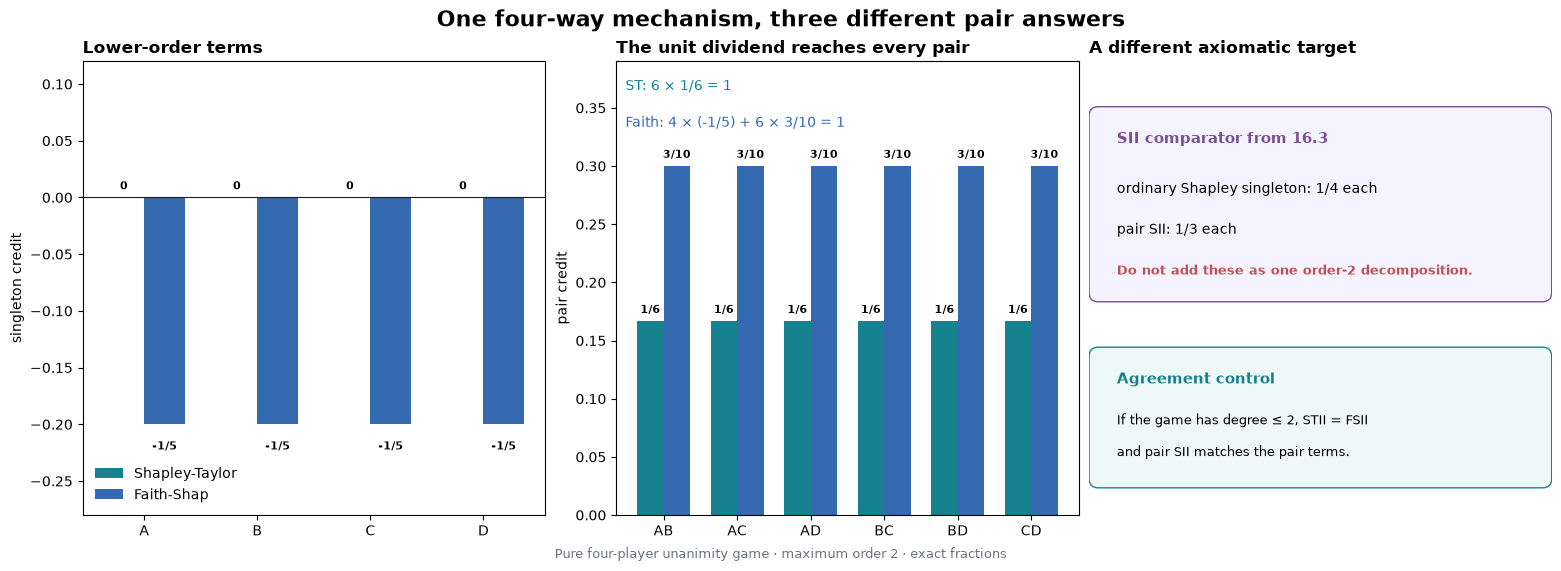

In [ ]:
exact_diagnostics = diagnose_reconstruction(exact_diagnostics, reconstruct_game, faithfulness_error)

allocation_figure = plot_exact_allocation_ledger(exact_diagnostics)

allocation_show_figure(allocation_figure, '01_exact_allocation_ledger')

## Reflect after the result — allocation-61

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

The first figure keeps SII physically separate from the two efficient decompositions. Its singleton
and pair strips are valid indices, but adding them would manufacture a total that SII never claims.

## Forecast before running — allocation-63

Predict why minimizing the kernel objective can move singleton coefficients while preserving efficiency.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


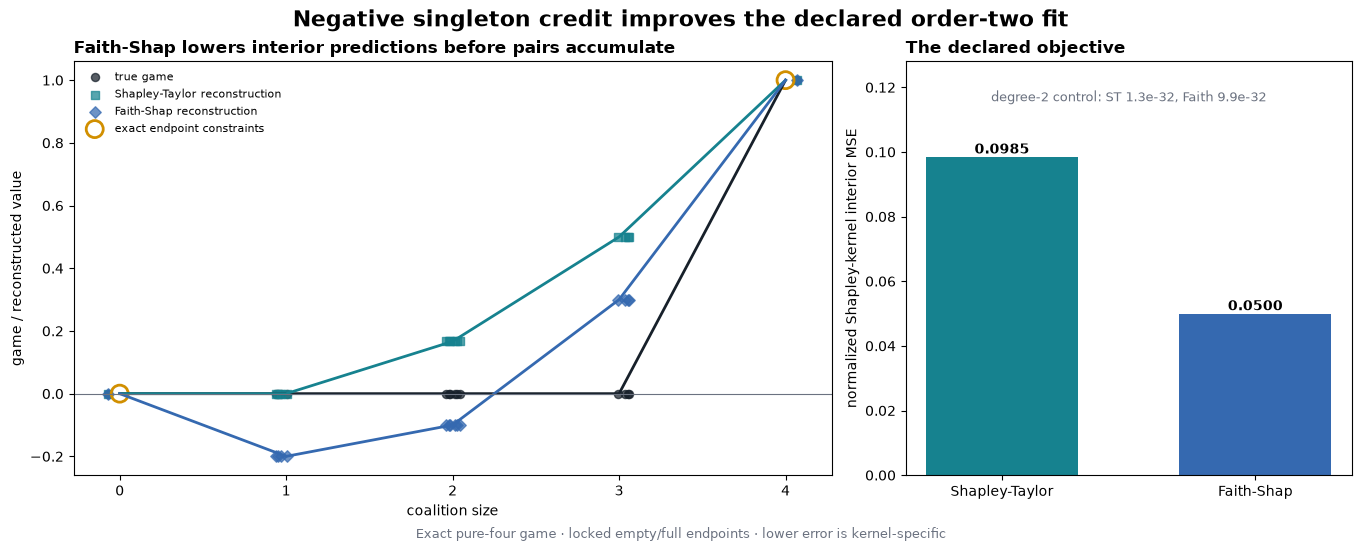

In [ ]:
allocation_figure = plot_reconstruction_reason(exact_diagnostics)

allocation_show_figure(allocation_figure, '02_why_faith_moves_singletons')

## Reflect after the result — allocation-63

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

For the pure four-way table, Shapley-Taylor reconstructs coalition-size means
`[0, 0, 1/6, 1/2, 1]`; Faith-Shap reconstructs `[0, -1/5, -1/10, 3/10, 1]`.
The negative singleton is doing visible approximation work on the interior coalitions.

## 5️⃣ From a model to a complete finite game

## Intact donors define the missing-feature operation

For a scalar model $f$, query $x$, donor row $z_b$, and coalition $S$, define the hybrid

$$
h_i(x,z_b,S)=\begin{cases}x_i&i\in S\\z_{b,i}&i\notin S,\end{cases}
$$

and the finite-background game

$$
v_{x,B}(S)=\frac{1}{|B|}\sum_{b\in B}f(h(x,z_b,S)).
$$

All absent features come from the **same intact donor row**. Sampling each missing coordinate from a
different marginal would define a different game. The empty value is the donor-bank mean prediction;
the full value is the query prediction.

For example, with query `(10, 20, 30)`, donor `(1, 2, 3)`, and mask `101`, the hybrid is
`(10, 2, 30)`: the middle coordinate comes from that same donor. A second donor produces a second
complete hybrid, and only then do we average their model outputs.

### Exercise 7 - implement `masked_model_game`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 20 minutes on this exercise.
> ```

Your scientific task is the intact hybrid and donor average. The supplied
`_interaction_game_batches` context validates inputs, preserves model state, and
enumerates the row × coalition × donor grid in bounded chunks. It yields the
number of rows, coalitions, and donors, followed by an iterator of batches.
Each batch gives you `query_rows`, `donor_rows`, `present`, and `slots`.

Use the first three arrays to build the hybrids with `torch.where`. Evaluate the
model through `_interaction_model_output`, accumulate its predictions into the
row/coalition `slots`, and divide each accumulated sum by the donor count.
You implement the missing-feature operation and its expectation; the supplied
context handles chunk indices and restores model/RNG state on exit.

## Forecast before running — allocation-68

Forecast how changing an intact donor bank changes the replacement game, not merely sampling error.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def masked_model_game(model: nn.Module, x: allocation_Tensor, reference: allocation_Tensor, *, coalition_batch_size: int=4096) -> allocation_Tensor:
    """Return games using one reference [D] or an equal-weight bank [B,D]."""
    with _interaction_game_batches(model, x, reference, coalition_batch_size=coalition_batch_size) as (rows, coalitions, donors, batches):
        sums = torch.zeros(rows * coalitions, dtype=torch.float64)
        raise NotImplementedError()


allocation_tests.test_masked_model_game(fn=masked_model_game)

<details><summary>Solution</summary>

```python
def masked_model_game(model: nn.Module, x: allocation_Tensor, reference: allocation_Tensor, *, coalition_batch_size: int=4096) -> allocation_Tensor:
    """Return games using one reference [D] or an equal-weight bank [B,D]."""
    with _interaction_game_batches(model, x, reference, coalition_batch_size=coalition_batch_size) as (rows, coalitions, donors, batches):
        sums = torch.zeros(rows * coalitions, dtype=torch.float64)
        for query_rows, donor_rows, present, slots in batches:
            inputs = torch.where(present, query_rows, donor_rows)
            output = _interaction_model_output(model, inputs)
            sums.index_add_(0, slots, output)
        return sums.div(donors).reshape(rows, coalitions).detach()

allocation_tests.test_masked_model_game(fn=masked_model_game)
```
</details>

## Reflect after the result — allocation-68

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

```text
All tests in test_masked_model_game passed!
```

The two-row, three-feature linear fixture returns shape `(2,8)`. Mask zero equals the mean donor
prediction, mask seven equals each query prediction, and all Möbius terms above order one are zero to
`1e-15`. RNG state, default dtype, module modes, buffers, and parameter gradients are restored on
successful and failing forwards.

</details>

<details>
<summary>Help - construct one intact hybrid</summary>

The three input arrays in a batch have the same `[batch, features]` shape. Use
`torch.where(present, query_rows, donor_rows)`. A false entry selects from the
matching donor row; it never selects a different donor independently per feature.
Check the mask `101` example above before thinking about the accumulation.

</details>

<details>
<summary>Help - turn donor predictions into a complete game</summary>

Several predictions belong to each row/coalition slot: one per donor. Accumulate
with `sums.index_add_(0, slots, output)` so a chunk boundary cannot discard part
of a donor average. After consuming all batches, divide by `donors` and reshape
to `(rows, coalitions)`. Dividing by the chunk size would be wrong: the final
chunk can be shorter, and a slot can span two chunks.

</details>

<details>
<summary>Interpretation</summary>

What changes when you switch from one donor to a 64-row donor bank?

The explanation game changes from one reference recipe to an equal-weight empirical population. The
new interaction is not a confidence replicate of the old one; it answers a different finite-game
question.

</details>

In [ ]:
class _AdditiveDiagnosticModel(nn.Module):

    def forward(self, inputs: allocation_Tensor) -> allocation_Tensor:
        return 1.0 + 0.5 * inputs[:, 0] + 0.25 * inputs[:, 1].square() + torch.relu(inputs[:, 2])

def _additive_formula(inputs: allocation_Tensor) -> allocation_Tensor:
    return 1.0 + 0.5 * inputs[..., 0] + 0.25 * inputs[..., 1].square() + torch.relu(inputs[..., 2])

def diagnose_model_game(masked_model_game_fn: Callable[..., allocation_Tensor]) -> dict[str, allocation_Any]:
    """Exercise one donor-averaged model game with an additive nonlinear control."""
    _callable('masked_model_game_fn', masked_model_game_fn)
    model = _AdditiveDiagnosticModel().to(dtype=torch.float64)
    query = torch.tensor([[2.0, -1.0, 0.5]], dtype=torch.float64)
    donors = torch.tensor([[0.0, 0.0, -1.0], [1.0, -2.0, 1.0]], dtype=torch.float64)
    observed = masked_model_game_fn(model, query, donors, coalition_batch_size=3)
    masks = torch.arange(8, dtype=torch.int64)
    present = masks[:, None].bitwise_and(1 << torch.arange(3, dtype=torch.int64)).ne(0)
    hybrid = torch.where(present[:, None, :], query[:, None, :], donors[None, :, :])
    expected = _additive_formula(hybrid).mean(dim=1).unsqueeze(0)
    torch.testing.assert_close(observed, expected, rtol=0, atol=1e-12)
    mobius = observed.clone()
    for player in range(3):
        selected = masks.bitwise_and(1 << player).ne(0)
        mobius[..., selected] -= mobius[..., masks[selected].bitwise_xor(1 << player)]
    pair_masks = torch.tensor([3, 5, 6], dtype=torch.int64)
    torch.testing.assert_close(mobius[..., pair_masks], torch.zeros((1, 3), dtype=torch.float64), rtol=0, atol=1e-12)
    return {'evidence_kind': 'analytic_exact', 'label': 'nonlinear additive donor-game control', 'feature_names': ('linear', 'square', 'ReLU'), 'query': query, 'donors': donors, 'game_values': observed, 'expected_game_values': expected, 'mobius': mobius, 'pair_max_abs': float(mobius[..., pair_masks].abs().max().item()), 'units': 'fixture output units'}

In [ ]:
model_game_diagnostic = diagnose_model_game(masked_model_game)

print('max |pair Möbius term|:', model_game_diagnostic['pair_max_abs'])

## A pair derivative opens four coalition values

For a pair $\{i,j\}$ disjoint from context $T$,

$$
\Delta_{ij}v(T)=v(T\cup\{i,j\})-v(T\cup\{i\})-v(T\cup\{j\})+v(T).
$$

This quantity may change sign across contexts. Shapley-Taylor, Faith-Shap, and SII aggregate
higher-order structure differently; none is required to equal the derivative at the empty or full
context.

### Exercise 8 - implement `contextual_pair_synergy`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 15 minutes on this exercise.
> ```

Validate the pair, generate every disjoint context when none is supplied, or validate and sort the
provided contexts. Index the four masks without a Python loop over leading batch items.

## Forecast before running — allocation-77

Predict a pair intervention in two contexts, and distinguish a contextual derivative from averaged SII.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def contextual_pair_synergy(game_values: allocation_Tensor, pair: tuple[int, int], *, n_players: int, context_masks: allocation_Tensor | None=None) -> tuple[allocation_Tensor, allocation_Tensor]:
    """Return sorted valid context masks and Delta_pair v(context)."""
    raise NotImplementedError()


allocation_tests.test_contextual_pair_synergy(fn=contextual_pair_synergy)

<details><summary>Solution</summary>

```python
def contextual_pair_synergy(game_values: allocation_Tensor, pair: tuple[int, int], *, n_players: int, context_masks: allocation_Tensor | None=None) -> tuple[allocation_Tensor, allocation_Tensor]:
    """Return sorted valid context masks and Delta_pair v(context)."""
    n_players = _interaction_n_players(n_players, minimum=2)
    _interaction_tensor('game_values', game_values, n_players)
    if type(pair) is not tuple or len(pair) != 2 or any((type(player) is not int for player in pair)):
        raise TypeError('pair must contain exactly two integer player indices.')
    first, second = pair
    if first == second:
        raise ValueError('pair must contain two different players.')
    if not 0 <= first < n_players or not 0 <= second < n_players:
        raise ValueError('pair players must lie in [0, n_players).')
    pair_mask = 1 << first | 1 << second
    if context_masks is None:
        contexts = torch.tensor([mask for mask in range(2 ** n_players) if mask & pair_mask == 0], dtype=torch.int64)
    else:
        if type(context_masks) is not allocation_Tensor:
            raise TypeError('context_masks must be a torch.Tensor.')
        if context_masks.device.type != 'cpu' or context_masks.dtype != torch.int64:
            raise TypeError('context_masks must be a CPU int64 tensor.')
        if context_masks.ndim != 1 or context_masks.numel() == 0:
            raise ValueError('context_masks must be a nonempty one-dimensional tensor.')
        if context_masks.min() < 0 or context_masks.max() >= 2 ** n_players:
            raise ValueError('Every context mask must index the complete game.')
        if context_masks.bitwise_and(pair_mask).ne(0).any():
            raise ValueError('Context masks must be disjoint from the requested pair.')
        contexts = context_masks.sort().values
    with_first = contexts.bitwise_or(1 << first)
    with_second = contexts.bitwise_or(1 << second)
    with_pair = contexts.bitwise_or(pair_mask)
    synergy = game_values[..., with_pair] - game_values[..., with_first] - game_values[..., with_second] + game_values[..., contexts]
    return (contexts, synergy)

allocation_tests.test_contextual_pair_synergy(fn=contextual_pair_synergy)
```
</details>

## Reflect after the result — allocation-77

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

```text
All tests in test_contextual_pair_synergy passed!
```

For a three-player game with pair dividend `2` and triple dividend `3`, pair `(0,1)` has contexts
`[0,4]` and signed derivatives `[2,5]`. A leading batch scaled by `-2` returns `[-4,-10]`.

</details>

<details>
<summary>Help - build the pair mask once</summary>

Set `pair_mask = (1 << first) | (1 << second)`. Valid contexts satisfy
`context & pair_mask == 0`. The four lookup axes are context, context plus the first bit, context
plus the second bit, and context plus both bits.

</details>

<details>
<summary>Interpretation</summary>

Why does an independently re-run four-forward check matter if the complete game table already
contains these values?

It catches a wrong mask convention or second-difference sign in the stored table lookup. Agreement
is an implementation control. It does not turn the replacement into a physical intervention.

</details>

In [ ]:
def diagnose_pair_context(contextual_pair_synergy_fn: Callable[..., tuple[allocation_Tensor, allocation_Tensor]]) -> dict[str, allocation_Any]:
    """Show where a pure triple's pair derivative switches on."""
    _callable('contextual_pair_synergy_fn', contextual_pair_synergy_fn)
    fixture = exact_game_fixture()
    game = fixture['game_values'][GAME_NAMES.index('pure_triple')]
    contexts, synergy = contextual_pair_synergy_fn(game, (0, 1), n_players=4)
    expected_contexts = torch.tensor([0, 4, 8, 12], dtype=torch.int64)
    expected_synergy = torch.tensor([0.0, 1.0, 0.0, 1.0], dtype=torch.float64)
    torch.testing.assert_close(contexts, expected_contexts, rtol=0, atol=0)
    torch.testing.assert_close(synergy, expected_synergy, rtol=0, atol=1e-12)
    full_context = 12
    four_masks = torch.tensor([full_context, full_context | 1, full_context | 2, full_context | 3], dtype=torch.int64)
    return {'evidence_kind': 'analytic_exact', 'label': 'pure-triple contextual pair diagnostic', 'pair': (0, 1), 'contexts': contexts, 'synergy': synergy, 'full_context_mask': full_context, 'four_masks': four_masks, 'four_values': game[four_masks], 'pair_sii': float(fixture['sii_pairs'][GAME_NAMES.index('pure_triple'), 0].item())}

In [ ]:
pair_context_diagnostic = diagnose_pair_context(contextual_pair_synergy)

print('contexts:', pair_context_diagnostic['contexts'].tolist())

print('pair derivatives:', pair_context_diagnostic['synergy'].tolist())

In [ ]:
allocation_methods = allocation_SimpleNamespace(mobius_transform=mobius_transform, shapley_taylor_interactions=shapley_taylor_interactions, faith_design_matrix=faith_design_matrix, faith_kernel_weights=faith_kernel_weights, faith_shap_interactions=faith_shap_interactions, faith_shap_closed_form=faith_shap_closed_form, reconstruct_game=reconstruct_game, faithfulness_error=faithfulness_error, masked_model_game=masked_model_game, contextual_pair_synergy=contextual_pair_synergy)

## Try It Yourself: reroute a dividend

This exact play is available before any native fit. Change `PLAY_MEMBERS`, `PLAY_VALUE`, or
`PLAY_ORDER`, then predict the allocation before running it. Try a pure triple at order two, and then
set the retained order equal to the dividend degree.

In [ ]:
PLAY_N = 4

PLAY_MEMBERS = (0, 1, 2, 3)

PLAY_VALUE = 1.0

PLAY_ORDER = 2

dividend_play = exact_dividend_play(methods=allocation_methods, n_players=PLAY_N, members=PLAY_MEMBERS, value=PLAY_VALUE, order=PLAY_ORDER)

explained_play = dividend_play['explained']

retained_masks = [mask for mask in range(1, 2 ** PLAY_N) if mask.bit_count() <= PLAY_ORDER]

for label, values in (('Shapley-Taylor', explained_play['stii_coefficients']), ('Faith-Shap', explained_play['fsii_coefficients'])):
    nonzero = {f'{mask:0{PLAY_N}b}': round(float(values[mask]), 6) for mask in retained_masks if abs(float(values[mask])) > 1e-12}
    print(f'{label:15s}', nonzero)

<details>
<summary>Ideas to try</summary>

1. Use `PLAY_MEMBERS=(0,1,2)`: predict Shapley-Taylor `0, 1/3` and Faith-Shap
   `-1/6, 1/2` for contained singletons and pairs.
2. Use a negative value. Every method should change sign without changing its allocation fractions.
3. Use `PLAY_ORDER=len(PLAY_MEMBERS)`. Both efficient methods should recover the literal Möbius
   dividend rather than route it downward.

</details>

## Plot the dividend you chose

The earlier exact play remains in memory. This figure places its Shapley-Taylor, Faith-Shap, and SII
allocations beside the same-game reconstruction errors.

## Forecast before running — allocation-88

Commit a changed dividend and forecast both efficient decompositions before the exploratory plot.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


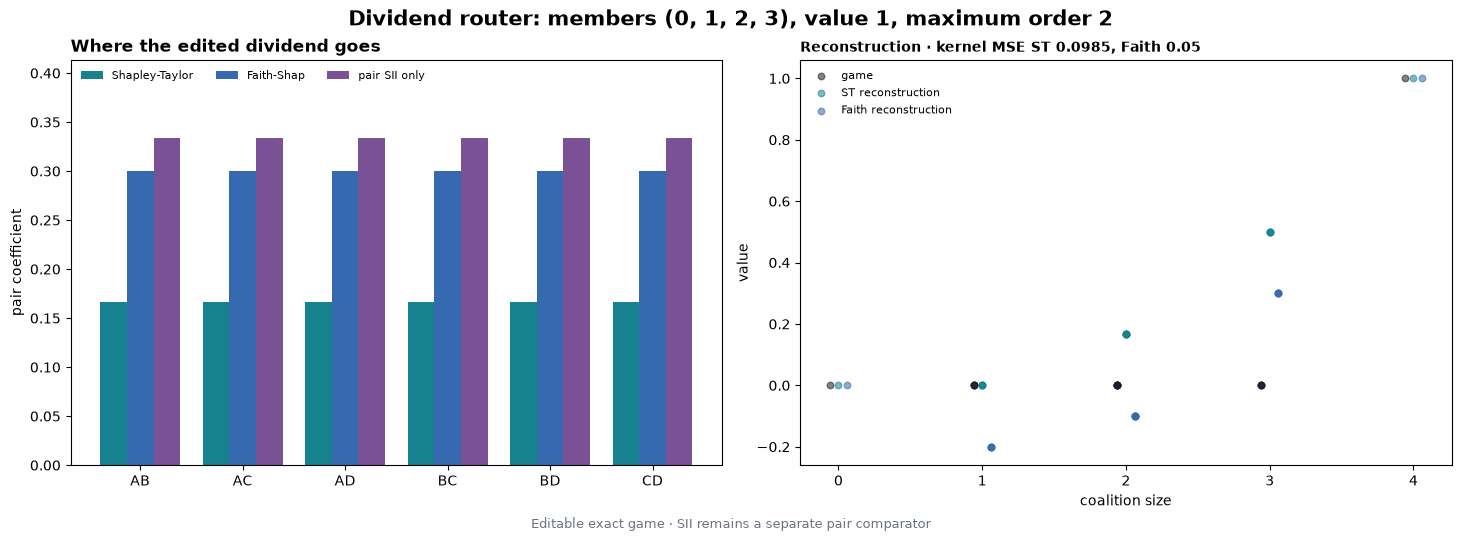

In [ ]:
allocation_figure = plot_dividend_play(dividend_play)

allocation_show_figure(allocation_figure, '10_dividend_play')

## Reflect after the result — allocation-88

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

## 6️⃣ Guided native capstone: the same game, different allocation rules

## The finite Concrete replacement game

The native study reuses the known UCI Concrete split and predictor recipe from 16.14/16.15 so that
the interaction definition is the variable:

- eight input features and raw compressive-strength output in MPa;
- 758 training rows, 153 explanation rows, and 119 audit rows in disjoint recipe groups;
- three clean ReLU MLP seeds, three matched shuffled-target controls, and ridge;
- all seven models, all 272 held-out rows, all 256 masks, and the ordered primary bank of 64 intact
  training donors; and
- order-two Shapley-Taylor, Faith-Shap, and pair SII on the same complete games.

Five background designs are retained for `clean_0`; each defines a different finite game. Ridge is
the additive control. Shuffled-target models are predictive controls, not zero-interaction oracles.

The path is: **fit the seven models → build their complete games → compare the allocations**.
You already wrote the scientific operations. The supplied study runners below apply them consistently;
their code is expandable in JupyterLab and on the instruction page. Open and edit it whenever you want
to trace a calculation. The short calling cells remain the main path.

This is a self-contained reproduction of a known seeded model/data procedure, not an independent
model or dataset replication.

<details>
<summary>Question - why retain donor-level predictions after averaging the game?</summary>

The average alone cannot prove that every absent feature came from one intact row. Donor-level
predictions preserve that construction and let the editable microscope show signed cancellation
across real donor recipes.

</details>

## Independent exact-game reference adapter

The primary-paper and `shapiq` comparisons are supporting evidence rather than another student
method. Their small-game checks run during preparation; the exhaustive 2,992-game empirical check
runs once after evaluation. The wrapper is visible so the learner can see exactly which arrays and
scope enter the benchmark.

In [ ]:
def reference_check(game_values: allocation_np.ndarray | torch.Tensor, student_stii: allocation_np.ndarray | torch.Tensor, student_fsii: allocation_np.ndarray | torch.Tensor, student_sii_pairs: allocation_np.ndarray | torch.Tensor, *, n_players: int, order: int, expected_game_count: int | None=None) -> dict[str, allocation_Any]:
    """Validate every supplied complete game with independent and direct package references."""
    with _preserve_execution_state():
        return _reference_check_impl(game_values, student_stii, student_fsii, student_sii_pairs, n_players=n_players, order=order, expected_game_count=expected_game_count)

def validate_exact_reference_suite(prepared: allocation_Mapping[str, allocation_Any]) -> dict[str, allocation_Any]:
    """Revalidate the retained 8 fixed, 45 random-order, and 5 boundary cases."""
    with _preserve_execution_state():
        if not isinstance(prepared, allocation_Mapping) or prepared.get('phase') != 'prepared_before_audit':
            raise ValueError('prepared must be the sealed pre-audit study payload.')
        return _validate_exact_suite(prepared)

def finalize_study_reference(prepared: allocation_Mapping[str, allocation_Any], empirical_reference: allocation_Mapping[str, allocation_Any]) -> dict[str, allocation_Any]:
    """Validate and augment an existing all-2,992 empirical result without package calls."""
    with _preserve_execution_state():
        payload_validation = validate_reference_payload(empirical_reference, expected_game_count=2992)
        exact_validation = validate_exact_reference_suite(prepared)
        result = dict(empirical_reference)
        result['counts'] = dict(empirical_reference['counts'])
        result['exact_suite_validation'] = exact_validation
        result['payload_validation'] = payload_validation
        result['counts'].update({'primary_games': 1904, 'nonprimary_clean0_games': 1088, 'models': 7, 'rows_per_model': 272, 'background_variants': 4, 'fixed_unique_exact_games': exact_validation['fixed_unique_games'], 'random_unique_exact_games': exact_validation['random_unique_games'], 'random_game_order_cases': exact_validation['random_game_order_cases'], 'random_STII_plus_FSII_case_calls': exact_validation['random_STII_plus_FSII_case_calls'], 'boundary_order_n_cases': exact_validation['boundary_order_n_cases'], 'exact_direct_shapiq_exact_computers': exact_validation['direct_shapiq_exact_computers'], 'exact_direct_shapiq_index_calls': exact_validation['direct_shapiq_index_calls'], 'all_reference_direct_shapiq_exact_computers': 2992 + exact_validation['direct_shapiq_exact_computers'], 'all_reference_direct_shapiq_index_calls': 2992 * 3 + exact_validation['direct_shapiq_index_calls'], 'all_reference_student_full_axis_coordinates': result['counts']['student_full_axis_coordinates'] + exact_validation['student_full_axis_coordinates'], 'all_reference_independent_vs_package_relevant_coordinates': result['counts']['independent_vs_package_relevant_coordinates'] + exact_validation['independent_vs_package_relevant_coordinates'], 'all_reference_raw_package_returned_coordinates': result['counts']['raw_package_returned_coordinates'] + exact_validation['raw_package_returned_coordinates']})
        if result.get('status') != 'PASS' or result['counts']['all_reference_direct_shapiq_exact_computers'] != 3050 or result['counts']['all_reference_direct_shapiq_index_calls'] != 9150:
            raise AssertionError('The complete exact plus empirical reference scope is invalid.')
        return result

In [ ]:
reference_methods = allocation_SimpleNamespace(reference_check=reference_check)

## The preparation boundary

We use explanation rows to choose the pair order, then measure it once on separate audit rows.
This keeps the held-out comparison useful even when the explanation rankings look surprising.

<details>
<summary>How leakage is prevented, and what is retained</summary>

Training, exact fixtures, primary explanation games, method outputs, and complete explanation-side
pair orders are fixed and persisted before audit access. The local display defaults are content-blind:
`clean_0`, explanation source ID `0`, pair `(0,1)`, primary donor ID `173`, and full context mask
`252`. No audit value chooses a model, row, pair, donor, background, tolerance, or plot.

The primary donor predictions have logical shape `[7,272,256,64]`; averaging the last axis produces
1,904 complete games. Explanation and audit donor predictions are stored in separate physical files,
and the explanation files are sealed before loading the audit split. Four additional background
games per row retain their own donor predictions. Full method outputs, reference comparisons, and
controls stay available in the evidence, including signs, zero denominators, and unfavorable results.

The execution cell checks the frozen protocol and recorded review disposition before loading data or
fitting a model. A development run with independent review still pending cannot be published as a
completed section. [The protocol](protocol.md) records the full counts, seeds, and acceptance rules.

</details>

In [ ]:
FEATURES = 8

HIDDEN = 32

EMPIRICAL_ORDER = 2

TRAINING_STEPS = 800

LEARNING_RATE = 0.003

WEIGHT_DECAY = 0.0001

RIDGE_PENALTY = 0.01

FORWARD_BATCH = 32768

DISTANCE_BATCH = 2048

MODEL_KEYS = ('clean_0', 'clean_1', 'clean_2', 'shuffled_0', 'shuffled_1', 'shuffled_2', 'ridge')

MODEL_SEEDS = (161410, 161411, 161412)

SHUFFLE_SEEDS = (161420, 161421, 161422)

BACKGROUND_SPECS = {'primary64': (161460, 64), 'nested16': (161460, 16), 'nested128': (161460, 128), 'independent64_a': (161461, 64), 'independent64_b': (161462, 64)}

METHOD_KEYS = ('sii', 'stii', 'fsii')

METHOD_NAMES = ('mobius_transform', 'shapley_taylor_interactions', 'faith_design_matrix', 'faith_kernel_weights', 'faith_shap_interactions', 'faith_shap_closed_form', 'reconstruct_game', 'faithfulness_error', 'masked_model_game', 'contextual_pair_synergy')

FEATURE_NAMES = ('Cement', 'Slag', 'Fly ash', 'Water', 'Superplasticizer', 'Coarse aggregate', 'Fine aggregate', 'Age')

FEATURE_UNITS = ('kg/m3',) * 7 + ('days',)

TARGET_NAME = 'Compressive strength'

TARGET_UNIT = 'MPa'

RNG_NAMESPACE = 'arena16.16/shapley-interactions/v1'

RANDOM_EXACT_SEED = 161610

WITHIN_SIZE_SEED = 161611

RANDOM_PAIR_SEED = 161612

WITHIN_SIZE_REPLICATES = 128

RANDOM_PAIR_ORDERS = 256

SUPPORT_DONORS = 8

DEFAULT_PLAY = {'model_key': 'clean_0', 'source_id': 0, 'donor_source_id': 173, 'background_key': 'primary64', 'pair': (0, 1), 'context_mask': 252}

The next visible source group contains the known-model training recipe, raw-unit folding, and exact
21-state reproduction gate. A mismatch stops before any interaction game is constructed.

## Forecast before running — allocation-98

Before any model refit, distinguish21 known state checks from independent predictive replication.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def _train_mlp(model: allocation_t.nn.Sequential, x: allocation_t.Tensor, y: allocation_t.Tensor) -> tuple[dict[str, allocation_t.Tensor], allocation_t.Tensor]:
    """Run the visible fixed 800-step full-batch Adam training loop."""
    optimizer = allocation_t.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    losses = []
    model.train()
    for _ in range(TRAINING_STEPS):
        optimizer.zero_grad()
        loss = (model(x).squeeze(-1) - y).square().mean()
        loss.backward()
        optimizer.step()
        losses.append(loss.detach().clone())
    return (_clone_state(model.state_dict()), allocation_t.stack(losses))

def fit_known_models(train: allocation_Mapping[str, allocation_Any]) -> dict[str, allocation_Any]:
    """Reproduce all seven known predictors; callers enforce the freeze gate."""
    x, y, ids, groups = _rows(train, 'train')
    allocation_t.set_num_threads(4)
    allocation_t.use_deterministic_algorithms(True)
    normalization = _training_normalization(train)
    models: dict[str, allocation_Any] = {}
    for index, seed in enumerate(MODEL_SEEDS):
        models[f'clean_{index}'] = _fit_one_mlp(train, normalization, seed, None)
    for index, seed in enumerate(MODEL_SEEDS):
        models[f'shuffled_{index}'] = _fit_one_mlp(train, normalization, seed, SHUFFLE_SEEDS[index])
    models['ridge'] = _fit_ridge(train, normalization)
    for record in models.values():
        record['state_hashes'] = {'initial_state': tensor_mapping_sha256(record['initial_state']), 'standardized_state': tensor_mapping_sha256(record['standardized_state']), 'raw_folded_state': tensor_mapping_sha256(record['state'])}
    return {'phase': 'fitted_before_interactions', 'models': models, 'normalization': normalization, 'train_x_raw': x.clone(), 'train_y_raw': y.clone(), 'train_ids': ids.clone(), 'train_recipe_group_ids': groups.clone(), 'feature_names': FEATURE_NAMES, 'feature_units': FEATURE_UNITS, 'target_name': TARGET_NAME, 'target_unit': TARGET_UNIT}

def verify_known_reproduction(fitted: allocation_Mapping[str, allocation_Any], manifest: allocation_Mapping[str, allocation_Any]) -> dict[str, allocation_Any]:
    """Hard-fail unless all 21 known state hashes and fit identities agree."""
    _validate_fitted(fitted)
    expected = manifest.get('known_16_14_evidence', {}).get('model_state_hashes', {})
    if tuple(expected) != MODEL_KEYS:
        raise ValueError('Manifest must declare all seven known model hashes.')
    fields = {'initial_state': 'initial_state', 'standardized_state': 'standardized_state', 'raw_folded_state': 'state'}
    observed: dict[str, dict[str, str]] = {}
    mismatches: list[str] = []
    for key in MODEL_KEYS:
        record = fitted['models'][key]
        observed[key] = {label: tensor_mapping_sha256(record[field]) for label, field in fields.items()}
        for label in fields:
            if observed[key][label] != expected[key][label]:
                mismatches.append(f'{key}.{label}')
        if record.get('state_hashes') != observed[key]:
            mismatches.append(f'{key}.retained_state_hashes')
    train_ids = allocation_t.tensor(manifest.get('splits', {}).get('train', []), dtype=allocation_t.int64)
    if not allocation_t.equal(train_ids, fitted['train_ids']):
        mismatches.append('train_ids')
    recipe = manifest.get('model_recipe', {})
    recipe_matches = recipe.get('model_keys') == list(MODEL_KEYS) and recipe.get('model_seeds') == list(MODEL_SEEDS) and (recipe.get('shuffle_seeds') == list(SHUFFLE_SEEDS)) and (recipe.get('training_steps') == TRAINING_STEPS) and (recipe.get('learning_rate') == LEARNING_RATE) and (recipe.get('weight_decay') == WEIGHT_DECAY) and (recipe.get('ridge_penalty') == RIDGE_PENALTY)
    if not recipe_matches:
        mismatches.append('training_recipe')
    if mismatches:
        raise AssertionError('Known-model reproduction mismatch: ' + ', '.join(mismatches))
    return {'status': 'PASS', 'known_section': '16.14/16.15', 'model_state_hashes': observed, 'expected_model_state_hashes': expected, 'mismatches': (), 'state_comparisons': 21, 'training_recipe_match': True, 'train_ids_match': True, 'non_independent_replication': True}

## Reflect after the result — allocation-98

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

In [ ]:
freeze = validate_freeze()

manifest = load_manifest()

train = load_split('train')

explain = load_split('explain')

Before fitting, look at the actual replacement operation. The table uses the fixed explanation recipe
and donor. Mask `11111100` keeps the other six features from the query while replacing cement and
slag from the donor. These are the context values for the pair examined later.

In [ ]:
query_row = explain['x'][allocation_np.flatnonzero(explain['ids'] == 0).item()]

donor_row = train['x'][allocation_np.flatnonzero(train['ids'] == 173).item()]

preview_present = 252 & 1 << allocation_np.arange(8) != 0

allocation_display(allocation_pd.DataFrame({'feature': FEATURE_NAMES, 'unit': FEATURE_UNITS, 'query (source 0)': query_row, 'donor (source 173)': donor_row, 'hybrid 11111100': allocation_np.where(preview_present, query_row, donor_row), 'taken from': allocation_np.where(preview_present, 'query', 'donor')}).set_index('feature'))

In [ ]:
fitted = fit_known_models(train)

reproduction = verify_known_reproduction(fitted, manifest)

fitted = {**fitted, 'reproduction': reproduction}

print(f"All {reproduction['state_comparisons']} known model-state comparisons passed.")

The hybrid builder below retains each donor prediction before its equal-weight mean. Its batch size
is an engineering control only; it never changes the masks, rows, donors, models, or values.

In [ ]:
def donor_replacement_games(model: allocation_t.nn.Module, queries: allocation_t.Tensor, donors: allocation_t.Tensor, *, methods: allocation_Any, donor_source_ids: allocation_t.Tensor | None=None, coalition_batch_size: int=4096) -> dict[str, allocation_t.Tensor]:
    """Retain every single-donor game, then average the declared donor bank."""
    _require_methods(methods)
    x = _float_tensor(queries, 'queries', 2)
    background = _float_tensor(donors, 'donors', 2)
    if x.shape[1] != FEATURES or background.shape[1] != FEATURES or len(background) == 0:
        raise ValueError('queries and donors must contain eight-feature rows.')
    if not isinstance(coalition_batch_size, int) or coalition_batch_size <= 0:
        raise ValueError('coalition_batch_size must be positive.')
    if donor_source_ids is None:
        donor_source_ids = allocation_t.arange(len(background), dtype=allocation_t.int64)
    donor_source_ids = _int_tensor(donor_source_ids, 'donor_source_ids', 1)
    if donor_source_ids.shape != (len(background),) or len(allocation_t.unique(donor_source_ids)) != len(background):
        raise ValueError('donor_source_ids must uniquely identify every donor.')
    hybrid = allocation_t.empty((len(x), 2 ** FEATURES, len(background)), dtype=allocation_t.float64)
    for donor_index, donor in enumerate(background):
        game = methods.masked_model_game(model, x, donor, coalition_batch_size=coalition_batch_size)
        game = _float_tensor(game, 'single_donor_game', 2)
        if game.shape != (len(x), 2 ** FEATURES):
            raise ValueError('masked_model_game returned an unexpected shape.')
        hybrid[..., donor_index] = game
    return {'hybrid_prediction': hybrid, 'coalition_values': hybrid.mean(-1), 'donor_source_ids': donor_source_ids.clone()}

def evaluate_model_games(model: allocation_t.nn.Module, queries: allocation_t.Tensor, donors: allocation_t.Tensor, *, methods: allocation_Any, donor_source_ids: allocation_t.Tensor, coalition_batch_size: int=4096) -> dict[str, allocation_t.Tensor]:
    """Construct one retained donor game and compute every exact order-two output."""
    donor = donor_replacement_games(model, queries, donors, methods=methods, donor_source_ids=donor_source_ids, coalition_batch_size=coalition_batch_size)
    explained = explain_complete_games(donor['coalition_values'], methods=methods)
    return {**donor, **explained}

The exact-game block applies your ten functions to the fixed pure and mixed controls. Pair SII is a
separate transparent comparator. It is never concatenated with singleton Shapley values to create a
fake efficient decomposition.

In [ ]:
def pairwise_sii(game_values: allocation_t.Tensor, *, n_players: int) -> allocation_t.Tensor:
    """Compute the exact pair SII comparator in lexicographic pair order."""
    values = _float_tensor(game_values, 'game_values')
    if values.ndim < 1 or values.shape[-1] != 2 ** n_players or n_players < 2:
        raise ValueError('game_values must end in one complete game axis.')
    output = []
    for left, right in pair_indices(n_players).tolist():
        pair_mask = 1 << left | 1 << right
        contexts = [mask for mask in range(2 ** n_players) if mask & pair_mask == 0]
        score = allocation_t.zeros(values.shape[:-1], dtype=allocation_t.float64)
        denominator = allocation_math.factorial(n_players - 1)
        for context in contexts:
            size = int(context).bit_count()
            weight = allocation_math.factorial(size) * allocation_math.factorial(n_players - size - 2) / denominator
            delta = values[..., context | pair_mask] - values[..., context | 1 << left] - values[..., context | 1 << right] + values[..., context]
            score = score + weight * delta
        output.append(score)
    return allocation_t.stack(output, dim=-1)

def all_pair_context_synergies(game_values: allocation_t.Tensor, *, n_players: int, methods: allocation_Any) -> dict[str, allocation_t.Tensor]:
    """Apply the learner's local derivative to all pairs and valid contexts."""
    _require_methods(methods)
    values = _float_tensor(game_values, 'game_values')
    pairs = pair_indices(n_players)
    context_rows = []
    synergy_rows = []
    full_rows = []
    for left, right in pairs.tolist():
        contexts, synergy = methods.contextual_pair_synergy(values, (left, right), n_players=n_players)
        contexts = _int_tensor(contexts, 'context_masks', 1)
        synergy = _float_tensor(synergy, 'context_synergy')
        if synergy.shape != values.shape[:-1] + (len(contexts),):
            raise ValueError('contextual_pair_synergy returned an unexpected shape.')
        expected_full = 2 ** n_players - 1 ^ 1 << left ^ 1 << right
        positions = allocation_t.nonzero(contexts == expected_full).flatten()
        if len(positions) != 1:
            raise ValueError('The full pair context is absent or repeated.')
        context_rows.append(contexts)
        synergy_rows.append(synergy)
        full_rows.append(synergy[..., int(positions[0])])
    context_masks = allocation_t.stack(context_rows)
    context_synergy = allocation_t.stack(synergy_rows, dim=-2)
    return {'pair_indices': pairs, 'context_masks': context_masks, 'context_synergy': context_synergy, 'full_context_synergy': allocation_t.stack(full_rows, dim=-1), 'mean_abs_context_synergy': context_synergy.abs().mean(-1)}

def explain_complete_games(game_values: allocation_t.Tensor, *, methods: allocation_Any, n_players: int=FEATURES, order: int=EMPIRICAL_ORDER, include_contexts: bool=True) -> dict[str, allocation_t.Tensor]:
    """Apply every visible interaction method to a batch of complete games."""
    _require_methods(methods)
    values = _float_tensor(game_values, 'game_values')
    if values.ndim < 1 or values.shape[-1] != 2 ** n_players:
        raise ValueError('game_values must end in one complete bitmask axis.')
    mobius = methods.mobius_transform(values, n_players=n_players)
    mobius = _float_tensor(mobius, 'mobius')
    stii = methods.shapley_taylor_interactions(mobius, n_players=n_players, order=order)
    fsii = methods.faith_shap_interactions(values, n_players=n_players, max_order=order)
    closed = methods.faith_shap_closed_form(mobius, n_players=n_players, max_order=order)
    stii = _float_tensor(stii, 'stii_coefficients')
    fsii = _float_tensor(fsii, 'fsii_coefficients')
    closed = _float_tensor(closed, 'fsii_closed_form')
    expected_shape = values.shape
    if stii.shape != expected_shape or fsii.shape != expected_shape or closed.shape != expected_shape:
        raise ValueError('Interaction coefficient tensors must preserve the game shape.')
    ordinary_full = methods.shapley_taylor_interactions(mobius, n_players=n_players, order=1)
    singleton_masks = 1 << allocation_t.arange(n_players, dtype=allocation_t.int64)
    pairs = pair_indices(n_players)
    pair_masks = 1 << pairs[:, 0] | 1 << pairs[:, 1]
    sii = pairwise_sii(values, n_players=n_players)
    recon = allocation_t.stack([methods.reconstruct_game(stii, n_players=n_players), methods.reconstruct_game(fsii, n_players=n_players)])
    recon = _float_tensor(recon, 'reconstruction')
    residual = values.unsqueeze(0) - recon
    sizes = coalition_masks(n_players).sum(-1)
    rmse = allocation_t.stack([allocation_t.sqrt(residual[..., sizes == size].square().mean(-1)) for size in range(n_players + 1)], dim=-1)
    kernel_mse = allocation_t.stack([methods.faithfulness_error(values, stii, n_players=n_players), methods.faithfulness_error(values, fsii, n_players=n_players)])
    result = {'coalition_values': values, 'mobius': mobius, 'ordinary_shapley': ordinary_full[..., singleton_masks], 'sii_pairs': sii, 'stii_coefficients': stii, 'fsii_coefficients': fsii, 'fsii_closed_form': closed, 'fsii_closed_form_error': (fsii - closed).abs().amax(-1), 'pair_values': allocation_t.stack([sii, stii[..., pair_masks], fsii[..., pair_masks]], dim=-2), 'reconstruction': recon, 'residual': residual, 'kernel_mse': kernel_mse, 'rmse_by_size': rmse, 'efficiency_residual': allocation_t.stack([stii.sum(-1) - values[..., -1], fsii.sum(-1) - values[..., -1]]), 'pair_indices': pairs, 'pair_masks': pair_masks}
    if include_contexts:
        result.update(all_pair_context_synergies(values, n_players=n_players, methods=methods))
    return result

The preparation source now computes the primary explanation games, all exact method outputs,
recipe-group-weighted pair strengths, and complete 28-pair orders. It seals the physical explanation
donor shard before the audit split is loaded.

## Forecast before running — allocation-108

Before audit access, forecast explanation-derived pair rankings and their random-order control; state group weights.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def explanation_pair_rankings(pair_values: allocation_t.Tensor, recipe_group_ids: allocation_t.Tensor) -> dict[str, allocation_t.Tensor]:
    """Rank all 28 pairs from explanation groups without dropping any pair."""
    values = _float_tensor(pair_values, 'pair_values', 4)
    if values.shape[2:] != (len(METHOD_KEYS), allocation_math.comb(FEATURES, 2)):
        raise ValueError('pair_values must have shape [models, rows, 3, 28].')
    strengths = allocation_t.stack([_group_weighted_mean_abs(model_values, recipe_group_ids) for model_values in values])
    orders = allocation_t.argsort(strengths, dim=-1, descending=True, stable=True)
    return {'method_keys': METHOD_KEYS, 'pair_strength': strengths, 'pair_order': orders}

def fixed_random_pair_orders() -> dict[str, allocation_Any]:
    """Return all 256 content-independent random pair permutations."""
    orders = []
    seeds = []
    for replicate in range(RANDOM_PAIR_ORDERS):
        derived = _derived_seed(RANDOM_PAIR_SEED, replicate)
        seeds.append(derived)
        orders.append(allocation_np.random.Generator(allocation_np.random.PCG64(derived)).permutation(28))
    result = {'seed': RANDOM_PAIR_SEED, 'derived_seeds_hex': tuple((f'{value:032x}' for value in seeds)), 'orders': allocation_t.tensor(allocation_np.stack(orders), dtype=allocation_t.int64)}
    declared = load_manifest().get('rng_contract', {}).get('random_pair_order', {})
    if declared.get('derived_seeds_hex') != list(result['derived_seeds_hex']):
        raise ValueError('Random pair-order seeds differ from the manifest.')
    if declared.get('orders_value_sha256') != tensor_mapping_sha256({'orders': result['orders']}):
        raise ValueError('Random pair orders differ from the manifest.')
    return result

def prepare_study(fitted: allocation_Mapping[str, allocation_Any], train: allocation_Mapping[str, allocation_Any], explain: allocation_Mapping[str, allocation_Any], *, methods: allocation_Any, reference: allocation_Any | None=None, manifest: allocation_Mapping[str, allocation_Any] | None=None) -> dict[str, allocation_Any]:
    """Compute and seal every explanation-side decision before audit access."""
    _require_methods(methods)
    manifest = load_manifest() if manifest is None else manifest
    reproduction = verify_known_reproduction(fitted, manifest)
    train_x, train_y, train_ids, train_groups = _rows(train, 'train')
    explain_x, explain_y, explain_ids, explain_groups = _rows(explain, 'explain')
    _require_disjoint_ids(train=train_ids, explain=explain_ids)
    if not allocation_t.equal(train_x, fitted['train_x_raw']) or not allocation_t.equal(train_y, fitted['train_y_raw']):
        raise ValueError('Training values changed after fitting.')
    if not allocation_t.equal(train_ids, fitted['train_ids']) or not allocation_t.equal(train_groups, fitted['train_recipe_group_ids']):
        raise ValueError('Training identities changed after fitting.')
    expected_explain = allocation_t.tensor(manifest.get('splits', {}).get('explain', []), dtype=allocation_t.int64)
    if not allocation_t.equal(explain_ids, expected_explain):
        raise ValueError('Explanation source IDs differ from the pinned split.')
    backgrounds = _background_records(train_x, train_ids, manifest)
    primary = _evaluate_primary(fitted, explain_x, backgrounds['primary64'], methods=methods)
    variants = _evaluate_backgrounds(fitted, explain_x, backgrounds, primary, methods=methods)
    rankings = explanation_pair_rankings(primary['pair_values'], explain_groups)
    direct = _direct_full_context_four(fitted, explain_x, backgrounds['primary64']['x_raw'])
    direct['table_synergy'] = primary['full_context_synergy']
    direct['lookup_difference'] = direct['synergy'] - direct['table_synergy']
    design_contract = {}
    for order in (1, 2, 3):
        design, term_masks = methods.faith_design_matrix(n_players=FEATURES, max_order=order)
        design_contract[order] = {'design': _float_tensor(design, f'faith_design_{order}', 2), 'term_masks': _int_tensor(term_masks, f'term_masks_{order}', 1)}
    design_contract['kernel_weights'] = _float_tensor(methods.faith_kernel_weights(n_players=FEATURES), 'kernel_weights', 1)
    return {'phase': 'prepared_before_audit', 'audit_used_for_selection': False, 'reproduction': reproduction, 'feature_names': FEATURE_NAMES, 'feature_units': FEATURE_UNITS, 'target_name': TARGET_NAME, 'target_unit': TARGET_UNIT, 'model_keys': MODEL_KEYS, 'method_keys': METHOD_KEYS, 'mask_ids': allocation_t.arange(2 ** FEATURES, dtype=allocation_t.int64), 'coalition_masks': coalition_masks(FEATURES), 'coalition_sizes': coalition_masks(FEATURES).sum(-1).to(allocation_t.int64), 'pair_indices': pair_indices(FEATURES), 'context_masks': primary['context_masks'], 'design_contract': design_contract, 'train_ids': train_ids, 'train_recipe_group_ids': train_groups, 'explain_source_ids': explain_ids, 'explain_recipe_group_ids': explain_groups, 'explain_x_raw': explain_x, 'explain_targets': explain_y, 'backgrounds': backgrounds, 'exact_games': _exact_suite(methods, reference), 'primary64': primary, 'background_variants': variants, 'direct_full_context': direct, 'references': {'exact_suite_checked_in_preparation': reference is not None, 'empirical': _empirical_reference_plan('prepared_before_audit')}, 'rankings': rankings, 'random_pair_orders': fixed_random_pair_orders(), 'fixed_play_defaults': dict(DEFAULT_PLAY), 'source_provenance': dict(manifest.get('source_provenance', {})), 'storage_plan': _storage_plan(manifest, 'prepared_before_audit')}

## Reflect after the result — allocation-108

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

In [ ]:
prepared = prepare_study(fitted, train, explain, methods=allocation_methods, reference=reference_methods, manifest=manifest)

persist_prepared(native_directory, fitted, prepared)

assert prepared['phase'] == 'prepared_before_audit'

assert prepared['audit_used_for_selection'] is False

Only after that seal does the learner execute the literal audit load.

In [ ]:
audit = load_split('audit')

The evaluation source computes every prespecified audit game and method output once. It retains all
28 pairs, all seeds, all rows, all backgrounds, 256 random pair orders, the frozen within-size
shuffles, support distances, and direct four-forward checks. Odd results and zero denominators stay
in the payload.

## Forecast before running — allocation-113

Forecast audit capture versus all256 random orders and explain the zero-denominator convention.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def pair_capture_curves(pair_orders: allocation_t.Tensor, audit_full_context_synergy: allocation_t.Tensor, audit_recipe_group_ids: allocation_t.Tensor, random_orders: allocation_t.Tensor) -> dict[str, allocation_t.Tensor]:
    """Evaluate explanation-derived and random pair orders on every audit group."""
    orders = _int_tensor(pair_orders, 'pair_orders', 3)
    synergy = _float_tensor(audit_full_context_synergy, 'audit_full_context_synergy', 3)
    random = _int_tensor(random_orders, 'random_orders', 2)
    if orders.shape != (len(MODEL_KEYS), len(METHOD_KEYS), 28):
        raise ValueError('pair_orders must have shape [7,3,28].')
    if synergy.shape[0] != len(MODEL_KEYS) or synergy.shape[2] != 28:
        raise ValueError('audit_full_context_synergy must have shape [7,rows,28].')
    if random.shape != (RANDOM_PAIR_ORDERS, 28):
        raise ValueError('random_orders must have shape [256,28].')
    strength = allocation_t.stack([_group_weighted_mean_abs(model_values, audit_recipe_group_ids) for model_values in synergy])
    denominator = strength.sum(-1)
    zero = denominator == 0
    safe = allocation_t.where(zero, allocation_t.ones_like(denominator), denominator)
    observed = allocation_t.zeros((len(MODEL_KEYS), len(METHOD_KEYS), 29), dtype=allocation_t.float64)
    random_curves = allocation_t.zeros((len(MODEL_KEYS), RANDOM_PAIR_ORDERS, 29), dtype=allocation_t.float64)
    for model_index in range(len(MODEL_KEYS)):
        for method_index in range(len(METHOD_KEYS)):
            ordered = strength[model_index, orders[model_index, method_index]]
            observed[model_index, method_index, 1:] = ordered.cumsum(0) / safe[model_index]
        random_strength = strength[model_index][random]
        random_curves[model_index, :, 1:] = random_strength.cumsum(-1) / safe[model_index]
    observed[zero, :] = 0.0
    random_curves[zero, :] = 0.0
    return {'audit_full_context_strength': strength, 'capture_curves': observed, 'random_capture_curves': random_curves, 'zero_denominator': zero}

def within_size_shuffle_control(game_values: allocation_t.Tensor, observed_pair_values: allocation_t.Tensor, source_ids: allocation_t.Tensor, recipe_group_ids: allocation_t.Tensor, *, methods: allocation_Any) -> dict[str, allocation_Any]:
    """Build the fixed structural null while preserving endpoints and size marginals."""
    _require_methods(methods)
    values = _float_tensor(game_values, 'game_values', 2)
    if values.shape != (len(source_ids), 256):
        raise ValueError('The within-size control requires all audit D=8 games.')
    schedule = _within_size_permutations(source_ids)
    index = schedule['permutation'].to(allocation_t.int64)
    shuffled = allocation_t.gather(values[None, :, :].expand(WITHIN_SIZE_REPLICATES, -1, -1), 2, index)
    flat = shuffled.reshape(-1, 256)
    mobius = methods.mobius_transform(flat, n_players=FEATURES)
    stii = methods.shapley_taylor_interactions(mobius, n_players=FEATURES, order=2)
    fsii = methods.faith_shap_interactions(flat, n_players=FEATURES, max_order=2)
    pairs = pair_indices(FEATURES)
    pair_masks = 1 << pairs[:, 0] | 1 << pairs[:, 1]
    pair_values = allocation_t.stack([pairwise_sii(flat, n_players=FEATURES), stii[..., pair_masks], fsii[..., pair_masks]], dim=-2).reshape(WITHIN_SIZE_REPLICATES, len(values), len(METHOD_KEYS), 28)
    return {**schedule, 'method_keys': METHOD_KEYS, 'pair_values': pair_values, 'observed': _localization_statistics(observed_pair_values, recipe_group_ids), 'null': _localization_statistics(pair_values, recipe_group_ids), 'interpretation': 'structural null; not expected to have zero pair interaction'}

def background_sensitivity(variants: allocation_Mapping[str, allocation_Mapping[str, allocation_Any]]) -> dict[str, allocation_Any]:
    """Compare every clean_0 finite-background game with primary64."""
    if tuple(variants) != tuple(BACKGROUND_SPECS):
        raise ValueError('Background variants changed order or membership.')
    primary = variants['primary64']
    result = {}
    for name, item in variants.items():
        pair_movement = item['pair_values'] - primary['pair_values']
        result[name] = {'base_movement': item['coalition_values'][..., 0] - primary['coalition_values'][..., 0], 'prediction_movement': item['coalition_values'][..., -1] - primary['coalition_values'][..., -1], 'ordinary_shapley_movement': item['ordinary_shapley'] - primary['ordinary_shapley'], 'pair_movement': pair_movement, 'absolute_pair_movement': pair_movement.abs(), 'pair_sign_change': allocation_t.signbit(item['pair_values']) != allocation_t.signbit(primary['pair_values']), 'pair_rank_change': _pair_ranks(item['pair_values']) - _pair_ranks(primary['pair_values']), 'full_context_movement': item['full_context_synergy'] - primary['full_context_synergy']}
    return result

def evaluate_study(fitted: allocation_Mapping[str, allocation_Any], prepared: allocation_Mapping[str, allocation_Any], audit: allocation_Mapping[str, allocation_Any], *, methods: allocation_Any, reference: allocation_Any | None=None, manifest: allocation_Mapping[str, allocation_Any] | None=None) -> dict[str, allocation_Any]:
    """Evaluate every prespecified audit outcome without changing preparation."""
    _require_methods(methods)
    if prepared.get('phase') != 'prepared_before_audit' or prepared.get('audit_used_for_selection') is not False:
        raise ValueError('A sealed pre-audit preparation payload is required.')
    manifest = load_manifest() if manifest is None else manifest
    reproduction = verify_known_reproduction(fitted, manifest)
    audit_x, audit_y, audit_ids, audit_groups = _rows(audit, 'audit')
    expected_audit = allocation_t.tensor(manifest.get('splits', {}).get('audit', []), dtype=allocation_t.int64)
    if not allocation_t.equal(audit_ids, expected_audit):
        raise ValueError('Audit source IDs differ from the pinned split.')
    _require_disjoint_ids(train=fitted['train_ids'], explain=prepared['explain_source_ids'], audit=audit_ids)
    backgrounds = prepared['backgrounds']
    primary_audit = _evaluate_primary(fitted, audit_x, backgrounds['primary64'], methods=methods)
    variants_audit = _evaluate_backgrounds(fitted, audit_x, backgrounds, primary_audit, methods=methods)
    primary_all = _combine_game_blocks(prepared['primary64'], primary_audit, model_axis=True)
    variants_all = {name: _combine_game_blocks(prepared['background_variants'][name], variants_audit[name], model_axis=False) for name in BACKGROUND_SPECS}
    direct_audit = _direct_full_context_four(fitted, audit_x, backgrounds['primary64']['x_raw'])
    direct_audit['table_synergy'] = primary_audit['full_context_synergy']
    direct_audit['lookup_difference'] = direct_audit['synergy'] - direct_audit['table_synergy']
    direct_all = {leaf: allocation_t.cat([prepared['direct_full_context'][leaf], direct_audit[leaf]], dim=1) for leaf in ('four_values', 'synergy', 'table_synergy', 'lookup_difference')}
    random_orders = prepared['random_pair_orders']['orders']
    curves = pair_capture_curves(prepared['rankings']['pair_order'], primary_audit['full_context_synergy'], audit_groups, random_orders)
    null = within_size_shuffle_control(primary_audit['coalition_values'][0], primary_audit['pair_values'][0], audit_ids, audit_groups, methods=methods)
    all_x = allocation_t.cat([prepared['explain_x_raw'], audit_x])
    all_ids = allocation_t.cat([prepared['explain_source_ids'], audit_ids])
    all_groups = allocation_t.cat([prepared['explain_recipe_group_ids'], audit_groups])
    support = nearest_training_diagnostics(fitted['train_x_raw'], fitted['train_ids'], all_x, backgrounds['primary64']['x_raw'][:SUPPORT_DONORS], fitted['normalization'])
    row_split = allocation_t.cat([allocation_t.zeros(len(prepared['explain_source_ids']), dtype=allocation_t.int64), allocation_t.ones(len(audit_ids), dtype=allocation_t.int64)])
    return {'phase': 'evaluated_after_audit', 'audit_used_for_selection': False, 'reproduction': reproduction, 'feature_names': FEATURE_NAMES, 'feature_units': FEATURE_UNITS, 'target_name': TARGET_NAME, 'target_unit': TARGET_UNIT, 'model_keys': MODEL_KEYS, 'method_keys': METHOD_KEYS, 'source_ids': all_ids, 'row_split': row_split, 'split_labels': ('explanation', 'audit'), 'recipe_group_ids': all_groups, 'audit_source_ids': audit_ids, 'audit_recipe_group_ids': audit_groups, 'audit_x_raw': audit_x, 'audit_targets': audit_y, 'primary64_audit': primary_audit, 'background_variants_audit': variants_audit, 'all_rows': {'primary64': primary_all, 'background_variants': variants_all}, 'direct_full_context': direct_all, 'performance': {'explanation': _performance(fitted, prepared['explain_x_raw'], prepared['explain_targets']), 'audit': _performance(fitted, audit_x, audit_y)}, 'rankings': prepared['rankings'], 'pair_capture': {**curves, 'random_pair_orders': random_orders, 'method_keys': METHOD_KEYS}, 'random_controls': {'within_size': null}, 'background_sensitivity': background_sensitivity(variants_all), 'support': support, 'references': {'prepared': prepared['references'], 'empirical': _empirical_reference_plan('evaluated_after_audit'), 'adapter_supplied': reference is not None}, 'fixed_play_defaults': dict(DEFAULT_PLAY), 'source_provenance': dict(prepared.get('source_provenance', {})), 'storage_plan': _storage_plan(manifest, 'evaluated_after_audit')}

## Reflect after the result — allocation-113

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

In [ ]:
evaluated = evaluate_study(fitted, prepared, audit, methods=allocation_methods, manifest=manifest)

assert evaluated['phase'] == 'evaluated_after_audit'

assert evaluated['audit_used_for_selection'] is False

## Independent same-index references

The paper-formula reference recomputes Shapley-Taylor from discrete derivatives, Faith-Shap from the
closed form, and SII pairs independently for all 2,992 unique empirical games. Installed
`shapiq==1.5.2` is supporting exact-index evidence. Its finite endpoint penalty does not replace the
student's exact constrained solve, and this is not a SHAP-IQ estimator experiment.

In [ ]:
primary_reference = evaluated['all_rows']['primary64']

variant_references = evaluated['all_rows']['background_variants']

reference_blocks = [primary_reference] + [variant_references[name] for name in ('nested16', 'nested128', 'independent64_a', 'independent64_b')]

def flatten_reference_leaf(leaf: str) -> allocation_Tensor:
    return torch.cat([block[leaf].reshape(-1, block[leaf].shape[-1]) for block in reference_blocks])

empirical_reference = reference_check(flatten_reference_leaf('coalition_values'), flatten_reference_leaf('stii_coefficients'), flatten_reference_leaf('fsii_coefficients'), flatten_reference_leaf('sii_pairs'), n_players=8, order=2, expected_game_count=2992)

reference_branches = []

branch_start = 0

for name, block in zip(('primary64', 'nested16', 'nested128', 'independent64_a', 'independent64_b'), reference_blocks, strict=True):
    allocation_games = block['coalition_values'].numel() // 256
    reference_branches.append({'name': name, 'model_keys': MODEL_KEYS if name == 'primary64' else ('clean_0',), 'start': branch_start, 'stop': branch_start + allocation_games, 'games': allocation_games})
    branch_start += allocation_games

reference_result = finalize_study_reference(prepared, empirical_reference)

reference_result['branches'] = tuple(reference_branches)

print(reference_result['status'])

The fixed native payload uses the content-blind explanation-row defaults declared before audit
access. The persistence boundary retains the complete scientific arrays and reference result before
any editable post-study reuse.

In [ ]:
def empirical_context_play(evaluated: allocation_Mapping[str, allocation_Any], methods: allocation_Any, *, model_key: str='clean_0', source_id: int=0, background_key: str='primary64', pair: tuple[int, int]=(0, 1), context_mask: int=252, donor_source_id: int | None=None) -> dict[str, allocation_Any]:
    """Inspect a real retained row, donor bank, pair, and coalition context."""
    _require_methods(methods)
    if evaluated.get('phase') != 'evaluated_after_audit':
        raise ValueError('Use the complete evaluated payload.')
    if model_key not in MODEL_KEYS or background_key not in BACKGROUND_SPECS:
        raise ValueError('Unknown model or background key.')
    if background_key != 'primary64' and model_key != 'clean_0':
        raise ValueError('Alternate backgrounds are retained only for clean_0.')
    ids = _int_tensor(evaluated['source_ids'], 'source_ids', 1)
    positions = allocation_t.nonzero(ids == int(source_id)).flatten()
    if len(positions) != 1:
        raise ValueError('source_id is absent or repeated.')
    row_index = int(positions[0])
    left, right = pair
    if left == right or min(pair) < 0 or max(pair) >= FEATURES:
        raise ValueError('pair must contain two distinct valid players.')
    pair_mask = 1 << left | 1 << right
    if context_mask < 0 or context_mask >= 256 or context_mask & pair_mask:
        raise ValueError('context_mask must be valid and disjoint from the pair.')
    if background_key == 'primary64':
        primary = evaluated['all_rows']['primary64']
        model_index = MODEL_KEYS.index(model_key)
        block = {key: (value[:, model_index] if key in _METHOD_FIRST_LEAVES else value[model_index]) if isinstance(value, allocation_t.Tensor) and key not in _SHARED_GAME_LEAVES else value for key, value in primary.items() if key != 'model_keys'}
        hybrid_meta = primary['hybrid_prediction']
        block['hybrid_prediction'] = {**hybrid_meta, 'explain': hybrid_meta['explain'][model_index], 'audit': hybrid_meta['audit'][model_index]}
    else:
        block = evaluated['all_rows']['background_variants'][background_key]
    hybrid_row = _logical_hybrid_row(block, row_index, evaluated['row_split'])
    donor_ids = block['donor_source_ids']
    if donor_source_id is None:
        game = block['coalition_values'][row_index]
        donor_values = hybrid_row
        selected_donor_ids = donor_ids
        game_label = 'equal_weight_donor_bank'
    else:
        donor_positions = allocation_t.nonzero(donor_ids == int(donor_source_id)).flatten()
        if len(donor_positions) != 1:
            raise ValueError('donor_source_id is not in the selected background.')
        donor_index = int(donor_positions[0])
        game = hybrid_row[:, donor_index]
        donor_values = hybrid_row[:, donor_index:donor_index + 1]
        selected_donor_ids = donor_ids[donor_index:donor_index + 1]
        game_label = 'single_donor_game'
    masks = allocation_t.tensor([context_mask, context_mask | 1 << left, context_mask | 1 << right, context_mask | pair_mask], dtype=allocation_t.int64)
    four_by_donor = donor_values[masks]
    explained = explain_complete_games(game, methods=methods, n_players=FEATURES, order=2)
    pair_row = allocation_t.nonzero((pair_indices(FEATURES) == allocation_t.tensor(pair)).all(-1)).flatten()
    if len(pair_row) != 1:
        reverse = allocation_t.tensor((right, left), dtype=allocation_t.int64)
        pair_row = allocation_t.nonzero((pair_indices(FEATURES) == reverse).all(-1)).flatten()
    pair_index = int(pair_row[0])
    return {'kind': 'empirical_context_play', 'model_key': model_key, 'source_id': int(source_id), 'split': 'audit_reuse' if int(evaluated['row_split'][row_index]) else 'explanation', 'background_key': background_key, 'game_label': game_label, 'target_unit': TARGET_UNIT, 'donor_source_ids': selected_donor_ids, 'pair': tuple(pair), 'context_mask': int(context_mask), 'four_masks': masks, 'four_values_by_donor': four_by_donor, 'four_values': four_by_donor.mean(-1), 'local_synergy_by_donor': four_by_donor[3] - four_by_donor[1] - four_by_donor[2] + four_by_donor[0], 'local_synergy': game[masks[3]] - game[masks[1]] - game[masks[2]] + game[masks[0]], 'pair_values': explained['pair_values'][..., pair_index], 'method_keys': METHOD_KEYS, 'game_values': game.clone(), 'interprets_model_input_intervention_only': True}

In [ ]:
def native_play(evaluated: allocation_Mapping[str, allocation_Any], *, methods: allocation_Any) -> dict[str, allocation_Any]:
    """Assemble the fixed content-blind native result without live model objects."""
    if evaluated.get('phase') != 'evaluated_after_audit':
        raise ValueError('Run the complete frozen evaluation before native_play.')
    empirical = empirical_context_play(evaluated, methods, model_key=DEFAULT_PLAY['model_key'], source_id=DEFAULT_PLAY['source_id'], background_key=DEFAULT_PLAY['background_key'], pair=DEFAULT_PLAY['pair'], context_mask=DEFAULT_PLAY['context_mask'], donor_source_id=None)
    donor = empirical_context_play(evaluated, methods, model_key=DEFAULT_PLAY['model_key'], source_id=DEFAULT_PLAY['source_id'], background_key=DEFAULT_PLAY['background_key'], pair=DEFAULT_PLAY['pair'], context_mask=DEFAULT_PLAY['context_mask'], donor_source_id=DEFAULT_PLAY['donor_source_id'])
    ids = _int_tensor(evaluated['source_ids'], 'source_ids', 1)
    row_positions = allocation_t.nonzero(ids == DEFAULT_PLAY['source_id']).flatten()
    if len(row_positions) != 1:
        raise ValueError('The fixed source row is absent or repeated.')
    row_index = int(row_positions[0])
    primary = evaluated['all_rows']['primary64']
    clean_index = MODEL_KEYS.index('clean_0')
    ridge_index = MODEL_KEYS.index('ridge')
    fixed_row = {'model_key': 'clean_0', 'source_id': DEFAULT_PLAY['source_id'], 'background_key': 'primary64', 'order': EMPIRICAL_ORDER, 'donor_count': int(primary['donor_source_ids'].numel()), 'target_unit': TARGET_UNIT, 'pair_indices': primary['pair_indices'], 'stii_coefficients': primary['stii_coefficients'][clean_index, row_index], 'fsii_coefficients': primary['fsii_coefficients'][clean_index, row_index], 'sii_pairs': primary['sii_pairs'][clean_index, row_index], 'ridge_pair_max_abs': primary['pair_values'][ridge_index, row_index].abs().amax()}
    return {'phase': 'native_play_from_frozen_evaluation', 'fixed_defaults': dict(DEFAULT_PLAY), 'exact_dividend': exact_dividend_play(methods=methods), 'empirical_background_average': empirical, 'empirical_fixed_donor': donor, 'fixed_row': fixed_row, 'overview': {'feature_names': evaluated['feature_names'], 'feature_units': evaluated['feature_units'], 'target_name': evaluated['target_name'], 'target_unit': evaluated['target_unit'], 'model_keys': evaluated['model_keys'], 'method_keys': evaluated['method_keys'], 'source_ids': evaluated['source_ids'], 'row_split': evaluated['row_split'], 'performance': evaluated['performance'], 'rankings': evaluated['rankings'], 'pair_capture': evaluated['pair_capture'], 'background_sensitivity': evaluated['background_sensitivity'], 'direct_full_context': evaluated['direct_full_context']}}

In [ ]:
diagnostics = interaction_diagnostics(prepared, evaluated, reference_result)

allocation_play = native_play(evaluated, methods=allocation_methods)

publication_summary = persist_completed(native_directory, fitted, prepared, evaluated, reference_result, diagnostics, allocation_play, timings={})

write_notebook_summary(FIGURE_DIR, native_directory, publication_summary)

print('Complete games, controls and reference checks retained. Read the figures below.')

## Read the native result in layers

The figures below are deliberately separate. Predictive quality establishes the model controls;
signed matrices show every term; capture curves assess a frozen ordering against a declared input
intervention; reconstruction plots show the exact objective each method optimizes. None selects a
winner across axioms.

## Forecast before running — allocation-122

Forecast ridge and shuffled-model controls without assuming shuffled predictors have zero interactions.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


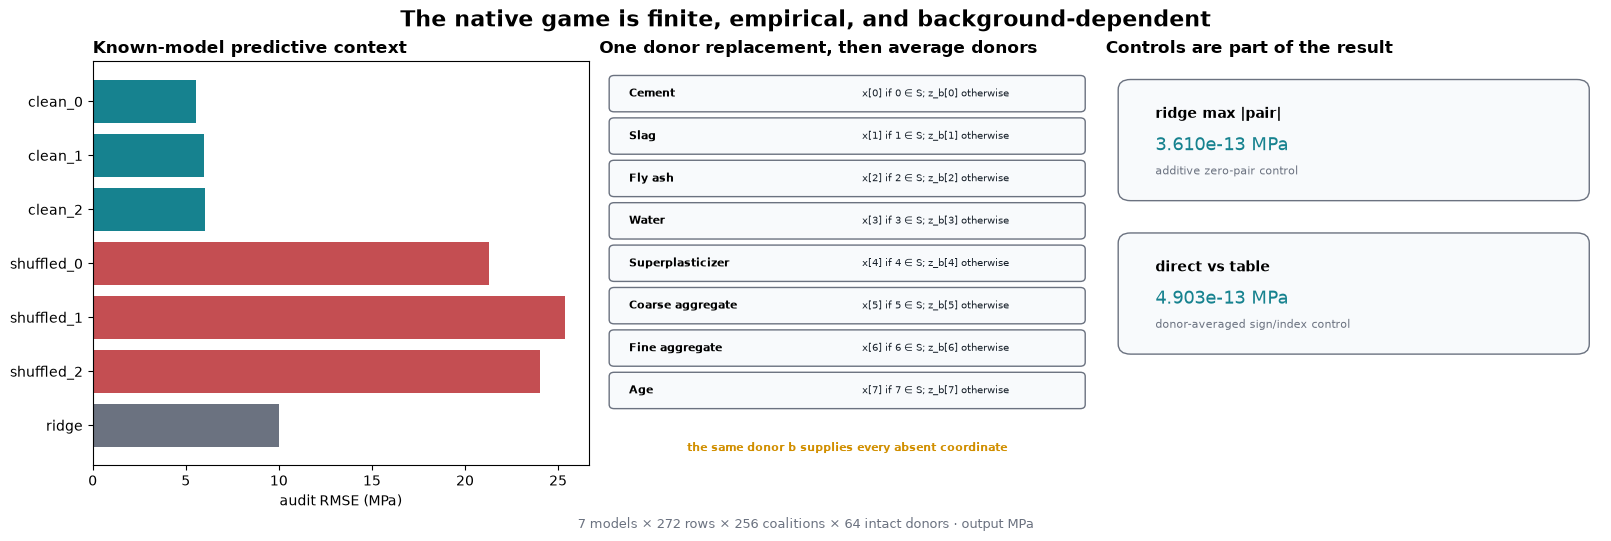

In [ ]:
allocation_figure = plot_native_game_and_controls(evaluated)

allocation_show_figure(allocation_figure, '03_native_game_and_controls')

## Reflect after the result — allocation-122

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

The clean predictors have much lower audit RMSE than their shuffled-label counterparts. The additive
ridge control has pair interactions near numerical zero, and independently rebuilt four-forward
synergies agree with table indexing. These checks establish that the model and game construction
behave as intended; they do not decide which interaction definition to prefer.

<details>
<summary>Interpretation - what does the shuffled-label control rule out?</summary>

A large pair coefficient alone is not evidence that a model learned useful structure. The shuffled
models can have large interactions while predicting strength poorly. Read predictive quality first,
then ask how each rule describes that particular fitted model.

</details>

## Forecast before running — allocation-124

Forecast signs and magnitudes at the fixed row; explain why an interaction graph is not a causal mechanism.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


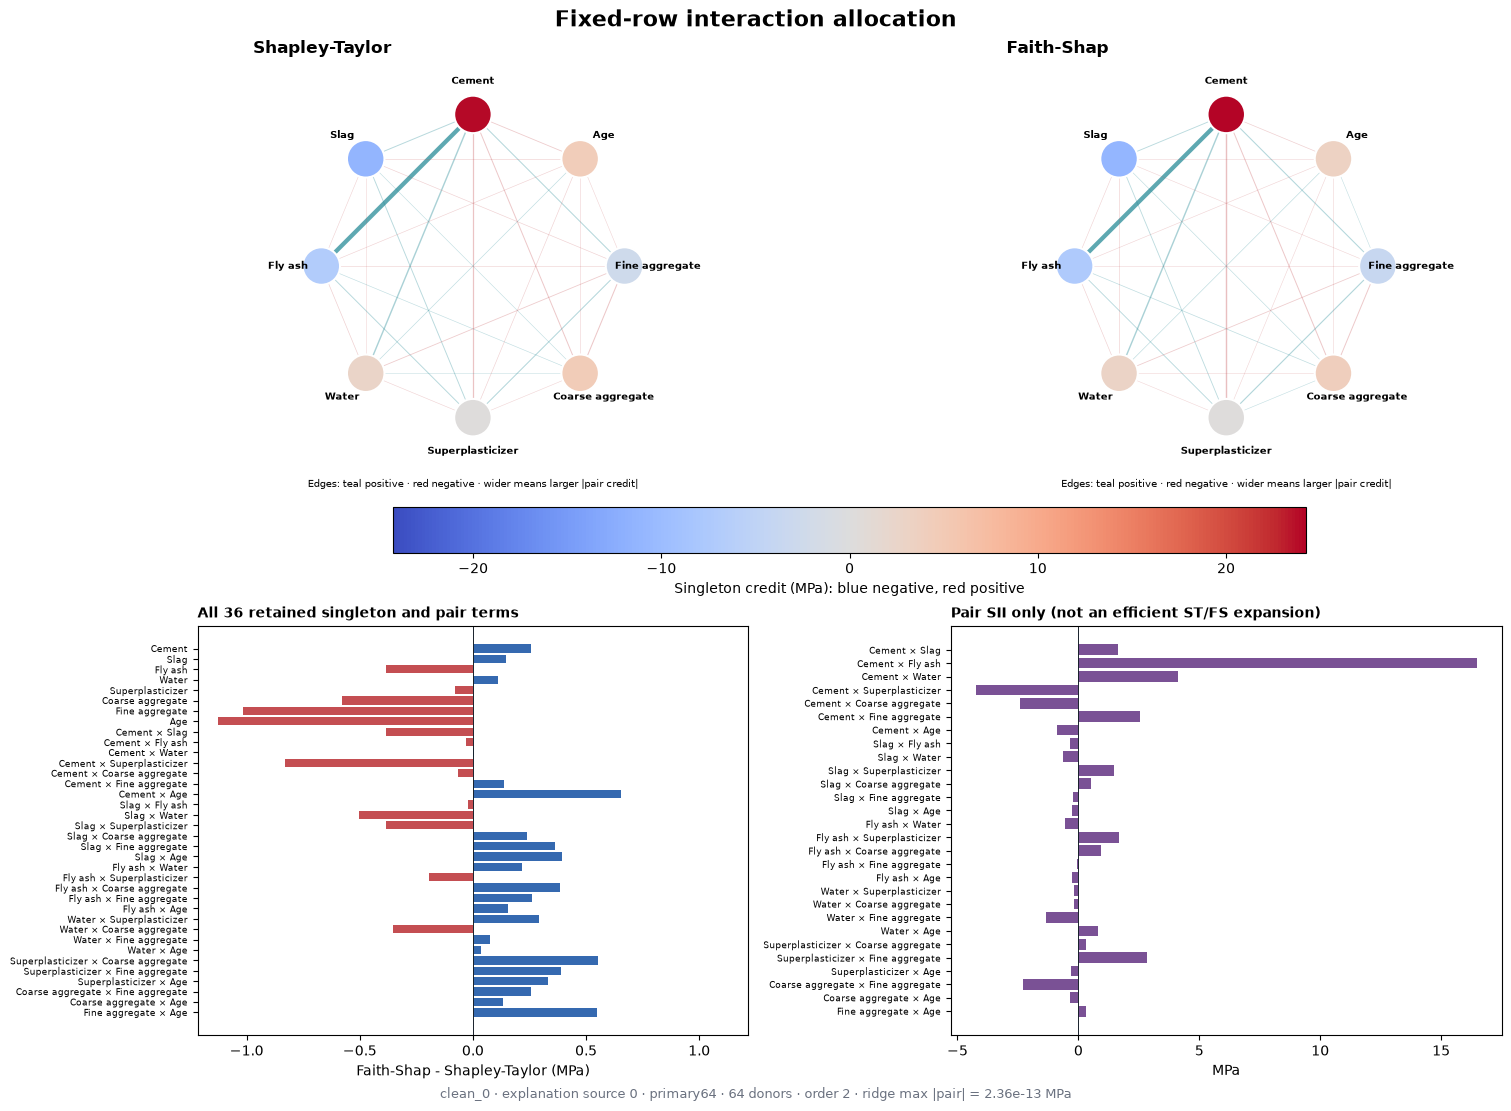

In [ ]:
allocation_figure = plot_fixed_row_interaction_graph(allocation_play, prepared['feature_names'])

allocation_show_figure(allocation_figure, '04_fixed_row_interaction_graph')

## Reflect after the result — allocation-124

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

Node color is singleton credit; edge color and width are signed and absolute pair credit. The two
methods share node positions and scales. A complete term-difference strip prevents graph thresholds
from silently hiding small or zero terms.

## Forecast before running — allocation-126

Predict variation across all rows/models without selecting a favorable row.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


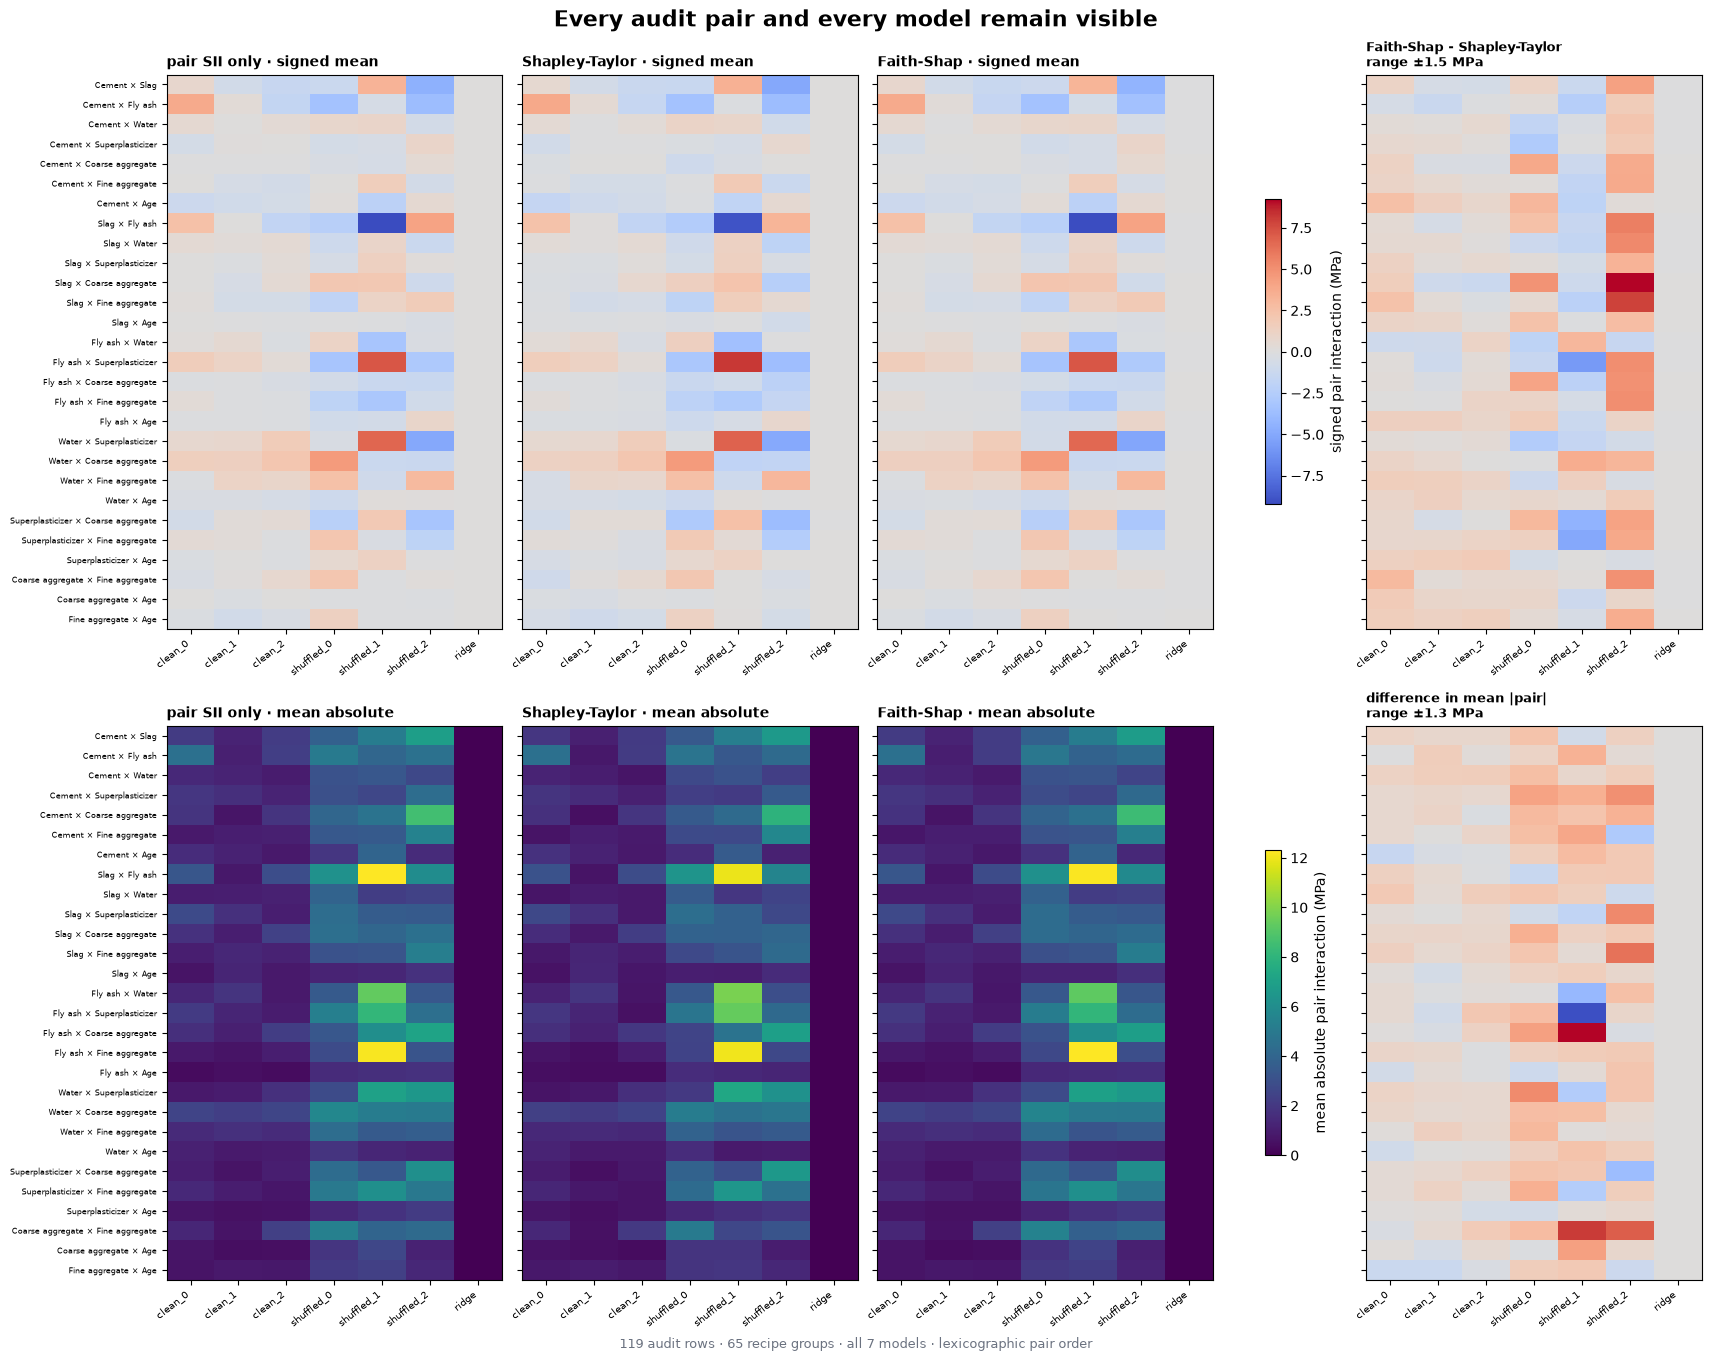

In [ ]:
allocation_figure = plot_allrow_pair_heatmaps(evaluated, prepared['feature_names'])

allocation_show_figure(allocation_figure, '05_allrow_pair_heatmaps')

## Reflect after the result — allocation-126

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

These matrices summarize all 119 audit rows by recipe group and preserve each model seed. Signed mean
and mean absolute magnitude are separate because cancellation is itself part of the interpretation.
SII is labeled `pair SII only`.

## Forecast before running — allocation-128

Predict audit-group capture relative to explanation rankings and random orders.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


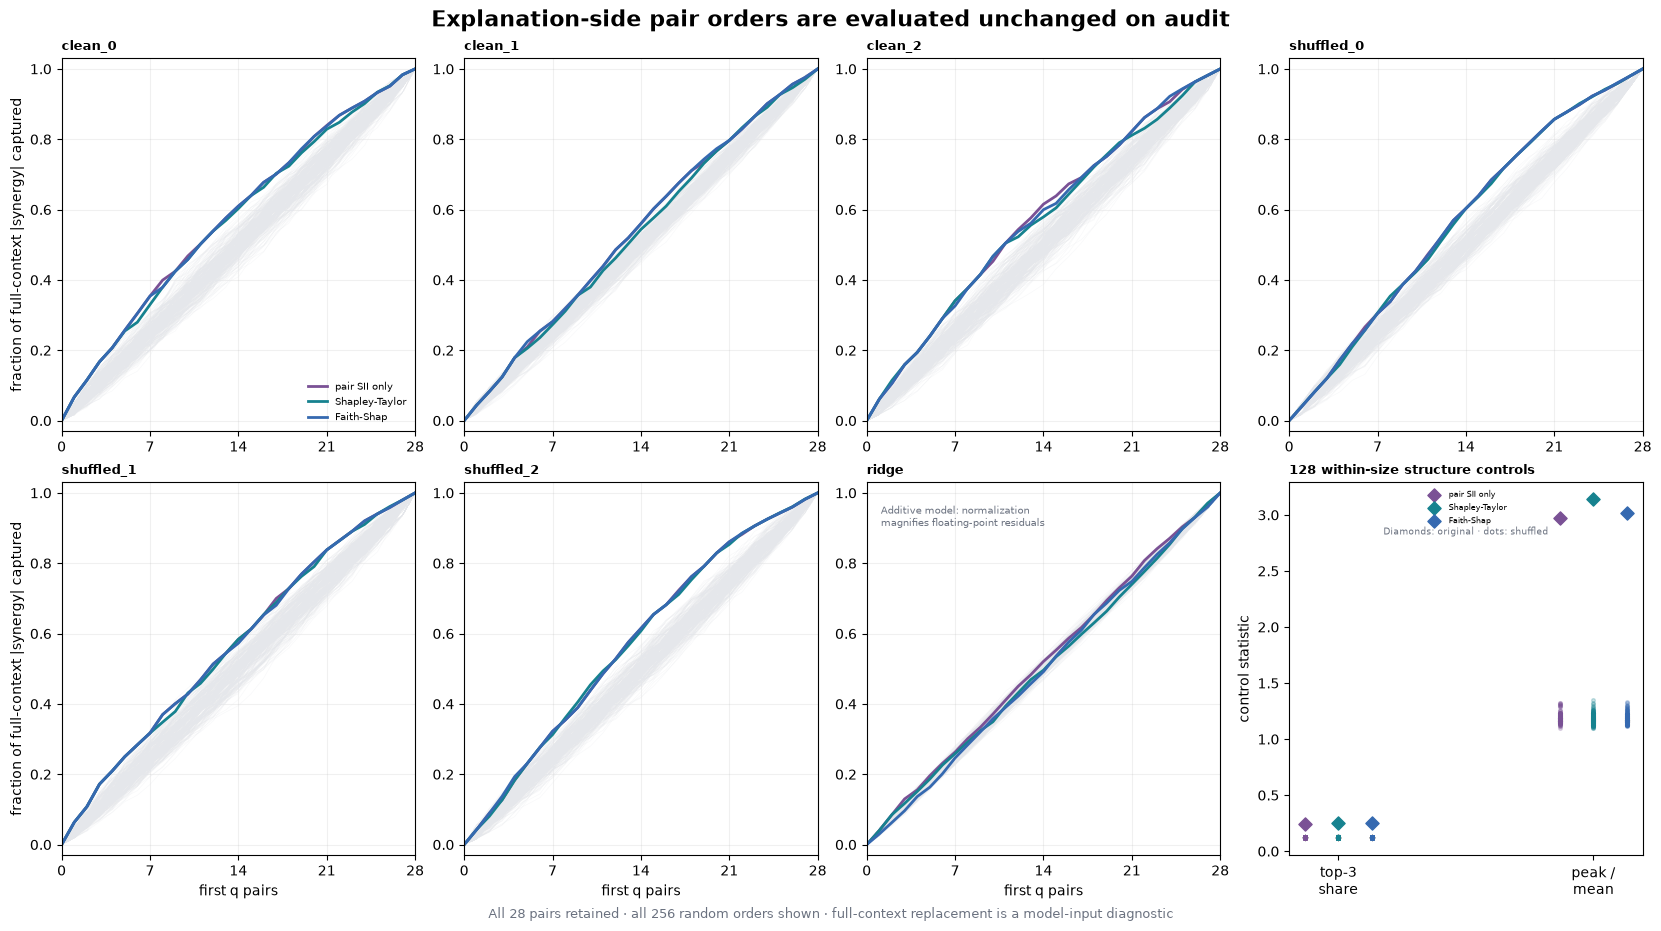

In [ ]:
allocation_figure = plot_heldout_pair_order_capture(evaluated, prepared['feature_names'])

allocation_show_figure(allocation_figure, '06_heldout_pair_order_capture')

## Reflect after the result — allocation-128

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

Each complete pair order is learned on the 153 explanation rows, then carried unchanged to the 119
audit rows. The target is mean absolute full-context synergy under the declared model-input
replacement. All 256 random-order curves remain visible; this is not a causal validation or a
significance test. The three rule-specific curves can be close even when their signed coefficients
differ: ordering 28 pairs discards magnitude and sign information. In the ridge panel, normalizing
near-zero floating-point residuals produces a nontrivial-looking curve; its absolute interaction
scale is the relevant control. Diamonds in the final panel are the original clean model's statistics;
the dots are the 128 within-size shuffled games.

<details>
<summary>Interpretation - does a curve above random identify a causal circuit?</summary>

No. It means an explanation-side ranking concentrates a held-out model-input diagnostic more quickly
than random pair orderings. The target is the full-context second difference under intact donor
replacement. It is neither a causal intervention on physical concrete nor the defining objective of
any one interaction index. Compare the curve with the signed heatmaps and reconstruction plots.

</details>

## Forecast before running — allocation-130

Contrast efficiency, weighted reconstruction and unweighted residuals.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


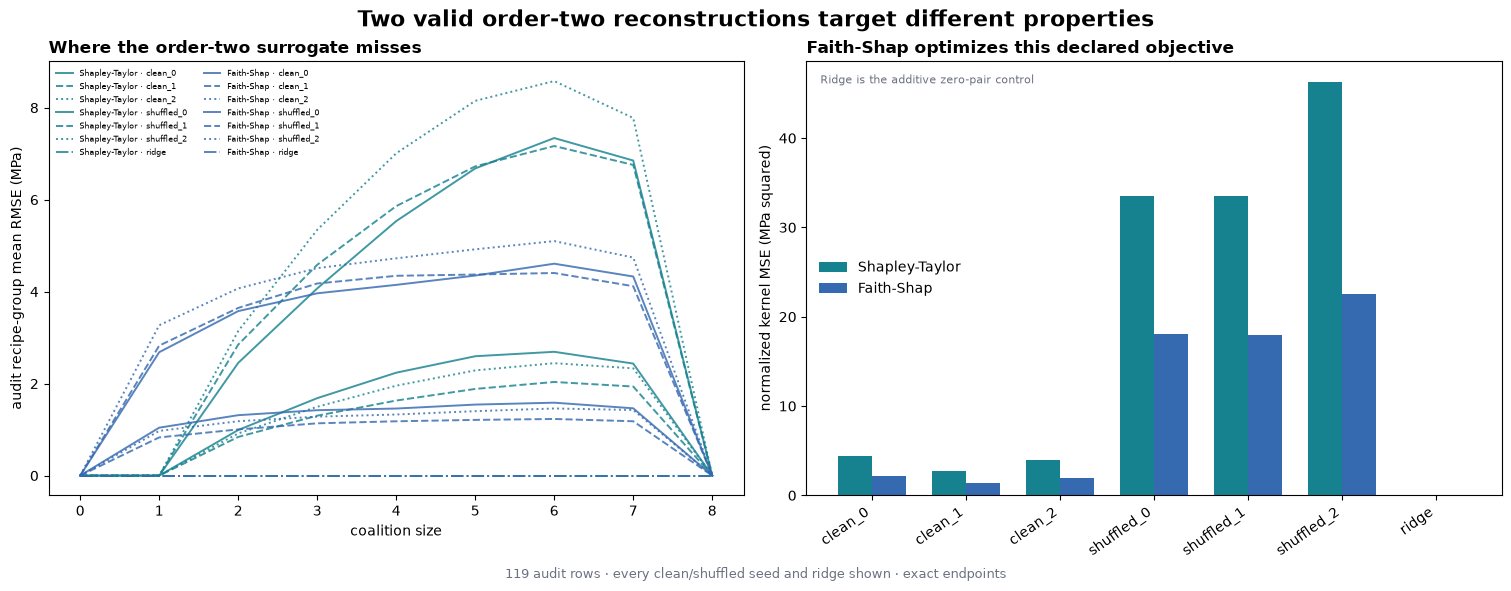

In [ ]:
allocation_figure = plot_order_two_reconstruction(evaluated)

allocation_show_figure(allocation_figure, '07_order_two_reconstruction')

## Reflect after the result — allocation-130

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

Faith-Shap may be labeled the optimum for its normalized kernel error because that is its definition.
The coalition-size residuals show where each order-two reconstruction misses. Empty and full
constraints hold to float64 solver precision, and the degree-two and ridge controls should expose implementation drift.

## Forecast before running — allocation-132

Predict background sensitivity while recognizing each donor change as an altered estimand.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


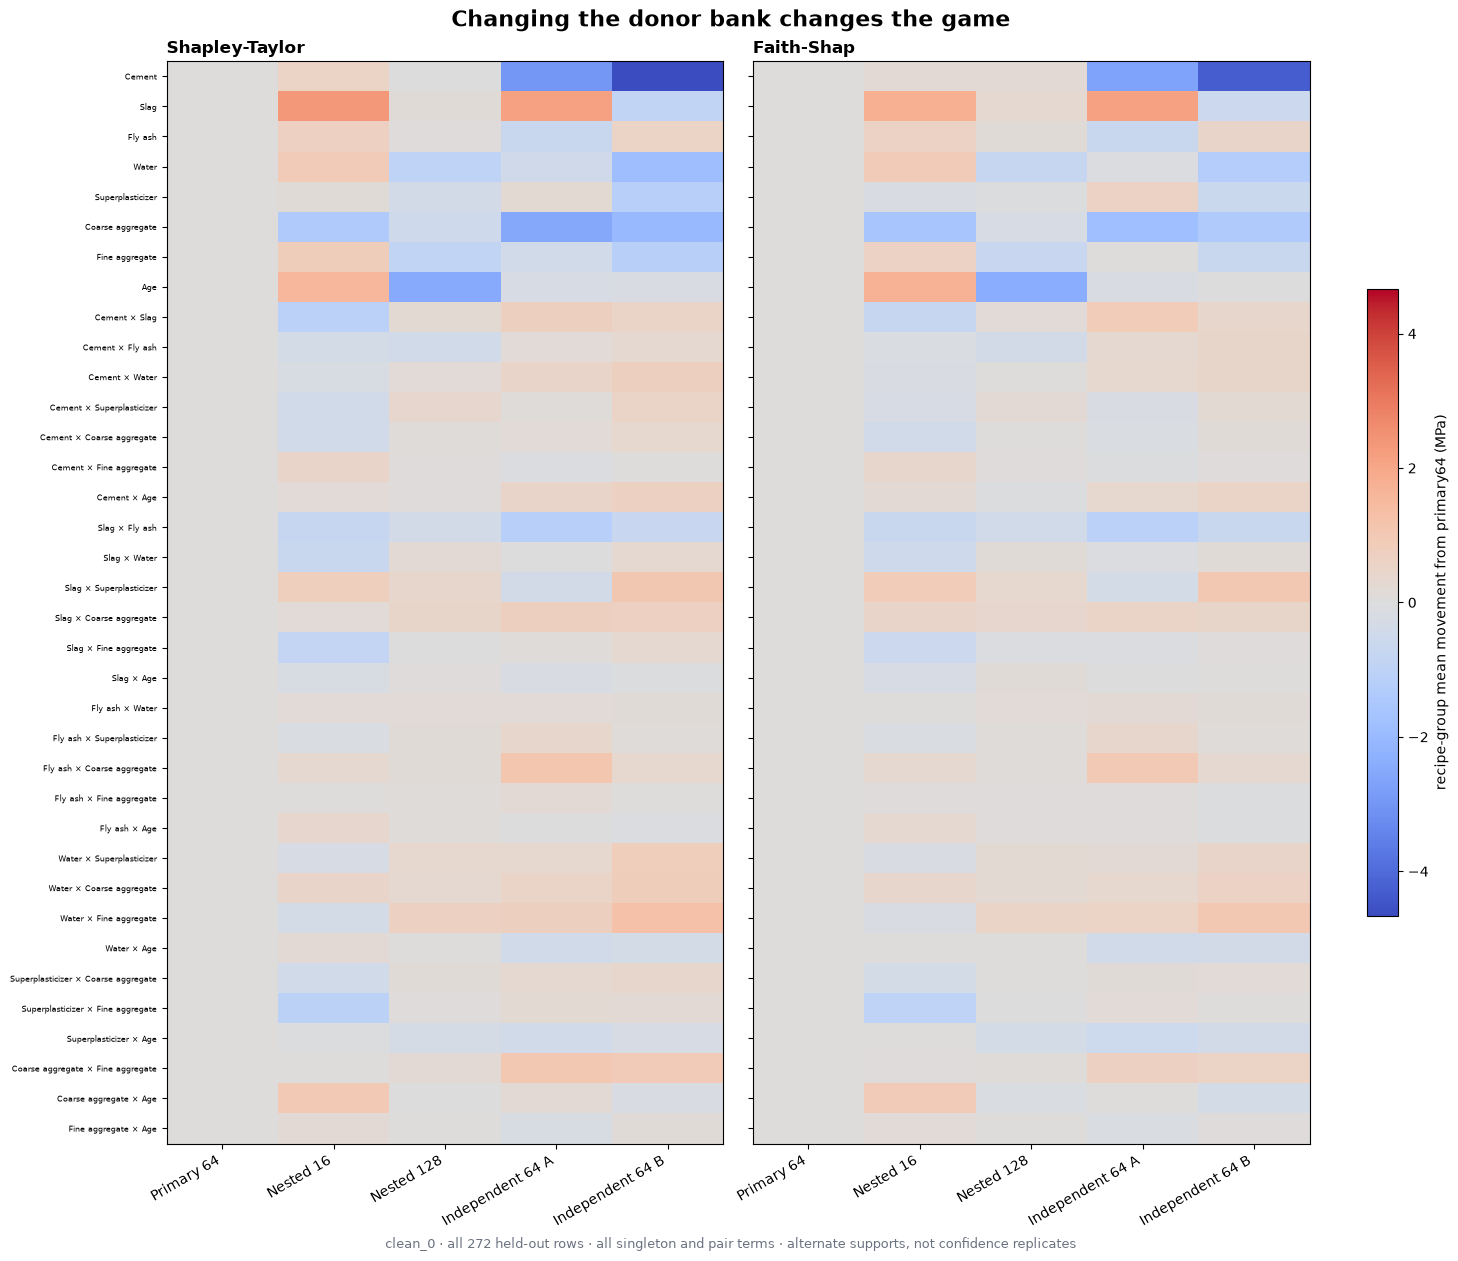

In [ ]:
allocation_figure = plot_background_changes_the_game(evaluated, prepared['feature_names'])

allocation_show_figure(allocation_figure, '08_background_changes_the_game')

## Reflect after the result — allocation-132

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

`nested16` and `nested128` are related prefixes; `independent64_a` and `independent64_b` are alternate
finite supports. Their spread is not a standard error. Moving the background changes the coalition
game before either interaction rule is applied.

## Forecast before running — allocation-134

Predict agreement and disagreement between full-context interventions and each interaction definition.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


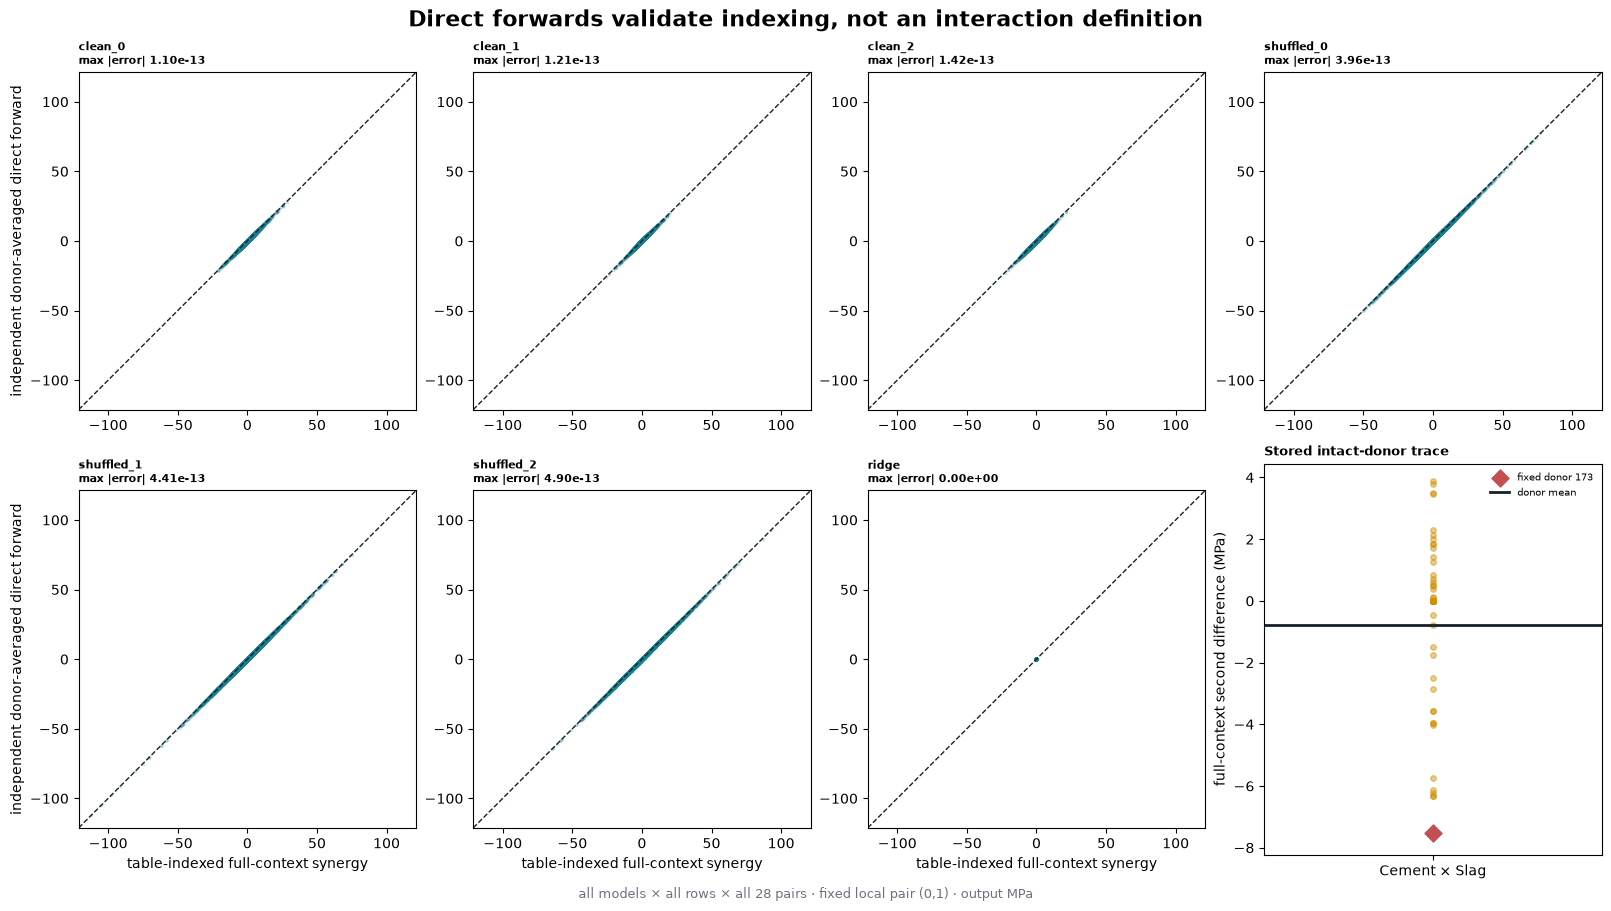

In [ ]:
allocation_figure = plot_contextual_pair_interventions(evaluated, allocation_play, prepared['feature_names'])

allocation_show_figure(allocation_figure, '09_contextual_pair_interventions')

## Reflect after the result — allocation-134

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

The direct-forward path rebuilds the four full-context inputs independently of table indexing. Its
agreement with the stored second difference checks mask order and sign. Shapley-Taylor, Faith-Shap,
and SII can still differ validly because they aggregate contexts differently.

## Try It Yourself: donor-context microscope

Edit the model, row, background, pair, context, or donor. `DONOR_SOURCE_ID=None` uses the whole
finite donor bank; choosing one donor constructs and clearly labels a different single-donor game.
Start with the predeclared explanation row. Audit rows are available only here, after every frozen
study figure has already been computed.

## Forecast before running — allocation-137

Commit donor/context/pair edits before viewing their signed consequences.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


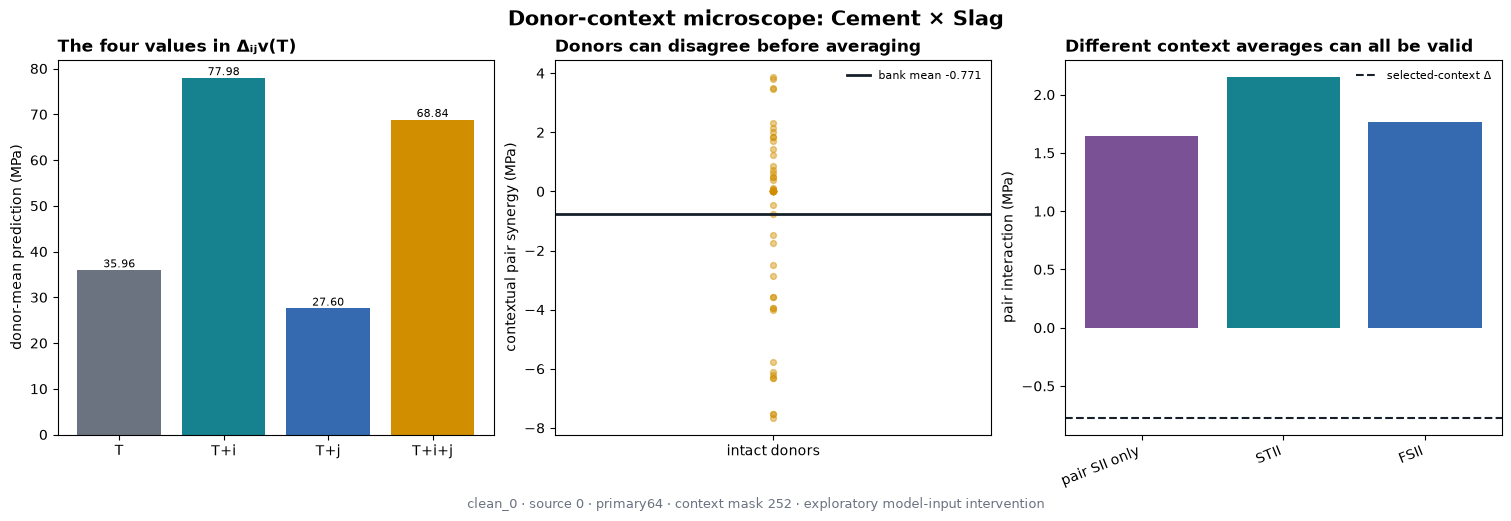

In [ ]:
allocation_MODEL_KEY = 'clean_0'

allocation_SOURCE_ID = 0

BACKGROUND_KEY = 'primary64'

PAIR = (0, 1)

CONTEXT_MASK = 252

DONOR_SOURCE_ID = None

context_play = empirical_context_play(evaluated, methods=allocation_methods, model_key=allocation_MODEL_KEY, source_id=allocation_SOURCE_ID, background_key=BACKGROUND_KEY, pair=PAIR, context_mask=CONTEXT_MASK, donor_source_id=DONOR_SOURCE_ID)

allocation_figure = plot_donor_context_play(context_play, prepared['feature_names'])

allocation_show_figure(allocation_figure, '11_donor_context_play')

## Reflect after the result — allocation-137

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Ideas to try</summary>

1. Keep the row and pair fixed, but switch between `primary64`, its nested prefixes, and the two
   independent banks. Say explicitly that you changed the game.
2. Select donor `173`, then return to `None`. Compare the donor-specific second difference with the
   bank mean and look for signed cancellation.
3. Change `CONTEXT_MASK` while keeping it disjoint from `PAIR`. Compare the local derivative with
   each method's context aggregation.
4. Select an audit source ID only after the frozen study. The output should label this as exploratory
   audit reuse rather than a selected headline example.

</details>

## Conclusion

The pure four-way game answered the opening question with two coherent order-two allocations:
Shapley-Taylor kept lower-order dividends at zero and split the omitted term across pairs; Faith-Shap
moved both singleton and pair coefficients to improve a particular constrained reconstruction. SII
asked a third question by averaging pair derivatives over contexts.

On a real fitted-model game, the same distinctions remain:

- efficiency concerns the full-minus-empty ledger, not every interior coalition;
- faithfulness is specific to a kernel, degree, and exact constraints;
- a pair coefficient can include routed higher-order credit;
- a contextual second difference is one direct model-input intervention, not the unique pair index;
- changing the donor bank changes the explanation game; and
- exact enumeration costs $2^n$, so the eight-feature study does not solve scalable interaction
  discovery.

The Concrete outputs explain specified fitted predictors on finite empirical donor-replacement games
in MPa. They do not identify physical ingredient interactions or population causal effects.

## Further reading

- Sundararajan, Dhamdhere, and Agarwal, [*The Shapley Taylor Interaction
  Index*](https://proceedings.mlr.press/v119/sundararajan20a.html).
- Tsai, Yeh, and Ravikumar, [*Faith-Shap: The Faithful Shapley Interaction
  Index*](https://www.jmlr.org/papers/v24/22-0202.html).
- Section 16.3 for the exact Shapley Interaction Index convention used as the labeled comparator.
- Sections 16.14–16.15 for the known Concrete predictors, finite backgrounds, and attribution-game
  controls reused here.

## Study conclusion — allocation

State the target interaction definition, experiment, denominator and negative controls before comparing this track with the other two. Preserve any disagreement as evidence about distinct questions.

# 3️⃣ One query, many interactions

## [16.17] One Query, Many Interactions

## Introduction

Today you'll build two algorithms that estimate feature interactions without asking a model
about every possible feature subset. Your first algorithm will turn **one model response into an
update for every pair**. Your second will fit a sequence of weighted regressions to the same
responses. You'll be able to see what each query buys you, where sampling noise enters, and when
the regression has too little information to identify an answer.

The central question is simple: **how accurately can we estimate every pair interaction when we can query only some coalitions?**

We will use exact small games to understand the algorithms, then repeat the comparison on eight-feature Concrete-strength predictors. Eight features are small enough to enumerate all 256 coalitions for a reference. The sampled estimators will receive only their requested values. Keeping the exact answer outside the estimator lets us measure an error that would normally be unknown.

This lesson continues 16.3's Shapley Interaction Index (SII). Both algorithms target the **same SII**. Shapley-Taylor and Faith-Shap from 16.16 choose different allocations; disagreement between those definitions is a different issue from the estimation error studied here.

## Original study objectives

### 1️⃣ Share one query across many interactions

You'll rewrite the four-term pair derivative as a weighted sum over a common set of coalitions. This is the step that lets SHAP-IQ reuse each model evaluation for all pairs.

> ##### Original study objectives
>
> - Distinguish a coalition, a context and an interaction set.
> - Derive the sign and magnitude of a shared-query update.
> - See why one apparently large update can cancel in the complete answer.

### 2️⃣ Sample a game, measure the uncertainty

You'll implement a size-then-subset sampler and the SHAP-IQ mean and standard error. The same random draw can occur more than once: it costs one cached model query but still contributes multiple times to the Monte Carlo average.

> ##### Original study objectives
>
> - Separate a size probability from a per-coalition probability.
> - Implement importance weighting and an iid standard error.
> - Count draw requests and unique queries correctly.

### 3️⃣ Fit the pairwise KernelSHAP-IQ limit

You'll solve a constrained least-squares problem, then use it to fit main effects and pair residuals. The interesting part is the boundary: infinite weight does not mean every boundary residual can be made zero.

> ##### Original study objectives
>
> - Separate the feasible particular solution from free directions.
> - Derive the pair design and boundary least-squares constraint.
> - Detect rank deficiency rather than silently regularizing it away.

### 4️⃣ Read the real-model comparison

You'll apply both estimators to every held-out recipe for seven known predictors, compare against exact SII, and inspect two editable experiments.

> ##### Original study objectives
>
> - Read signed errors alongside query-budget curves and model controls.
> - Compare estimated SE with the exact sampling variance of a finite game.
> - Explain the limits of a precomputed-oracle query benchmark.

The eight exercises should take about 90–120 minutes, followed by 30–45 minutes for the model comparison and plays. If the nullspace derivation is unfamiliar, work through its three-coefficient example and use the solution to continue; return to the proof once the end-to-end result is clear.

## Setup

All methods use CPU float64. An integer mask contains feature `i` exactly when bit `i` is set. Pair columns follow lexicographic feature order: `(0,1), (0,2), ...`. We supply input validation, indexing helpers and plotting. The sampling and estimation algorithms will be your own functions.

In [ ]:
from __future__ import annotations

import itertools as estimator_itertools

import math as estimator_math

import os as estimator_os

import sys as estimator_sys

from collections.abc import Callable

from pathlib import Path as estimator_Path

from types import SimpleNamespace as estimator_SimpleNamespace

from typing import Any as estimator_Any

import numpy as estimator_np

import pandas as estimator_pd

import matplotlib.pyplot as estimator_plt

import torch as estimator_t

from torch import Tensor as estimator_Tensor

from IPython.display import display as estimator_display

estimator_chapter = 'chapter16_shapley_attribution_baselines'

estimator_root_dir = next((p for p in [estimator_Path.cwd(), *estimator_Path.cwd().parents] if (p / estimator_chapter).exists()))

if str(estimator_root_dir) not in estimator_sys.path:
    estimator_sys.path.insert(0, str(estimator_root_dir))

from chapter16_shapley_attribution_baselines.exercises.part17_shapiq_estimators import estimator_methods_tests as estimator_tests, estimator_study as study, estimator_plots as plots

from chapter16_shapley_attribution_baselines.exercises.part17_shapiq_estimators.estimator_methods import _players, _masks, _values, _queried_inputs, interaction_masks, boundary_masks

estimator_t.set_num_threads(4)

OUTPUT_DIR = estimator_Path(estimator_os.environ.get('ARENA_ESTIMATOR_OUTPUT_DIRECTORY', './estimator_outputs'))

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def estimator_show_figure(figure, name):
    figure.savefig(OUTPUT_DIR / f'{name}.png', dpi=130, bbox_inches='tight')
    estimator_display(figure)
    estimator_plt.close(figure)

## Cold open: one coalition says something about six pairs

Return to the controlled score from 16.3. Two weak individual features have a strong joint effect, and a triple contributes additional pairwise credit:

$$v(x)=0.2x_0+0.2x_1+5x_2+4x_3+3x_0x_1+2x_0x_1x_2.$$

Suppose you query only coalition `{0,1}`. Its value is `3.4`. Can that single response tell you the interaction of the entirely absent pair `{2,3}`?

<details>
<summary>Predict before continuing</summary>

It cannot identify that pair by itself. It can contribute one signed term to an estimator of that pair. Other queries must cancel contributions due to unrelated features. The complete SII of `{2,3}` is zero, even though this query contributes positively to its shared-query sum.

</details>

## Forecast before running — estimator-3

Predict how one coalition can update multiple pair estimates with different signs.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
game_rows = []

for mask in range(16):
    a, b, c, d = [float(bool(mask & 1 << i)) for i in range(4)]
    estimator_value = 0.2 * a + 0.2 * b + 5 * c + 4 * d + 3 * a * b + 2 * a * b * c
    game_rows.append({'mask': f'{mask:04b}', 'A': a, 'B': b, 'C': c, 'D': d, 'value': estimator_value})

estimator_display(estimator_pd.DataFrame(game_rows).set_index('mask'))

print('Query {A,B}:', game_rows[3]['value'])

## Reflect after the result — estimator-3

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

## 1️⃣ Share one query across many interactions

## Turn masks into model inputs

Our algorithms use a matrix $Z$ with one queried coalition per row and one feature per column. Its entries are zero or one. For four features, mask `6` is binary `0110`, so its row is `[0,1,1,0]`. The printed binary string puts the most significant bit first; the feature columns put feature zero first. Keep these conventions distinct.

### Exercise - implement `coalition_design`

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

Use a vector of feature bits and a broadcast bitwise AND. Preserve repeated input masks and their order.

## Forecast before running — estimator-5

Forecast each coalition-design row and feature-axis shape.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def coalition_design(masks: estimator_Tensor, *, n_players: int) -> estimator_Tensor:
    """Return X[queried coalition, feature] in float64."""
    raise NotImplementedError()


estimator_tests.test_coalition_design(fn=coalition_design)

<details><summary>Solution</summary>

```python
def coalition_design(masks: estimator_Tensor, *, n_players: int) -> estimator_Tensor:
    """Return X[queried coalition, feature] in float64."""
    n = _players(n_players)
    _masks(masks, n)
    bits = 1 << estimator_t.arange(n, dtype=estimator_t.int64)
    return masks[:, None].bitwise_and(bits).ne(0).to(estimator_t.float64)

estimator_tests.test_coalition_design(fn=coalition_design)
```
</details>

## Reflect after the result — estimator-5

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

`[0,1,6,15]` maps to the empty row, feature zero, features one and two, and the full row. The focused test prints `All tests in test_coalition_design passed!`.

</details>

<details>
<summary>Help - which axis should be broadcast?</summary>

Compare `masks[:, None]` with `1 << torch.arange(n_players)`. Convert the nonzero result to float64 after the bitwise operation.

</details>

## Rearrange the pair derivative

For a fixed pair $S=\{i,j\}$ and a disjoint context $C$, the second difference is

$$\Delta_S v(C)=v(C\cup S)-v(C\cup\{i\})-v(C\cup\{j\})+v(C).$$

SII averages this derivative with weight

$$m_s(c)=\frac{1}{(n-s+1)\binom{n-s}{c}}.$$

For pairs, $s=2$. Equivalently, the size of the context is uniform over `0..n-2`, then the context is uniform within that size. The direct definition asks about different contexts for each pair. To share queries, expand every derivative and collect the coefficient of the **same queried coalition** $T$.

If $k=\lvert T\cap S\rvert$, the context behind this occurrence must be $C=T\setminus S$. The derivative contributes sign $(-1)^{s-k}$ and context size $\lvert T\rvert-k$. Therefore

$$I^{\mathrm{SII}}(S)=\sum_{T\subseteq N}v_0(T)\,\gamma_s(T,S),\qquad
\gamma_s(T,S)=\frac{(-1)^{s-\lvert T\cap S\rvert}}{(n-s+1)\binom{n-s}{\lvert T\rvert-\lvert T\cap S\rvert}},$$

where $v_0(T)=v(T)-v(\varnothing)$. This is SHAP-IQ's shared-evaluation representation. The model query is independent of the pair; only its weight changes.

### Exercise - implement `sii_query_weights`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15 minutes on this exercise.
> ```

Return one gamma row for each query and one column for each interaction of the requested order. The supplied `interaction_masks` enumerates the interaction columns, not the power set of model queries. Compute overlap sizes using the two binary designs; use the formula above for sign and denominator.

## Forecast before running — estimator-8

Predict the shared SII query weights of present and absent pairs.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def sii_query_weights(masks: estimator_Tensor, *, n_players: int, order: int=2) -> estimator_Tensor:
    """The SHAP-IQ gamma coefficient of each queried value in every order-s SII.

    If k=|T intersection S|, gamma(T,S)=(-1)**(s-k) /
    ((n-s+1) * choose(n-s, |T|-k)). No model evaluations occur here.
    """
    raise NotImplementedError()


estimator_tests.test_sii_query_weights(fn=sii_query_weights)

<details><summary>Solution</summary>

```python
def sii_query_weights(masks: estimator_Tensor, *, n_players: int, order: int=2) -> estimator_Tensor:
    """The SHAP-IQ gamma coefficient of each queried value in every order-s SII.

    If k=|T intersection S|, gamma(T,S)=(-1)**(s-k) /
    ((n-s+1) * choose(n-s, |T|-k)). No model evaluations occur here.
    """
    n = _players(n_players)
    terms = interaction_masks(n, order)
    design = coalition_design(masks, n_players=n)
    term_design = coalition_design(terms, n_players=n)
    overlap = (design @ term_design.T).to(estimator_t.int64)
    outside = design.sum(-1).to(estimator_t.int64)[:, None] - overlap
    denominator = estimator_t.tensor([(n - order + 1) * estimator_math.comb(n - order, r) for r in range(n - order + 1)], dtype=estimator_t.float64)
    sign = estimator_t.where((order - overlap) % 2 == 0, 1.0, -1.0).to(estimator_t.float64)
    return sign / denominator[outside]

estimator_tests.test_sii_query_weights(fn=sii_query_weights)
```
</details>

## Reflect after the result — estimator-8

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

For `n_players=4`, query `{0,1}` and pair order, the gamma row is

`[1/3, -1/6, -1/6, -1/6, -1/6, 1/3]`.

For example, pair `{0,2}` overlaps once, so its sign is negative and its context contains one of the other two players. The complete additive game returns zero in every pair column.

</details>

<details>
<summary>Help - avoid one Python loop per query and pair</summary>

If `Z` contains query designs and `A` contains interaction designs, `Z @ A.T` gives every overlap size. Subtract from each query's population count. Precompute the short denominator vector for context sizes `0..n-order` and index it with that result.

</details>

## Forecast before running — estimator-10

Forecast all six signed updates for a fixed query before viewing the shared-query display.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


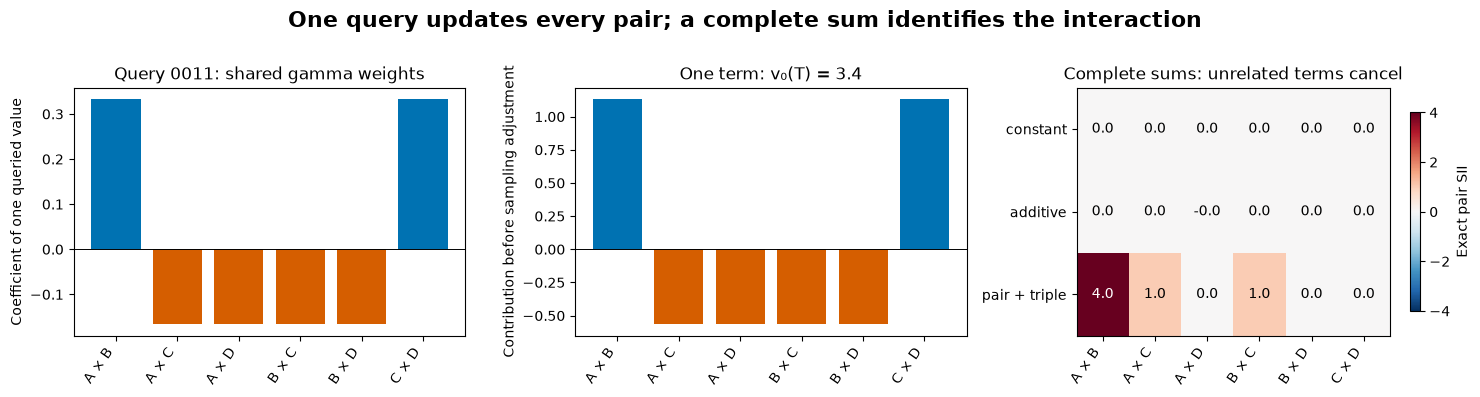

In [ ]:
estimator_games = plots.analytic_games(coalition_design)

estimator_figure = plots.plot_shared_query(estimator_games, sii_query_weights, query_mask=3)

estimator_show_figure(estimator_figure, '01_shared_query')

## Reflect after the result — estimator-10

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Interpretation - why does the absent pair receive a positive update?</summary>

The update is a term in an algebraic sum, not a claim that the absent pair caused the response. The plot shows the complete additive control canceling after all coalitions are included. At finite sampling budgets the cancellation is imperfect. A large contribution from one query should never be read as a recovered interaction by itself.

</details>

## Try It Yourself: follow one query

Change the coalition mask below. Predict which pair columns become negative before running it. Then remove the interaction terms while retaining the additive weights.

## Forecast before running — estimator-12

Commit a query mask and game, then predict which pair estimates change sign.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


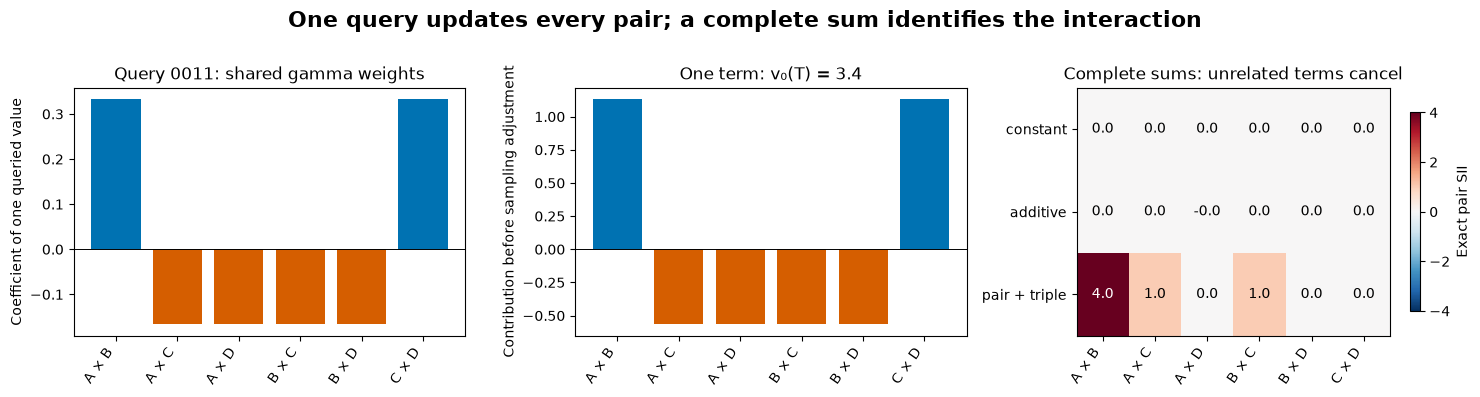

In [ ]:
QUERY_MASK = 3

GAME_NAME = 'mixed'

estimator_figure = plots.plot_shared_query(estimator_games, sii_query_weights, query_mask=QUERY_MASK, game_name=GAME_NAME)

estimator_show_figure(estimator_figure, '02_query_play')

## Reflect after the result — estimator-12

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

## 2️⃣ Sample a game, measure the uncertainty

## Query the boundary exactly

We will query the empty and full sets, every singleton and every singleton complement. For eight features, these are 18 unique coalitions. Sample the remaining 238 coalitions with replacement.

This is a fixed teaching design, not an outcome-driven choice of strata. The exact boundary is useful for both estimators and lets them share the same requested values. A query cache will eliminate duplicate model calls while preserving duplicate samples in the averages.

## A size is not a coalition

Let $p_k$ be the probability of drawing size $k$. After choosing a uniformly random set of that size, its probability is

$$p(T)=\frac{p_{\lvert T\rvert}}{\binom{n}{\lvert T\rvert}}.$$

The kernel proposal uses a per-coalition weight proportional to $1/\binom{n-2}{k-1}$. Multiplying by the number of coalitions of that size gives size mass proportional to $1/[k(n-k)]$. Uniform sampling over *coalitions* instead gives size mass proportional to $\binom{n}{k}$. Both distributions are restricted to sizes `2..n-2` here.

### Exercise - implement `sample_coalitions`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 12 minutes on this exercise.
> ```

Create a local seeded generator. Draw a size from the appropriate distribution, generate a uniform random feature permutation, and retain its first `size` elements. Return the mask and its **per-coalition probability** for every draw. Do not enumerate all `2**n_players` masks.

## Forecast before running — estimator-14

Predict per-set probabilities versus cardinality probabilities without enumerating the power set.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def sample_coalitions(*, n_players: int, draws: int, seed: int, proposal: str='kernel') -> tuple[estimator_Tensor, estimator_Tensor]:
    """Draw iid interior coalitions, retaining duplicate draws and per-set p(T).

    Draw size first, then a uniformly random subset of that size. Kernel means
    p(T) proportional to 1/choose(n-2, |T|-1), restricted to 2..n-2.
    Uniform means uniform over individual sets in that same support.
    """
    raise NotImplementedError()


estimator_tests.test_sample_coalitions(fn=sample_coalitions)

<details><summary>Solution</summary>

```python
def sample_coalitions(*, n_players: int, draws: int, seed: int, proposal: str='kernel') -> tuple[estimator_Tensor, estimator_Tensor]:
    """Draw iid interior coalitions, retaining duplicate draws and per-set p(T).

    Draw size first, then a uniformly random subset of that size. Kernel means
    p(T) proportional to 1/choose(n-2, |T|-1), restricted to 2..n-2.
    Uniform means uniform over individual sets in that same support.
    """
    n = _players(n_players)
    if type(draws) is not int or draws < 2 or type(seed) is not int or (seed < 0):
        raise ValueError('draws >= 2 and a nonnegative integer seed are required.')
    if proposal not in ('kernel', 'uniform'):
        raise ValueError("proposal must be 'kernel' or 'uniform'.")
    sizes = estimator_t.arange(2, n - 1, dtype=estimator_t.int64)
    if proposal == 'kernel':
        size_mass = 1.0 / (sizes.to(estimator_t.float64) * (n - sizes))
    else:
        size_mass = estimator_t.tensor([estimator_math.comb(n, int(k)) for k in sizes], dtype=estimator_t.float64)
    size_probability = size_mass / size_mass.sum()
    generator = estimator_t.Generator(device='cpu').manual_seed(seed)
    chosen = estimator_t.multinomial(size_probability, draws, replacement=True, generator=generator)
    selected_sizes = sizes[chosen]
    permutations = estimator_t.rand((draws, n), generator=generator, dtype=estimator_t.float64).argsort(dim=-1)
    take = estimator_t.arange(n)[None, :] < selected_sizes[:, None]
    masks = ((1 << permutations) * take).sum(-1)
    combinations = estimator_t.tensor([estimator_math.comb(n, int(k)) for k in sizes], dtype=estimator_t.float64)
    probabilities = (size_probability / combinations)[chosen]
    return (masks, probabilities)

estimator_tests.test_sample_coalitions(fn=sample_coalitions)
```
</details>

## Reflect after the result — estimator-14

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

Repeated calls with the same seed return the same masks and probabilities; the global Torch RNG is unchanged. For eight features, each uniform interior coalition has probability `1/238`. Kernel sampling gives equal probabilities to sets of the same size, with larger per-set mass near the support boundaries.

</details>

<details>
<summary>Help - make a random subset without a power-set table</summary>

Draw a `[draws, n_players]` matrix of independent continuous random scores and argsort each row. Its first `k` feature indices form a uniform size-`k` subset. Sum their bit values to make the integer mask. Divide the selected size probability by `math.comb(n_players, k)`.

</details>

## Forecast before running — estimator-16

Forecast draws, duplicates, nominal requests and unique queries separately.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


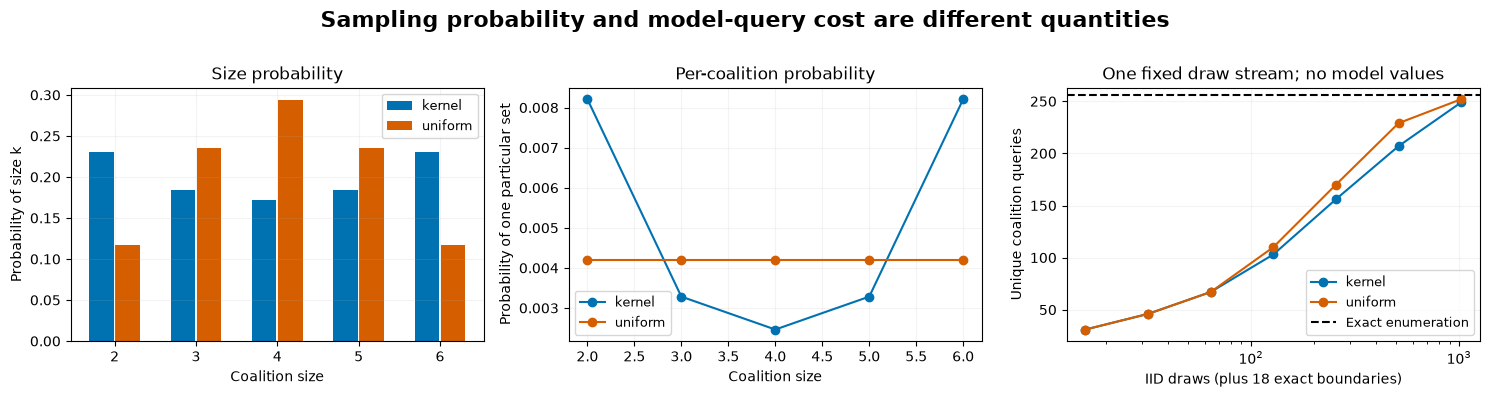

In [ ]:
estimator_figure = plots.plot_sampling(sample_coalitions)

estimator_show_figure(estimator_figure, '03_sampling_and_cost')

## Reflect after the result — estimator-16

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

## SHAP-IQ is an importance-weighted mean

Let $B$ be the exact boundary. Its contribution is

$$c_B(S)=\sum_{T\in B}v_0(T)\gamma_s(T,S).$$

For an interior draw $T_r\sim p$, define $Y_r(S)=v_0(T_r)\gamma_s(T_r,S)/p(T_r)$. Then

$$\widehat I(S)=c_B(S)+\frac1K\sum_{r=1}^{K}Y_r(S),\qquad
\widehat{\mathrm{SE}}(S)=\sqrt{\frac{1}{K(K-1)}\sum_{r=1}^{K}\big(Y_r(S)-\overline Y(S)\big)^2}.$$

The mean is unbiased for the fixed finite game under iid sampling. The SE estimates sampling variability conditional on that game. It says nothing about uncertainty in the training data, fitted model or choice of donor background. A normal error band can still have poor coverage at a small budget.

### Exercise - implement `shapiq_estimate`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 12 minutes on this exercise.
> ```

The first boundary value is the empty coalition. Center both boundary and sampled values by it. Compute the exact boundary sum and the mean of the weighted sampled contributions. Return the estimate and the sample standard error. Support arbitrary leading game axes.

## Forecast before running — estimator-18

Predict importance weighting and finite-sample SE, including a noisy additive control.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def shapiq_estimate(boundary_values: estimator_Tensor, sampled_values: estimator_Tensor, sampled_masks: estimator_Tensor, probabilities: estimator_Tensor, *, n_players: int, order: int=2) -> tuple[estimator_Tensor, estimator_Tensor]:
    """Return the SHAP-IQ point estimate and iid sample standard error.

    The first boundary is empty. Subtract its value from every queried value:
    this preserves offset invariance for each realized sample, not just in mean.
    SE concerns iid draws from a fixed game, not uncertainty about the model/data.
    """
    raise NotImplementedError()


estimator_tests.test_shapiq_estimate(fn=shapiq_estimate)

<details><summary>Solution</summary>

```python
def shapiq_estimate(boundary_values: estimator_Tensor, sampled_values: estimator_Tensor, sampled_masks: estimator_Tensor, probabilities: estimator_Tensor, *, n_players: int, order: int=2) -> tuple[estimator_Tensor, estimator_Tensor]:
    """Return the SHAP-IQ point estimate and iid sample standard error.

    The first boundary is empty. Subtract its value from every queried value:
    this preserves offset invariance for each realized sample, not just in mean.
    SE concerns iid draws from a fixed game, not uncertainty about the model/data.
    """
    n = _players(n_players)
    edges = _queried_inputs(boundary_values, sampled_values, sampled_masks, probabilities, n)
    baseline = boundary_values[..., :1]
    exact = (boundary_values - baseline) @ sii_query_weights(edges, n_players=n, order=order)
    weights = sii_query_weights(sampled_masks, n_players=n, order=order) / probabilities[:, None]
    contributions = (sampled_values - baseline)[..., :, None] * weights
    estimate = exact + contributions.mean(dim=-2)
    standard_error = (contributions.var(dim=-2, correction=1) / len(sampled_masks)).sqrt()
    return (estimate, standard_error)

estimator_tests.test_shapiq_estimate(fn=shapiq_estimate)
```
</details>

## Reflect after the result — estimator-18

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

Summing a complete uniformly enumerated interior recovers exact SII. A repeated sample retains its multiplicity. Adding a constant to every game value changes neither the estimate nor its SE. An additive game's finite-sample pair estimate can be nonzero, while a constant game is exactly zero after centering.

</details>

<details>
<summary>Help - which variance correction do I need?</summary>

Use sample variance with denominator `K-1`, then divide by `K` before taking the square root. The exact boundary contributes no sampling variance. Do not deduplicate the array of contributions and do not divide by the number of unique queried coalitions.

</details>

## Count what you actually asked the model

### Exercise - implement `query_sampled_game`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Concatenate boundary and sampled masks, query each unique mask once, then use an inverse index to reconstruct the original requested order. Return the boundary values, repeated sampled values, observed masks and counts. The callable may return several games at once, with the queried mask on its last axis.

## Forecast before running — estimator-21

Predict the oracle receipt when draws repeat, and distinguish queried masks from Monte Carlo multiplicity.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def query_sampled_game(game: Callable[[estimator_Tensor], estimator_Tensor], sampled_masks: estimator_Tensor, *, n_players: int) -> dict[str, estimator_Any]:
    """Query each required coalition once while preserving iid duplicate draws."""
    raise NotImplementedError()


estimator_tests.test_query_sampled_game(fn=query_sampled_game)

<details><summary>Solution</summary>

```python
def query_sampled_game(game: Callable[[estimator_Tensor], estimator_Tensor], sampled_masks: estimator_Tensor, *, n_players: int) -> dict[str, estimator_Any]:
    """Query each required coalition once while preserving iid duplicate draws."""
    n = _players(n_players)
    _masks(sampled_masks, n)
    edges = boundary_masks(n)
    requested = estimator_t.cat((edges, sampled_masks))
    unique, inverse = estimator_t.unique(requested, sorted=True, return_inverse=True)
    observed = game(unique)
    _values(observed, len(unique), 'game output')
    restored = observed[..., inverse]
    return {'boundary_values': restored[..., :len(edges)], 'sampled_values': restored[..., len(edges):], 'queried_masks': unique, 'queried_values': observed, 'draw_requests': len(sampled_masks), 'boundary_queries': len(edges), 'total_requests': len(requested), 'unique_queries': len(unique)}

estimator_tests.test_query_sampled_game(fn=query_sampled_game)
```
</details>

## Reflect after the result — estimator-21

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

For four players, sampled masks `[3,3,5,12]` make four draw requests plus ten exact-boundary requests, but only thirteen unique queries. The two occurrences of `3` reappear twice in `sampled_values`.

</details>

<details>
<summary>Help - one call can serve repeated requests</summary>

`torch.unique(requested, sorted=True, return_inverse=True)` gives both the query set and the restoration index. Evaluate the callable on the unique set, then index its final axis with the inverse. The model sees only this subset.

</details>

## 3️⃣ Fit the pairwise KernelSHAP-IQ limit

## A constrained least-squares building block

We want to minimize $\lVert W^{1/2}(X\beta-y)\rVert^2$ subject to $C\beta=d$. Find one feasible vector $\beta_0=C^+d$, and let the columns of $Z$ form an orthonormal basis for the nullspace of $C$. Every feasible answer is

$$\beta=\beta_0+Zu.$$

Now solve an ordinary weighted least-squares problem in $u$:

$$\min_u\left\lVert W^{1/2}XZ u-W^{1/2}(y-X\beta_0)\right\rVert^2.$$

For a small example, fit `[1,2,3]` with an identity design subject to the three coefficients summing to zero. The closest feasible answer is `[-1,0,1]`: subtract the mean. The nullspace implementation performs the corresponding projection for a general design.

### Exercise - implement `constrained_wls`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 20 minutes on this exercise.
> ```

Use SVD to identify the constraint rank and nullspace. Check that the particular solution actually satisfies the targets. Solve in the free coordinates with an SVD pseudoinverse and report the free rank, singular values, equality residuals and whether all free directions are identified.

Compare small singular values with `rtol` times the spectral norm of the **original weighted design**. A theoretically zero `X @ Z` can contain roundoff; normalizing only by that nearly zero matrix would mistake roundoff for usable information.

## Forecast before running — estimator-24

Predict the constrained optimum and remaining nullspace rank without adding regularization.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def constrained_wls(design: estimator_Tensor, values: estimator_Tensor, weights: estimator_Tensor, constraints: estimator_Tensor, targets: estimator_Tensor, *, rtol: float=1e-12) -> dict[str, estimator_Any]:
    """Minimize ||sqrt(W)(X beta-y)|| subject to C beta=d, using a nullspace.

    Rank-deficient sampled designs return the minimum-norm free solution and an
    explicit identified=False flag. They never silently acquire a ridge penalty.
    """
    raise NotImplementedError()


estimator_tests.test_constrained_wls(fn=constrained_wls)

<details><summary>Solution</summary>

```python
def constrained_wls(design: estimator_Tensor, values: estimator_Tensor, weights: estimator_Tensor, constraints: estimator_Tensor, targets: estimator_Tensor, *, rtol: float=1e-12) -> dict[str, estimator_Any]:
    """Minimize ||sqrt(W)(X beta-y)|| subject to C beta=d, using a nullspace.

    Rank-deficient sampled designs return the minimum-norm free solution and an
    explicit identified=False flag. They never silently acquire a ridge penalty.
    """
    if design.ndim != 2 or constraints.ndim != 2 or constraints.shape[1] != design.shape[1]:
        raise ValueError('design and constraints must have the same coefficient axis.')
    rows, columns = design.shape
    for name, value, length in (('design', design, columns), ('values', values, rows), ('weights', weights, rows), ('constraints', constraints, columns), ('targets', targets, len(constraints))):
        _values(value, length, name)
    if weights.ndim != 1 or bool((weights < 0).any()) or (not bool((weights > 0).any())):
        raise ValueError('weights must be nonnegative with a positive entry.')
    if values.shape[:-1] != targets.shape[:-1] or not 0 < rtol < 1:
        raise ValueError('Target batches must match; rtol must lie between zero and one.')
    _, singular, vh = estimator_t.linalg.svd(constraints, full_matrices=True)
    rank = int((singular > rtol * singular.max()).sum()) if len(singular) else 0
    particular = targets @ estimator_t.linalg.pinv(constraints, rtol=rtol).T
    error = particular @ constraints.T - targets
    scale = max(1.0, float(targets.abs().max()))
    if float(error.abs().max()) > 100 * rtol * scale:
        raise ValueError('The equality constraints are inconsistent.')
    nullspace = vh[rank:].T
    free = nullspace.shape[1]
    if free:
        full_weighted_design = weights.sqrt()[:, None] * design
        weighted_design = full_weighted_design @ nullspace
        residual = (values - particular @ design.T) * weights.sqrt()
        u, singular_values, free_vh = estimator_t.linalg.svd(weighted_design, full_matrices=False)
        cutoff = rtol * estimator_t.linalg.matrix_norm(full_weighted_design, ord=2)
        retained = singular_values > cutoff
        free_solution = residual @ u[:, retained] / singular_values[retained] @ free_vh[retained]
        coefficients = particular + free_solution @ nullspace.T
        free_rank = int(retained.sum())
    else:
        coefficients, free_rank = (particular, 0)
        singular_values = estimator_t.empty(0, dtype=estimator_t.float64)
    return {'coefficients': coefficients, 'constraint_rank': rank, 'free_parameters': free, 'free_rank': free_rank, 'identified': free_rank == free, 'singular_values': singular_values, 'constraint_residual': coefficients @ constraints.T - targets}

estimator_tests.test_constrained_wls(fn=constrained_wls)
```
</details>

## Reflect after the result — estimator-24

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

The identity example returns `[-1,0,1]`. Contradictory equalities raise an error. A design that only observes the already constrained sum has zero identified free directions, returns a minimum-norm free solution and preserves the equality. It does not add a ridge penalty.

</details>

<details>
<summary>Help - two different SVDs do two different jobs</summary>

The constraint SVD gives `Z` from the unused right-singular vectors. The weighted free-design SVD solves for `u`. Keep only singular directions above the declared threshold. If none survive, the minimum-norm free coordinate is zero. `beta0` remains a valid feasible solution.

</details>

## First fit main effects, then fit the residual

The first stage is KernelSHAP: fit the binary feature design using per-coalition weights

$$\mu_1(t)=\binom{n-2}{t-1}^{-1},\qquad 1\leq t\leq n-1,$$

subject to $\sum_i\phi_i=v_0(N)$. Boundary values of sizes one and `n-1` are included exactly; sampled interior rows receive the Monte Carlo adjustment `1/(K*p(T))`. The endpoint equality is exact to the precision of the numerical solve.

For pairs, the appropriate residual design is **not** just the indicator that both features are present. It is

$$X_2(T,\{i,j\})=z_i z_j-\tfrac12(z_i+z_j).$$

This is `-1/2` when exactly one pair member is present and zero otherwise. It follows from building the two-additive reconstruction from SII: adding pair credit also removes half that credit from each incident singleton. The finite interior weights become

$$\mu_2(t)=\binom{n-4}{t-2}^{-1},\qquad 2\leq t\leq n-2.$$

### Exercise - implement `pair_residual_design` and `kernel_weights`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement the pair formula and the two finite kernels. Return zero weight outside the finite range as a marker; we handle those boundary rows separately. Do not treat this zero marker as a claim that boundary values do not matter.

## Forecast before running — estimator-27

Predict why residual design and kernel weighting are separate operations.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def pair_residual_design(masks: estimator_Tensor, *, n_players: int) -> estimator_Tensor:
    """Bernoulli pair design: -1/2 if exactly one pair member is present, else 0."""
    raise NotImplementedError()


def kernel_weights(masks: estimator_Tensor, *, n_players: int, order: int) -> estimator_Tensor:
    """Finite per-coalition KernelSHAP-IQ weights; boundary markers are zero."""
    raise NotImplementedError()


estimator_tests.test_pair_residual_design(fn=pair_residual_design)

estimator_tests.test_kernel_weights(fn=kernel_weights)

<details><summary>Solution</summary>

```python
def pair_residual_design(masks: estimator_Tensor, *, n_players: int) -> estimator_Tensor:
    """Bernoulli pair design: -1/2 if exactly one pair member is present, else 0."""
    design = coalition_design(masks, n_players=n_players)
    pairs = estimator_t.tensor(list(estimator_itertools.combinations(range(n_players), 2)), dtype=estimator_t.int64)
    left, right = (design[:, pairs[:, 0]], design[:, pairs[:, 1]])
    return left * right - (left + right) / 2


def kernel_weights(masks: estimator_Tensor, *, n_players: int, order: int) -> estimator_Tensor:
    """Finite per-coalition KernelSHAP-IQ weights; boundary markers are zero."""
    n = _players(n_players)
    if order not in (1, 2):
        raise ValueError('This lesson proves and implements orders one and two only.')
    sizes = coalition_design(masks, n_players=n).sum(-1).to(estimator_t.int64)
    return estimator_t.tensor([1 / estimator_math.comb(n - 2 * order, int(k) - order) if order <= k <= n - order else 0.0 for k in sizes], dtype=estimator_t.float64)

estimator_tests.test_pair_residual_design(fn=pair_residual_design)

estimator_tests.test_kernel_weights(fn=kernel_weights)
```
</details>

## Reflect after the result — estimator-27

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

The pair design is unchanged by complementing the coalition. Empty and full rows are zero. For six players and order two, the finite weights at sizes `2,3,4` are `[1,1/2,1]` **per coalition**.

</details>

<details>
<summary>Help - distinguish design from weighting</summary>

The design tells you what a pair coefficient predicts for one coalition. The kernel tells you how much its squared residual matters. Compute the two independently; multiply by the sampling adjustment only when assembling the regression.

</details>

## The boundary cannot usually be fit exactly

The paper gives singleton and complement residuals equal weights that tend to infinity. For feature $i$, both rows of the pair design are $-C_i/2$, where $C_i$ is one for each incident pair. Let their residuals after the main-effect fit be $r_i$ and $r_{-i}$. Their boundary objective is

$$(r_i+\tfrac12C_i\beta)^2+(r_{-i}+\tfrac12C_i\beta)^2.$$

Its minimum occurs at $C_i\beta=-(r_i+r_{-i})$. Because the main effects sum to $v_0(N)$, this simplifies to

$$C_i\beta=v_0(N)-v_0(\{i\})-v_0(N\setminus\{i\}).$$

This is a constraint on the **boundary least-squares minimizer**. It does not set either original residual to zero. All feature/pair incidence rows have full row rank for `n>=3`, so these boundary-minimizing targets are jointly feasible. The interior objective then chooses among them. This implements the pairwise infinite-weight limit without a huge numerical penalty.

<details>
<summary>Worked example - the pure four-way game</summary>

Only the full coalition has value one. Each main Shapley value is `1/4`. The singleton residual
is `-1/4`; its complement residual is `-3/4`. Their best common prediction is `-1/2`, leaving
residuals `+1/4` and `-1/4`. The incidence constraint says each feature's three pair values sum
to one. Symmetry gives each pair `1/3`, the correct SII. Forcing both boundary residuals to zero
would demand incompatible predictions.

</details>

### Exercise - implement `kernelshap_iq`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20 minutes on this exercise.
> ```

Center at the empty value. Fit main effects with the first kernel and endpoint sum. Form sampled interior residuals, then fit the pair design with the second kernel and the incidence targets derived above. Use the same sampled values and probabilities in both stages. Return both coefficient families and their rank diagnostics.

## Forecast before running — estimator-30

Predict the pairwise boundary limit; must every boundary residual be zero?

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
def kernelshap_iq(boundary_values: estimator_Tensor, sampled_values: estimator_Tensor, sampled_masks: estimator_Tensor, probabilities: estimator_Tensor, *, n_players: int) -> dict[str, estimator_Any]:
    """Sequential pairwise KernelSHAP-IQ with the exact boundary-weight limit.

    First fit Shapley main effects with their endpoint sum constraint. Next fit
    the pair design to that residual. Equal infinite weights on singleton and
    complement rows imply C beta = v0(full)-v0(single)-v0(complement), where C is
    feature/pair incidence. This minimizes boundary error; it does NOT set every
    boundary residual to zero. Interior WLS resolves the remaining directions.
    """
    raise NotImplementedError()


estimator_tests.test_kernelshap_iq(fn=kernelshap_iq)

<details><summary>Solution</summary>

```python
def kernelshap_iq(boundary_values: estimator_Tensor, sampled_values: estimator_Tensor, sampled_masks: estimator_Tensor, probabilities: estimator_Tensor, *, n_players: int) -> dict[str, estimator_Any]:
    """Sequential pairwise KernelSHAP-IQ with the exact boundary-weight limit.

    First fit Shapley main effects with their endpoint sum constraint. Next fit
    the pair design to that residual. Equal infinite weights on singleton and
    complement rows imply C beta = v0(full)-v0(single)-v0(complement), where C is
    feature/pair incidence. This minimizes boundary error; it does NOT set every
    boundary residual to zero. Interior WLS resolves the remaining directions.
    """
    n = _players(n_players)
    edges = _queried_inputs(boundary_values, sampled_values, sampled_masks, probabilities, n)
    baseline = boundary_values[..., :1]
    edge_values, draw_values = (boundary_values - baseline, sampled_values - baseline)
    masks = estimator_t.cat((edges, sampled_masks))
    values = estimator_t.cat((edge_values, draw_values), dim=-1)
    adjustment = 1.0 / (len(sampled_masks) * probabilities)
    first_weights = kernel_weights(masks, n_players=n, order=1) * estimator_t.cat((estimator_t.ones(len(edges), dtype=estimator_t.float64), adjustment))
    design = coalition_design(masks, n_players=n)
    first = constrained_wls(design, values, first_weights, estimator_t.ones((1, n), dtype=estimator_t.float64), edge_values[..., -1:])
    residual = draw_values - first['coefficients'] @ coalition_design(sampled_masks, n_players=n).T
    single_positions = estimator_t.searchsorted(edges, 1 << estimator_t.arange(n))
    complement_positions = estimator_t.searchsorted(edges, 2 ** n - 1 ^ 1 << estimator_t.arange(n))
    targets = edge_values[..., -1:] - edge_values[..., single_positions] - edge_values[..., complement_positions]
    incidence = coalition_design(interaction_masks(n, 2), n_players=n).T
    second = constrained_wls(pair_residual_design(sampled_masks, n_players=n), residual, kernel_weights(sampled_masks, n_players=n, order=2) * adjustment, incidence, targets)
    return {'shapley': first['coefficients'], 'pairs': second['coefficients'], 'first_stage': first, 'pair_stage': second}

estimator_tests.test_kernelshap_iq(fn=kernelshap_iq)
```
</details>

## Reflect after the result — estimator-30

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Expected output</summary>

With complete uniform interior enumeration, the result matches ordinary Shapley and pair SII on every tested game. The pure four-way example returns `1/4` for each main effect and `1/3` for each pair. The boundary residual remains nonzero while its minimizing incidence equality holds.

</details>

<details>
<summary>Help - assemble the two targets separately</summary>

The first target is the single full-minus-empty value. The second target has one component per feature: full-minus-empty, minus its singleton-minus-empty and complement-minus-empty. Find those boundary positions by mask, not by assuming feature order matches sorted mask order.

</details>

## Forecast before running — estimator-32

Forecast finite-penalty convergence and the nonzero residual boundary example.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


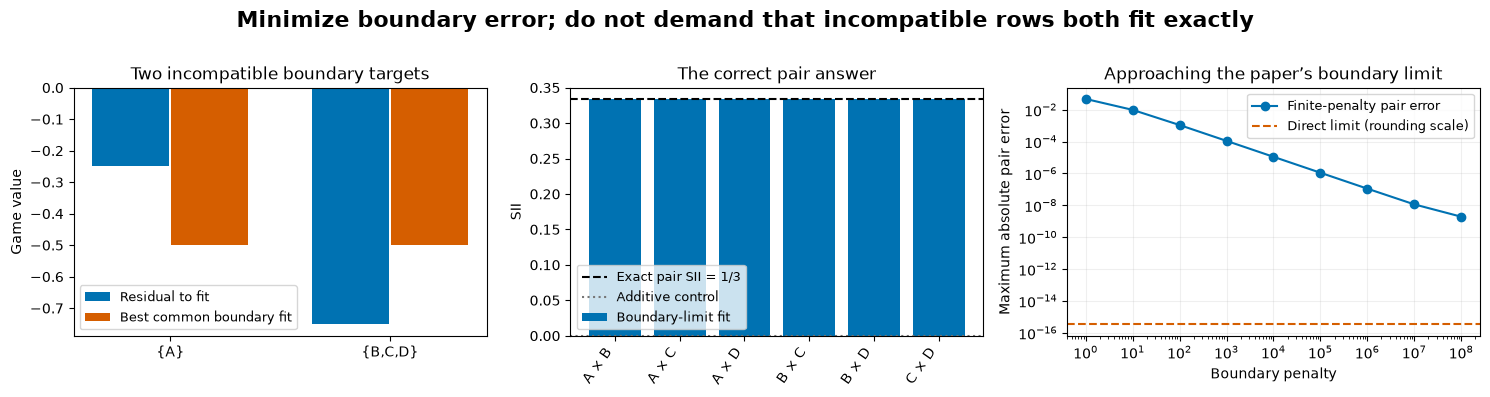

In [ ]:
estimator_figure = plots.plot_boundary_limit(kernelshap_iq)

estimator_show_figure(estimator_figure, '04_boundary_limit')

## Reflect after the result — estimator-32

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Interpretation - what do the finite-penalty curves establish?</summary>

They check the connection with the paper's limit: increasing the boundary weight approaches the same SII answer. They do not promise that larger numerical penalties are always safer. The direct limit avoids an ill-conditioned penalty scale; the rank diagnostic still matters when there are too few sampled interior directions.

</details>

## 4️⃣ Read the real-model comparison

## What is one query in this experiment?

For one held-out Concrete recipe, the game keeps the requested features and takes every absent feature from one intact training recipe. It averages predictions over 64 fixed donors. One coalition query therefore costs 64 underlying predictions; exact enumeration costs 256 coalition queries or 16,384 donor predictions per model/row.

We refit the same seven known predictors from 16.14/16.15 and require all 21 model-state identities to match. The 758 training rows, 153 explanation rows and 119 audit rows are split by recipe groups. Clean seeds, matched shuffled-label seeds and ridge all remain in the comparison.

For this repeated sampling benchmark, we construct the complete model-game oracle once. Each
estimator only receives its queried subset through your `query_sampled_game`. The complete table
and exact SII are available to the evaluator afterward. The figures compare **logical query
budgets**, not measured speedups over direct model calls. The up-front oracle cost is shown, and
it can dominate at eight features.

<details>
<summary>Why keep the exact table outside the estimator?</summary>

The reference must be able to measure all 28 errors even when a method queried only 34 distinct masks. Supplying the complete table directly to the estimator would make that budget meaningless. The query-wrapper tests alter all unqueried values and require both estimates to remain unchanged.

</details>

## Forecast before running — estimator-34

Before native model/game construction, forecast both estimators under both proposals and keep audit outcomes unopened.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
estimator_methods = estimator_SimpleNamespace(coalition_design=coalition_design, sii_query_weights=sii_query_weights, sample_coalitions=sample_coalitions, shapiq_estimate=shapiq_estimate, query_sampled_game=query_sampled_game, constrained_wls=constrained_wls, pair_residual_design=pair_residual_design, kernel_weights=kernel_weights, kernelshap_iq=kernelshap_iq)

## Reflect after the result — estimator-34

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

## Forecast before running — estimator-35

Commit sampling-budget comparisons; distinguish reference construction from logical oracle query counts.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.

In [ ]:
payload = study.run_study(estimator_methods, OUTPUT_DIR / 'native')

model_games = payload['games']

print('All 21 known model-state checks passed.')

print('Complete reference:', model_games['exact_reference_coalition_queries'], 'coalition queries;')

print(model_games['exact_reference_donor_predictions'], 'underlying donor predictions.')

source_zero = int(estimator_t.nonzero(model_games['source_ids'] == 0).item())

estimator_display(estimator_pd.DataFrame({'feature': model_games['feature_names'], 'source 0 recipe': model_games['queries'][source_zero].numpy(), 'first intact donor': model_games['donors'][0].numpy()}).set_index('feature'))

## Reflect after the result — estimator-35

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

## Read model quality before explanation size

## Forecast before running — estimator-37

Forecast model quality/ridge/shuffled controls without selecting models on audit outcomes.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


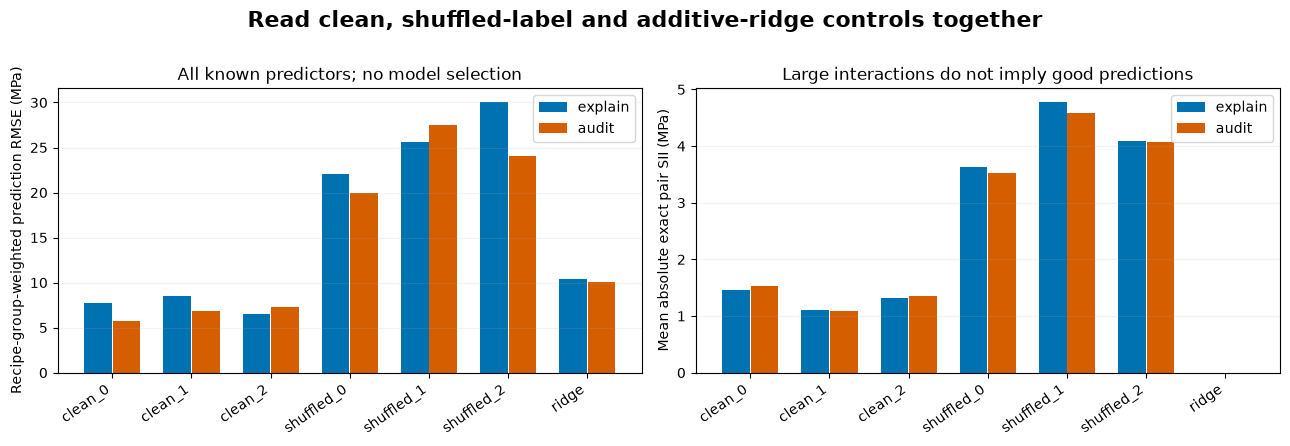

In [ ]:
estimator_figure = plots.plot_model_controls(payload)

estimator_show_figure(estimator_figure, '05_model_controls')

## Reflect after the result — estimator-37

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

The shuffled-label predictors are controls for learning useful predictive structure. They can still have nonzero interactions. Ridge is an additive model and its exact pair SII should be near rounding error. Finite SHAP-IQ may estimate nonzero ridge interactions because its sampled cancellation is imperfect; that is part of the comparison.

## How much error remains at each budget?

## Forecast before running — estimator-39

Forecast all four error-budget curves and identify32 paired sampling replicates, not independent row replicates.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


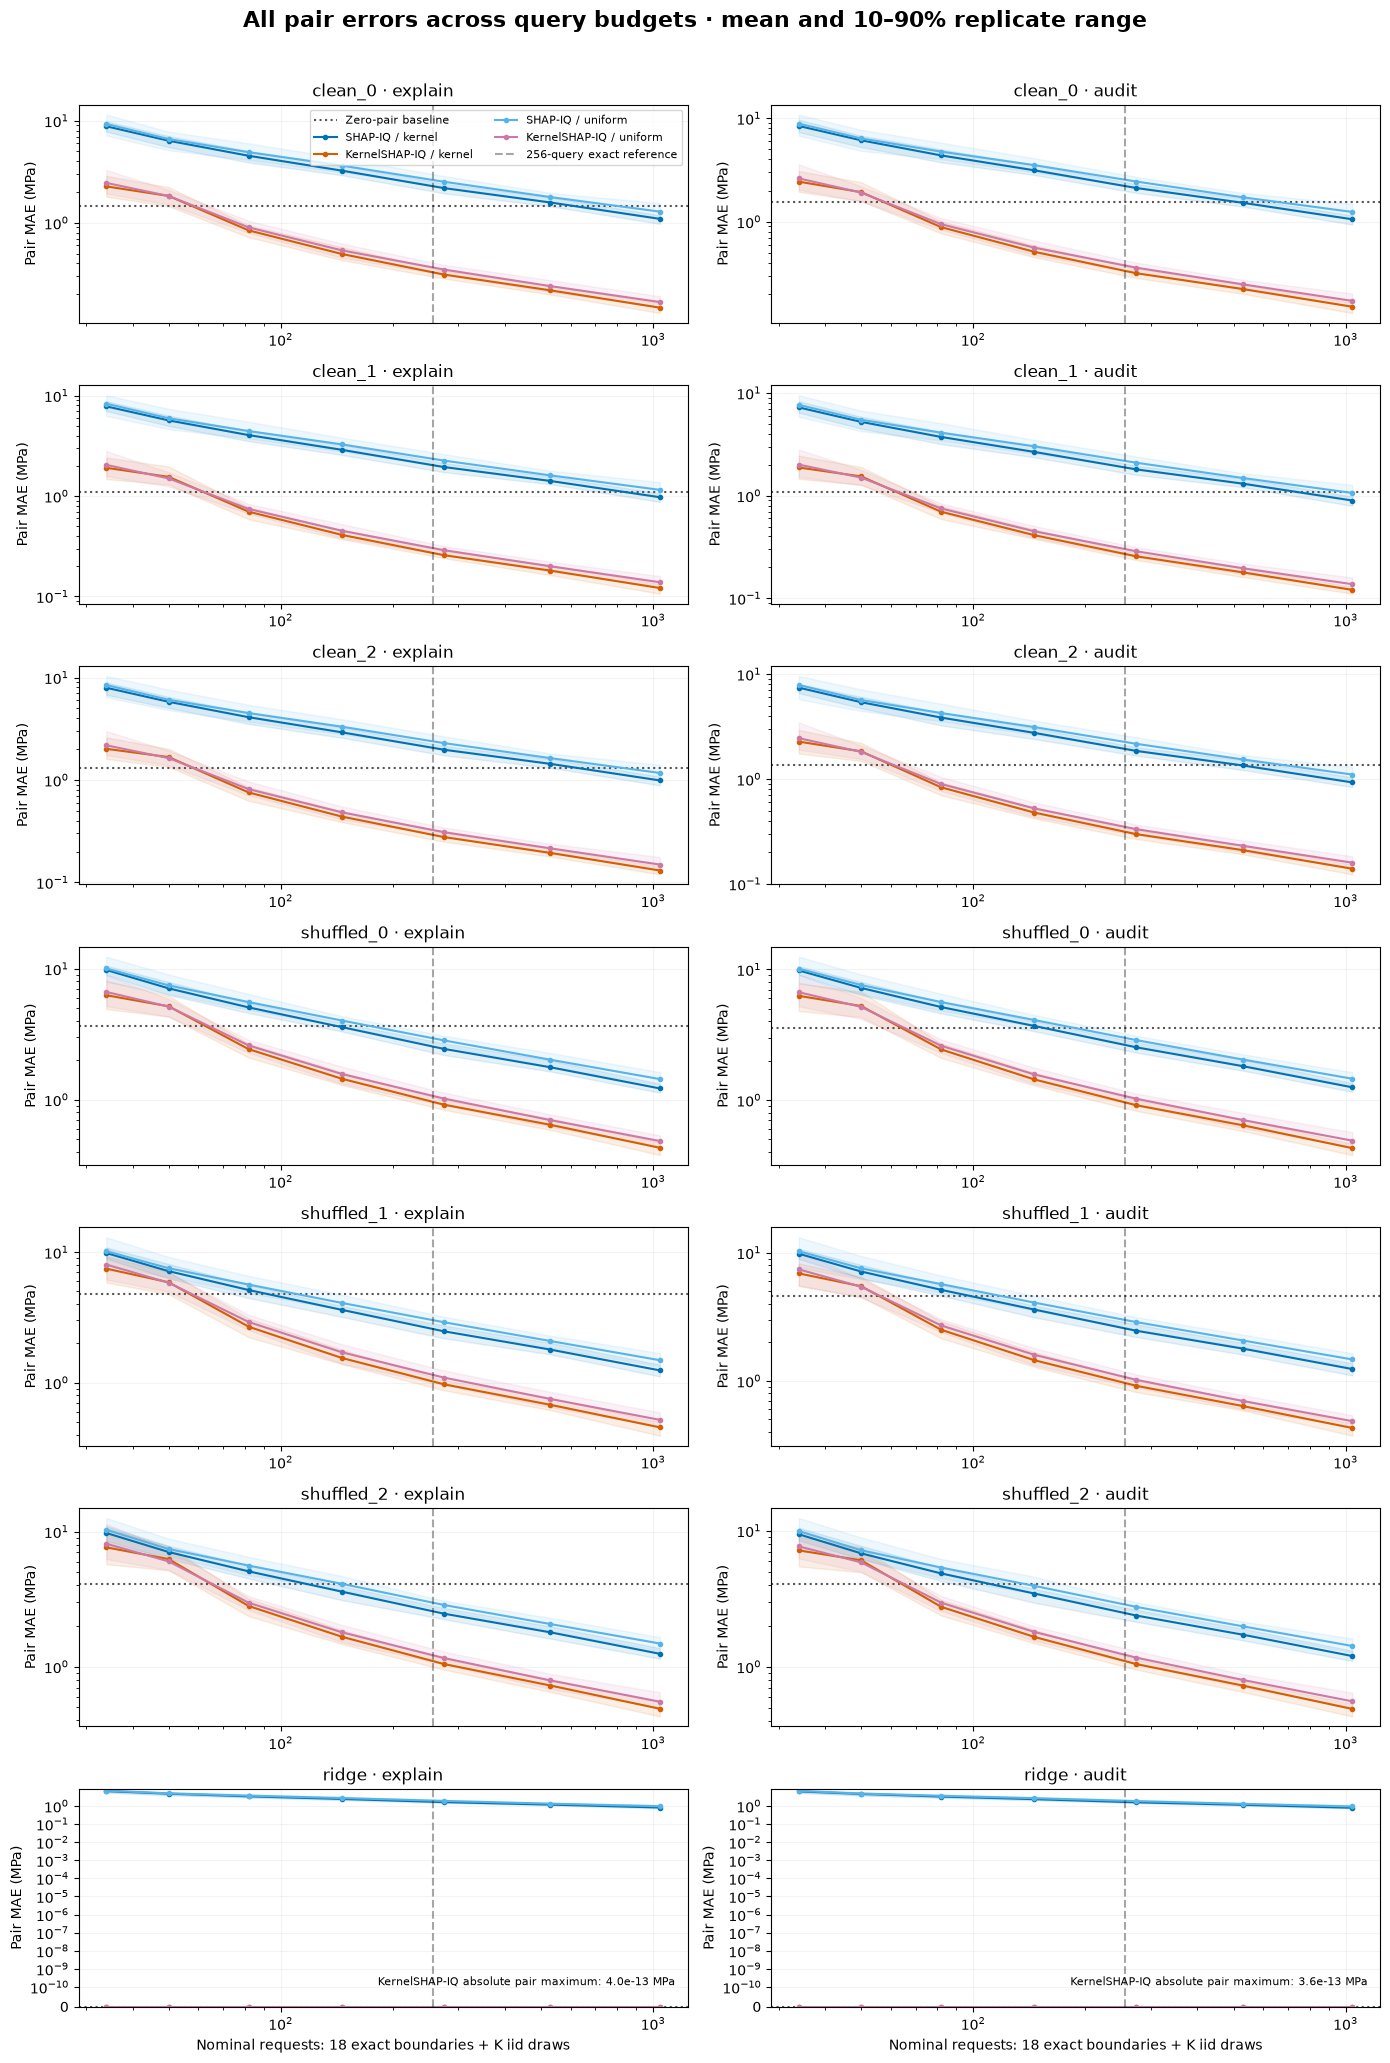

In [ ]:
estimator_figure = plots.plot_convergence(payload)

estimator_show_figure(estimator_figure, '06_query_budget_errors')

## Reflect after the result — estimator-39

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

Every line uses all rows of its indicated held-out split, weighting recipe groups equally before
averaging pair errors. Replicate variation comes from the 32 sampling streams. Those streams are
shared across rows, so rows are not counted as independent Monte Carlo replicates. All model
seeds and both sampling proposals remain visible. The zero-pair baseline shows the error of
doing no interaction estimation at all.

## Signed answers at the fixed recipe

## Forecast before running — estimator-41

Predict all28 signed pair values at the fixed source/model/replicate/budget, including near-zero pairs.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


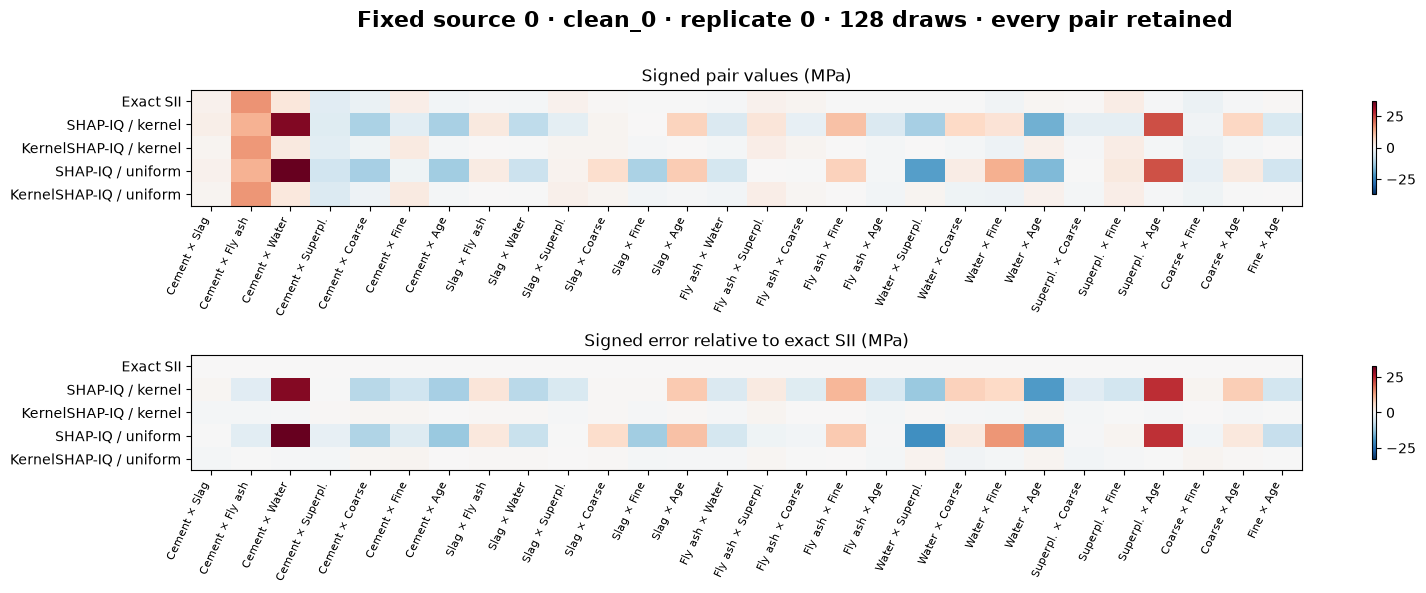

In [ ]:
estimator_figure = plots.plot_signed_comparison(payload)

estimator_show_figure(estimator_figure, '07_signed_pair_comparison')

## Reflect after the result — estimator-41

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

This view fixes the model, source row, replicate and budget before looking at results. Read the signed estimate alongside its error. An accurate mean across many pairs can conceal a wrong sign on one pair, while a single noisy replicate can look much worse than the aggregate curve.

## Does the reported sampling uncertainty mean what we think?

## Forecast before running — estimator-43

Compare exact variance/K, estimated SE squared and observed replicate errors before viewing them.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


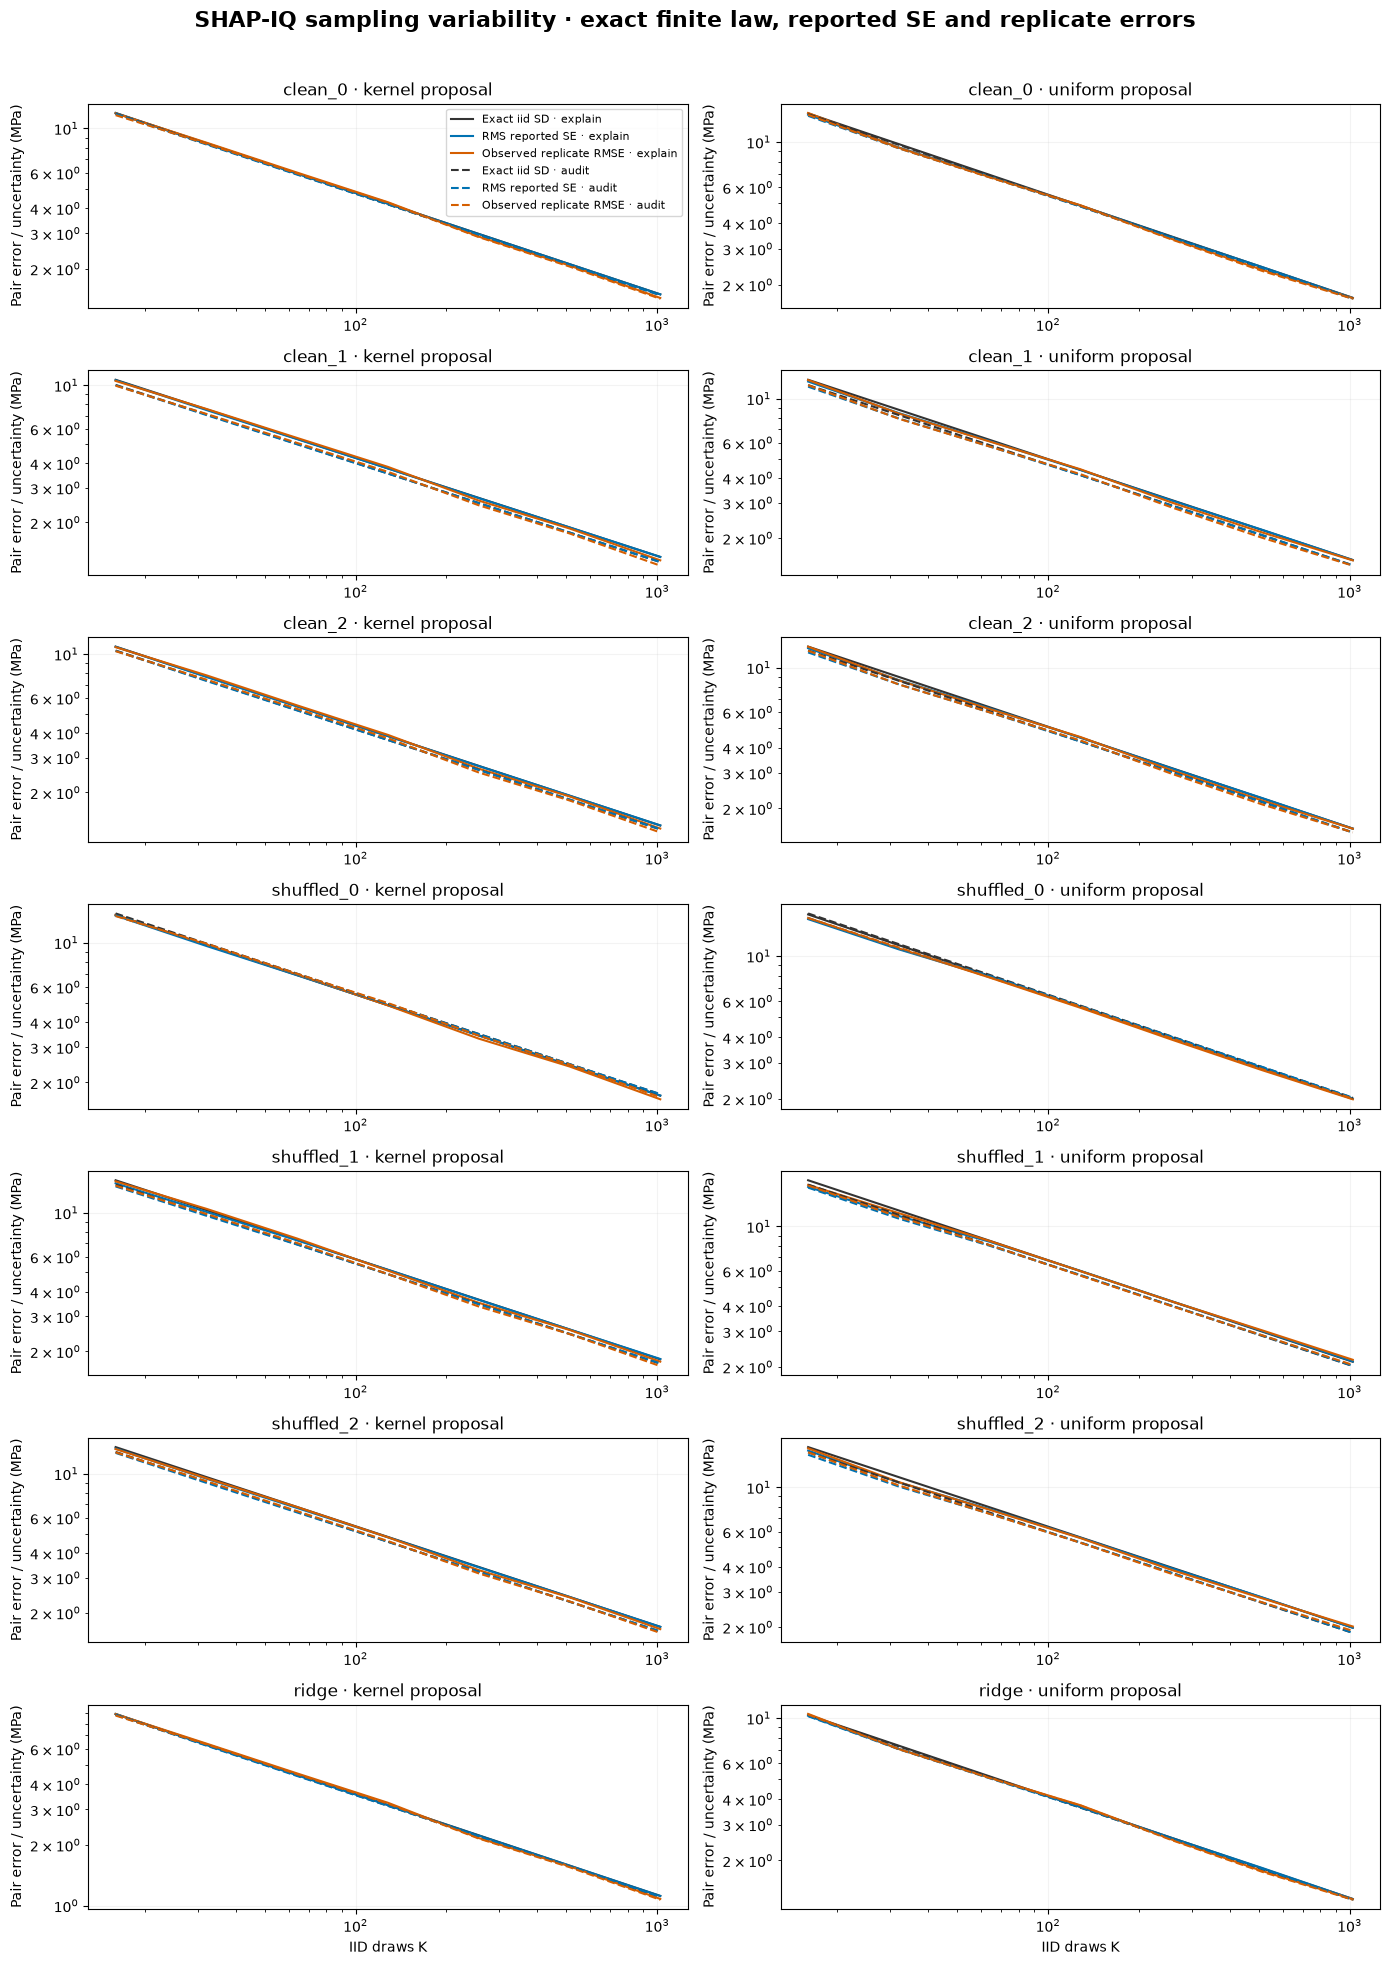

In [ ]:
estimator_figure = plots.plot_variance(payload)

estimator_show_figure(estimator_figure, '08_sampling_variance')

## Reflect after the result — estimator-43

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

Because this game is finite, we can enumerate the exact one-draw variance under each proposal and divide by `K`. Compare that prediction with average estimated SE squared and observed replicate squared errors. Their agreement is a sampling diagnostic. It does not give a confidence interval for concrete chemistry or for future model fits.

## Draws, unique queries and identified directions

## Forecast before running — estimator-45

Predict when more draws add few unique queries and how this affects free rank.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


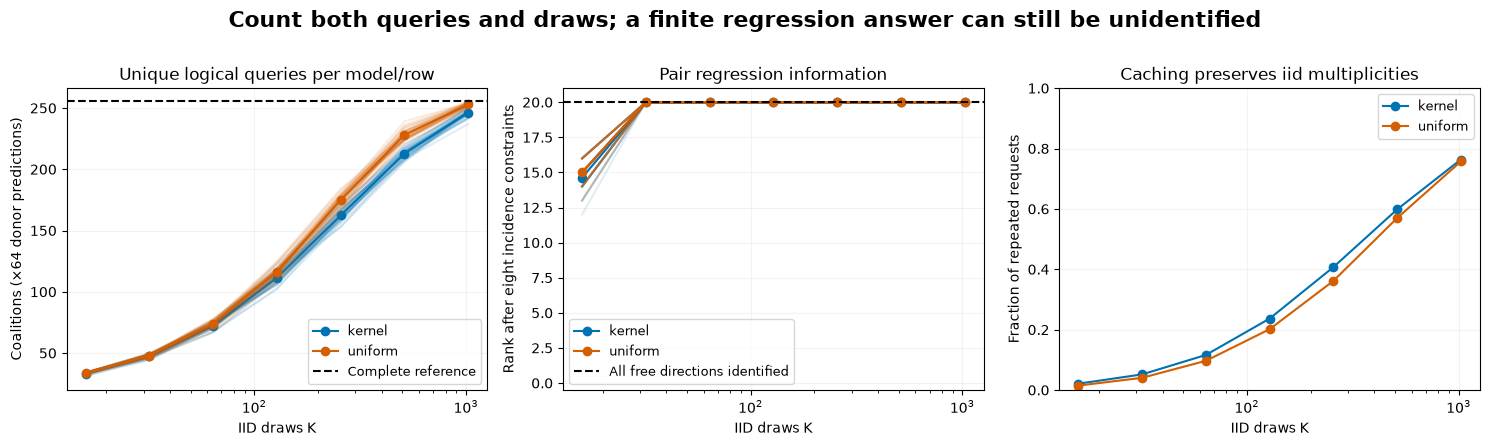

In [ ]:
estimator_figure = plots.plot_query_costs(payload)

estimator_show_figure(estimator_figure, '09_unique_queries_and_rank')

## Reflect after the result — estimator-45

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

Drawing a coalition twice increases the Monte Carlo sample count while the cache pays for its
model evaluation once. Keep both counts. After enough draws, the logical unique-query count
approaches 256; complete enumeration is then a serious alternative. The pair fit has twenty free
directions after its eight incidence constraints. A low-budget estimate can be rank deficient
even if the solver returns a finite coefficient vector.

## Try It Yourself: change the query budget

Change the recipe, model, proposal, seed or number of draws below. Predict which quantity should change: the target SII, the estimate, the reported uncertainty, or the cost. Changing only the seed leaves the target fixed. Changing the recipe or model changes the game. The result is exploratory and does not overwrite the fixed study.

## Forecast before running — estimator-47

Commit model/source/proposal/seed/budget edits and forecast signed error, cost and rank before exploratory reuse.

Commit a numeric interval, sign or ordering, confidence (0–100%), mechanism and possible disconfirming control. Record prior exposure (unseen/seen/unknown) before opening the reference result. Distinguish masks, donor predictions, recipe groups, contexts and sampling replicates; repeated views do not create independent examples. Leave the learner response blank until commitment.


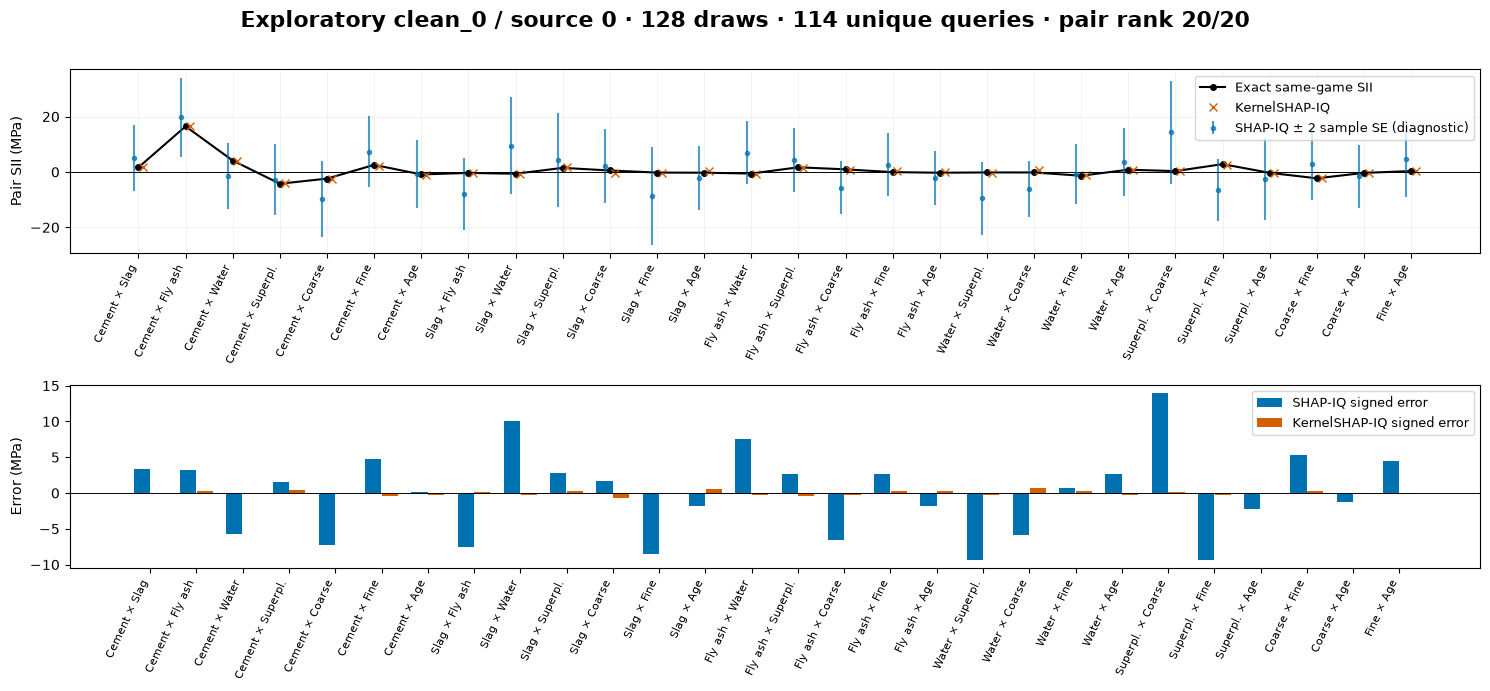

In [ ]:
estimator_MODEL_KEY = 'clean_0'

estimator_SOURCE_ID = 0

DRAWS = 128

SEED = 161750

PROPOSAL = 'kernel'

estimator_play = plots.make_native_play(payload, estimator_methods, model_key=estimator_MODEL_KEY, source_id=estimator_SOURCE_ID, draws=DRAWS, seed=SEED, proposal=PROPOSAL)

print('Unique queried masks:', estimator_play['receipt']['queried_masks'].tolist())

print('Pair free rank:', estimator_play['kernelshap_iq']['pair_stage']['free_rank'], '/ 20')

if estimator_play['exploratory_audit_reuse']:
    print('Exploratory audit reuse: this play does not change the fixed study.')

estimator_figure = plots.plot_native_play(estimator_play)

estimator_show_figure(estimator_figure, '10_native_query_play')

## Reflect after the result — estimator-47

Record observations with units, denominator, control values and exact source IDs/receipt where available. Distinguish your execution from the retained historical reference. Compare with your committed forecast, explain a discrepancy and forecast one changed condition before trying it. State what changed in the game/protocol. Historical reuse is guided exploration, not untouched evaluation.

<details>
<summary>Ideas to try</summary>

1. Keep `clean_0` and source row `0`, but switch proposals at the same draw budget. Inspect both the error and unique-query count.
2. Set the model to `ridge`. Compare its exact near-zero pairs with the finite SHAP-IQ error and the KernelSHAP-IQ rank diagnostic.
3. Reduce the budget until the pair fit loses free rank. A finite answer is not the same as an identified regression.
4. Change only the seed and find a case where one pair's sign changes. Compare the two estimates with exact SII before telling a feature-interaction story.

</details>

## Conclusion

One model response can update every pair once we rearrange the SII sum. SHAP-IQ estimates that shared sum directly; KernelSHAP-IQ fits main effects and pair residuals to the same queries. They can differ at a finite budget while targeting the same exact interaction index.

You have also seen three distinct limits: finite sampling leaves noise, incomplete designs leave unidentified directions, and an exact interaction remains a property of a chosen fitted model and replacement game. The eight-feature experiment makes those limits measurable. It does not establish large-feature scalability or physical causal interactions.

## Further reading

- [SHAP-IQ: Unified Approximation of any-order Shapley Interactions](https://proceedings.neurips.cc/paper_files/paper/2023/file/264f2e10479c9370972847e96107db7f-Paper-Conference.pdf), especially the shared-query representation and iid estimator in Section 4.
- [KernelSHAP-IQ: Weighted Least Square Optimization for Shapley Interactions](https://proceedings.mlr.press/v235/fumagalli24a.html), especially the pairwise theorem and sequential algorithm. The higher-order WLS results include conjectures; this lesson uses the proved pairwise case.
- Section 16.3 for the discrete-derivative SII definition; 16.16 for changing the allocation rule instead of approximating a fixed one.
- Sections 16.14–16.15 for the known Concrete model/data recipe and finite-donor interpretation.

## Study conclusion — estimator

State the target interaction definition, experiment, denominator and negative controls before comparing this track with the other two. Preserve any disagreement as evidence about distinct questions.

# ☆ Bonus

## Design a comparison before changing the experiment

Compare a contextual derivative, an efficient allocation and a sampling estimate of pair SII. Explain which differences reflect the target game/definition and which reflect sampling error. Propose a single changed condition with a falsifiable forecast. All historical controls, unfavorable results and complete study scopes remain part of the lesson.